<a href="https://colab.research.google.com/github/tassid/relacoes_fisicas_ambiente/blob/main/codigos_python/projeto_01_sudoeste.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 1 · Elementos meteorológicos
### Radiação solar, saldo de radiação e ETo no Sudoeste do Paraná

**Disciplina:** PPGTCA-TCA26 · Relações Físicas do Ambiente Agrícola (PPGTCA/UTFPR) · **Entrega:** 09/11/2026 · **Peso:** 30%

O projeto reproduz dois artigos e depois os integra, para municípios do Sudoeste do Paraná:

```
     Fernandes et al. (2018)              Fietz & Fisch (2009)
  ┌──────────────────────────┐     ┌───────────────────────────────┐
  │ Tmax, Tmin  ──►  Qg      │ ──► │ Qg ──► Rn ──► ETo (Priestley- │
  │ (5 modelos empíricos)    │     │       (4 modelos)    Taylor)  │
  └──────────────────────────┘     └───────────────────────────────┘
```

> **Pergunta central:** se eu tiver apenas termômetro, quanto erro carrego até a ETo? E em que elo da cadeia esse erro nasce?

| Etapa | Conteúdo |
|---|---|
| 0 | Locais de estudo e caracterização dos municípios |
| 1 | Extração do BR-DWGD (Xavier et al.), controle de qualidade e climatologia |
| 1b | Validação da base com a estação meteorológica (opcional, depende dos arquivos da estação) |
| 2 | Variáveis astronômicas e balanço de radiação (FAO-56) |
| 3 | Modelos de Qg a partir da temperatura (Fernandes et al., 2018) |
| 4 | Modelos de Rn e Priestley-Taylor (Fietz & Fisch, 2009) |
| 5 | Integração: temperatura → Qg → Rn → ETo |
| 6 | Complemento: El Niño-Oscilação Sul (pergunta agroclimática do grupo) |
| 7 | Complemento: previsão de chuva para os próximos 15 dias (ECMWF IFS) |
| 8 | Síntese dos resultados e tabelas do relatório |

Calibração com os **anos ímpares** e validação com os **anos pares** (2001 a 2025).

> Nas equações, **Qg** é a irradiância solar global (no BR-DWGD, banda `Rs`).

## Configuração do ambiente
___

In [1]:
!pip install -q agrometeorologiapy

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.interpolate import UnivariateSpline
from scipy import stats
import agrometeorologiapy as amp

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 70          # figuras leves no notebook; os PNG salvos saem com 200 dpi

# ID do projeto do Google Cloud registrado no Earth Engine (só é usado se a base ainda não estiver salva)
ID_PROJETO = 'ppgtca-relacoes-fisicas'

# True: salva tudo no Google Drive (recomendado no Colab, evita repetir a extração)
USAR_DRIVE = True

In [3]:
PASTA_RAIZ = '.'
if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PASTA_RAIZ = '/content/drive/MyDrive/RFAA_P1_sudoeste'
    except ImportError:
        print('Fora do Colab: os arquivos ficam na pasta atual.')

PASTA_DADOS = os.path.join(PASTA_RAIZ, 'dados')
PASTA_FIGURAS = os.path.join(PASTA_RAIZ, 'figuras')
PASTA_RESULTADOS = os.path.join(PASTA_RAIZ, 'resultados')
for p in (PASTA_DADOS, PASTA_FIGURAS, PASTA_RESULTADOS):
    os.makedirs(p, exist_ok=True)
print('Arquivos em:', os.path.abspath(PASTA_RAIZ))

Arquivos em: /tmp/claude-0/-home-user-relacoes-fisicas-ambiente/4f9e1bc9-1477-5607-83a4-040dff73a459/scratchpad/run_final


In [4]:
_EE = {'ok': False}


def conecta_ee():
    # Conecta ao Earth Engine só quando algum dado ainda não está salvo em disco
    import ee
    if not _EE['ok']:
        ee.Authenticate()
        ee.Initialize(project=ID_PROJETO)
        _EE['ok'] = True
        print('Earth Engine conectado:', ID_PROJETO)
    return ee


PREFIXO_FIG = 'etapa7_'   # prefixo dos arquivos da Etapa 7


def grade(n, ncols=5, larg=3.4, alt=3.0, **kw):
    # Grade de painéis para n locais (10 locais: 2 linhas x 5 colunas); devolve a figura e a lista de eixos
    ncols = min(ncols, n)
    nlin = int(np.ceil(n / ncols))
    fig, eixos = plt.subplots(nlin, ncols, figsize=(larg * ncols, alt * nlin), squeeze=False, **kw)
    eixos = eixos.ravel()
    for ax in eixos[n:]:
        ax.axis('off')
    return fig, eixos[:n]


def mapa_calor(ax, tab, fmt='{:.2f}', cmap='RdYlGn', vmin=None, vmax=None, titulo=None, barra='', fonte=8):
    # Mapa de calor de uma tabela (linhas x colunas) com o valor escrito em cada célula
    v = tab.values.astype(float)
    im = ax.imshow(v, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index, fontsize=8)
    lo, hi = np.nanmin(v), np.nanmax(v)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isfinite(v[i, j]):
                claro = (v[i, j] - lo) / (hi - lo + 1e-12)
                ax.text(j, i, fmt.format(v[i, j]), ha='center', va='center', fontsize=fonte,
                        color='white' if (claro < 0.15 or claro > 0.85) else 'black')
    if titulo:
        ax.set_title(titulo, fontsize=10)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label(barra, fontsize=8); cb.ax.tick_params(labelsize=7)
    return im


def salva_fig(nome):
    plt.savefig(os.path.join(PASTA_FIGURAS, nome), dpi=200, bbox_inches='tight')
    plt.show()
    plt.close('all')

## Etapa 0 · Locais de estudo
___

Municípios do Sudoeste do Paraná, no Terceiro Planalto (basalto), na transição entre os climas **Cfa** e **Cfb** (Alvares et al., 2013). É a mesma região do trabalho da Aula 01. A análise apresentada usa os **três municípios com estação de referência**; com `USAR_DEZ_MUNICIPIOS = True` (célula abaixo) ela passa a **dez municípios**, como sugerido em aula (Fernandes et al., 2018, usaram 10 locais). Os municípios cobrem a região de oeste a leste e formam um gradiente de altitude, o que permite discutir a variação dentro da região e testar se coeficientes calibrados em um local servem para os vizinhos.

**Ponto de análise.** Onde há estação meteorológica de referência, a série é extraída no ponto da estação:

| Município | Estação de referência | Ponto (lat, lon) |
|---|---|---|
| Pato Branco | IDR-Paraná (antigo IAPAR), 26°07' S, 52°41' O | −26,117; −52,683 |
| Francisco Beltrão | IDR-Paraná (antigo IAPAR), 26°05' S, 53°04' O | −26,083; −53,067 |
| Dois Vizinhos | INMET A843 (automática) | −25,699; −53,095 |

Nos outros sete municípios, o ponto é o **centroide do limite municipal** (FAO/GAUL), calculado no Earth Engine. Em todos, a altitude usada nos cálculos é a do SRTM (30 m) no próprio ponto. Os pontos ficam salvos em `dados/pontos_locais.csv`; se o arquivo existir, o Earth Engine não é consultado de novo. O pixel do BR-DWGD tem 0,1° (cerca de 11 km).

In [5]:
import unicodedata


def _sem_acento(t):
    return unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode().lower().strip()


# Municípios do Sudoeste: os três primeiros têm estação de referência; nos demais o ponto é o centroide do município
LOCAIS = [
    {'municipio': 'Pato Branco',               'sigla': 'PB',  'estacao': 'IDR-Paraná (Pato Branco)',       'lat': -26.117, 'lon': -52.683},
    {'municipio': 'Francisco Beltrão',         'sigla': 'FB',  'estacao': 'IDR-Paraná (Francisco Beltrão)', 'lat': -26.083, 'lon': -53.067},
    {'municipio': 'Dois Vizinhos',             'sigla': 'DV',  'estacao': 'INMET A843',                     'lat': -25.699, 'lon': -53.095},
    {'municipio': 'Capanema',                  'sigla': 'CAP', 'estacao': None},
    {'municipio': 'Realeza',                   'sigla': 'REA', 'estacao': None},
    {'municipio': 'Ampére',                    'sigla': 'AMP', 'estacao': None},
    {'municipio': 'Santo Antônio do Sudoeste', 'sigla': 'SAS', 'estacao': None},
    {'municipio': 'Marmeleiro',                'sigla': 'MAR', 'estacao': None},
    {'municipio': 'Coronel Vivida',            'sigla': 'CV',  'estacao': None},
    {'municipio': 'Chopinzinho',               'sigla': 'CHO', 'estacao': None},
]

# False: só os três municípios com estação (versão apresentada, com os dados já extraídos)
# True: os dez municípios; na primeira execução os sete novos são extraídos do Earth Engine (cerca de 15 a 20 min)
USAR_DEZ_MUNICIPIOS = False
if not USAR_DEZ_MUNICIPIOS:
    LOCAIS = [l for l in LOCAIS if l['estacao']]

ANO_INICIO, ANO_FIM = 2001, 2025
N_ANOS = ANO_FIM - ANO_INICIO + 1
PERIODO = f'{ANO_INICIO} a {ANO_FIM}'
ARQ_PONTOS = os.path.join(PASTA_DADOS, 'pontos_locais.csv')


def nomes_gaul():
    # Nome de cada município na base FAO/GAUL (sem acento), achado pela comparação sem acento e sem maiúsculas
    ee = conecta_ee()
    todos = (ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM1_NAME', 'Parana'))
             .aggregate_array('ADM2_NAME').getInfo())
    por_chave = {_sem_acento(n): n for n in todos}
    faltam = [l['municipio'] for l in LOCAIS if _sem_acento(l['municipio']) not in por_chave]
    if faltam:
        raise ValueError(f'Não achei no FAO/GAUL: {faltam}. Confira a grafia; nomes do Paraná: {sorted(todos)}')
    return {l['municipio']: por_chave[_sem_acento(l['municipio'])] for l in LOCAIS}


def define_pontos():
    # Ponto de cada local (estação ou centroide do município) e altitude do SRTM nesse ponto
    ee = conecta_ee()
    gaul = nomes_gaul()
    municipios = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM1_NAME', 'Parana'))
    srtm = ee.Image('USGS/SRTMGL1_003')
    linhas = []
    for l in LOCAIS:
        if l.get('lat') is None:
            c = municipios.filter(ee.Filter.eq('ADM2_NAME', gaul[l['municipio']])).geometry().centroid(1).coordinates().getInfo()
            lon, lat, origem = c[0], c[1], 'centroide do município'
        else:
            lon, lat, origem = l['lon'], l['lat'], 'estação'
        alt = srtm.sample(ee.Geometry.Point([lon, lat]), 30).first().get('elevation').getInfo()
        linhas.append({'Município': l['municipio'], 'Nome GAUL': gaul[l['municipio']], 'Latitude (°)': round(lat, 4),
                       'Longitude (°)': round(lon, 4), 'Altitude do ponto (m)': float(alt), 'Origem do ponto': origem})
    return pd.DataFrame(linhas).set_index('Município')


PONTOS = pd.read_csv(ARQ_PONTOS, index_col='Município') if os.path.exists(ARQ_PONTOS) else None
if PONTOS is None or not set(l['municipio'] for l in LOCAIS) <= set(PONTOS.index):
    PONTOS = define_pontos()
    PONTOS.to_csv(ARQ_PONTOS)

for l in LOCAIS:
    p = PONTOS.loc[l['municipio']]
    l['lat'], l['lon'], l['altitude_m'] = float(p['Latitude (°)']), float(p['Longitude (°)']), float(p['Altitude do ponto (m)'])
    l['uf'] = 'PR'
    l['estacao'] = l['estacao'] or 'sem estação (centroide)'

NOMES = [l['municipio'] for l in LOCAIS]
LOCAL = {l['municipio']: l for l in LOCAIS}
SLUG = {n: _sem_acento(n).replace(' ', '_') for n in NOMES}
SIGLA = {l['municipio']: l['sigla'] for l in LOCAIS}
NOME_GAUL = PONTOS['Nome GAUL'].to_dict()
MESES_ABREV = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
CORES_LOCAL = {n: plt.cm.tab10(i % 10) for i, n in enumerate(NOMES)}

tabela1 = pd.DataFrame([{
    'Município': l['municipio'], 'Sigla': l['sigla'], 'UF': l['uf'], 'Ponto': l['estacao'],
    'Latitude (°)': l['lat'], 'Longitude (°)': l['lon'], 'Altitude do ponto (m)': l['altitude_m'],
    'Período': PERIODO, 'N anos': N_ANOS,
} for l in LOCAIS]).set_index('Município')
tabela1

,Sigla,UF,Ponto,Latitude (°),Longitude (°),Altitude do ponto (m),Período,N anos
Município,,,,,,,,
Pato Branco,PB,PR,IDR-Paraná (Pato Branco),-26.117,-52.683,702.0,2001 a 2025,25
Francisco Beltrão,FB,PR,IDR-Paraná (Francisco Beltrão),-26.083,-53.067,584.0,2001 a 2025,25
Dois Vizinhos,DV,PR,INMET A843,-25.699,-53.095,545.0,2001 a 2025,25


**Caracterização dos municípios** (continuação da Aula 01): limite municipal (FAO/GAUL), área, altitude (SRTM 30 m) e chuva anual média (CHIRPS diário, 2001 a 2025). O resultado fica salvo em `dados/etapa0_caracterizacao.csv`; se o arquivo existir, o Earth Engine não é consultado de novo.

In [6]:
ARQ_ETAPA0 = os.path.join(PASTA_DADOS, 'etapa0_caracterizacao.csv')


def caracteriza_municipios():
    ee = conecta_ee()
    municipios = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM1_NAME', 'Parana'))
    srtm = ee.Image('USGS/SRTMGL1_003')
    chirps_anual = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
                    .filterDate(f'{ANO_INICIO}-01-01', f'{ANO_FIM + 1}-01-01').sum().divide(N_ANOS))
    linhas = []
    for l in LOCAIS:
        geom = municipios.filter(ee.Filter.eq('ADM2_NAME', NOME_GAUL[l['municipio']])).geometry()
        alt = srtm.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.minMax(), '', True), geom, 30, maxPixels=1e9).getInfo()
        linhas.append({
            'Município': l['municipio'],
            'Área (km²)': geom.area(1).divide(1e6).getInfo(),
            'Altitude média (m)': alt['elevation_mean'],
            'Altitude mínima (m)': alt['elevation_min'],
            'Altitude máxima (m)': alt['elevation_max'],
            'Chuva anual CHIRPS (mm)': chirps_anual.reduceRegion(ee.Reducer.mean(), geom, 5566, maxPixels=1e9).get('precipitation').getInfo(),
        })
    return pd.DataFrame(linhas).set_index('Município')


etapa0 = pd.read_csv(ARQ_ETAPA0, index_col='Município') if os.path.exists(ARQ_ETAPA0) else None
if etapa0 is None or set(etapa0.index) != set(NOMES):
    etapa0 = caracteriza_municipios()
    etapa0.to_csv(ARQ_ETAPA0)

tabela1 = tabela1.join(etapa0)
tabela1.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa0_tabela1_locais.csv'))
tabela1.round(1)

,Sigla,UF,Ponto,Latitude (°),Longitude (°),Altitude do ponto (m),Período,N anos,Área (km²),Altitude média (m),Altitude mínima (m),Altitude máxima (m),Chuva anual CHIRPS (mm)
Município,,,,,,,,,,,,,
Pato Branco,PB,PR,IDR-Paraná (Pato Branco),-26.1,-52.7,702.0,2001 a 2025,25,540.0,709.1,476,927,1910.6
Francisco Beltrão,FB,PR,IDR-Paraná (Francisco Beltrão),-26.1,-53.1,584.0,2001 a 2025,25,719.0,656.2,468,957,1965.8
Dois Vizinhos,DV,PR,INMET A843,-25.7,-53.1,545.0,2001 a 2025,25,418.9,528.1,357,716,1908.8


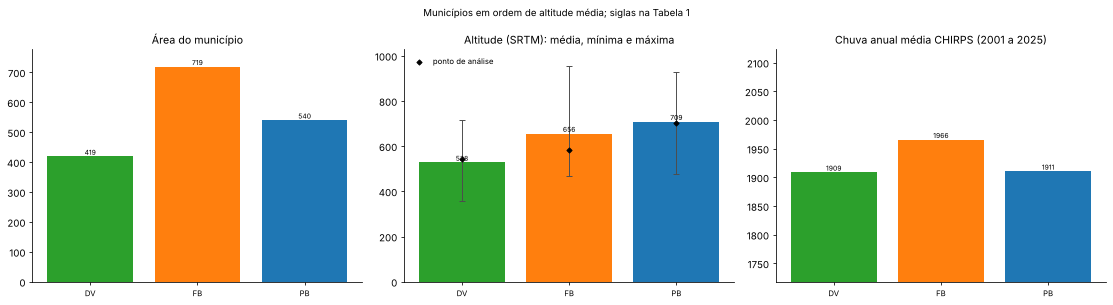

In [7]:
# Caracterização dos municípios, em ordem de altitude média
ordem = tabela1.sort_values('Altitude média (m)').index
sig = [SIGLA[n] for n in ordem]
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.4))
paineis = [('Área (km²)', 'Área do município', '{:.0f}'),
           ('Altitude média (m)', 'Altitude (SRTM): média, mínima e máxima', '{:.0f}'),
           ('Chuva anual CHIRPS (mm)', f'Chuva anual média CHIRPS ({PERIODO})', '{:.0f}')]
x = np.arange(len(ordem))
for ax, (col, titulo, fmt) in zip(eixos, paineis):
    v = tabela1.loc[ordem, col].values
    barras = ax.bar(x, v, color=[CORES_LOCAL[n] for n in ordem])
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()), ha='center', va='bottom', fontsize=7)
    if col == 'Altitude média (m)':
        ax.errorbar(x, v, yerr=[v - tabela1.loc[ordem, 'Altitude mínima (m)'].values, tabela1.loc[ordem, 'Altitude máxima (m)'].values - v],
                    fmt='none', ecolor='0.3', capsize=3, lw=1)
        ax.scatter(x, tabela1.loc[ordem, 'Altitude do ponto (m)'].values, marker='D', color='k', zorder=3, s=14, label='ponto de análise')
        ax.legend(frameon=False, fontsize=8, loc='upper left')
    ax.set_xticks(x); ax.set_xticklabels(sig, fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.set_ylim(min(v) * 0.9 if col == 'Chuva anual CHIRPS (mm)' else 0, max(v) * (1.45 if col == 'Altitude média (m)' else 1.08))
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Municípios em ordem de altitude média; siglas na Tabela 1', fontsize=10)
plt.tight_layout()
salva_fig('etapa0_caracterizacao.png')

**Mapa interativo** (opcional). Só roda quando o Earth Engine está conectado; no Colab, rode `conecta_ee()` antes. Fora disso a célula é pulada e o restante do notebook não depende dela.

In [8]:
MOSTRAR_MAPA = _EE['ok']
if MOSTRAR_MAPA:
    import ee
    import geemap
    municipios = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM1_NAME', 'Parana'))
    mapa = geemap.Map()
    for l in LOCAIS:
        area = municipios.filter(ee.Filter.eq('ADM2_NAME', NOME_GAUL[l['municipio']]))
        cor = '#%02x%02x%02x' % tuple(int(255 * c) for c in CORES_LOCAL[l['municipio']][:3])
        mapa.addLayer(ee.Image().paint(area, 0, 3), {'palette': [cor]}, l['municipio'])
        mapa.addLayer(ee.Geometry.Point([l['lon'], l['lat']]), {'color': 'black'}, f"Ponto {l['municipio']}")
    mapa.setCenter(-52.95, -25.95, 9)
    display(mapa)
else:
    print('Mapa interativo pulado (Earth Engine não conectado nesta execução).')

Mapa interativo pulado (Earth Engine não conectado nesta execução).


## Etapa 1 · Extração do BR-DWGD e controle de qualidade
___

**Estratégia de extração.** A coleção `projects/ee-alexandrexavier/assets/BR-DWGD` tem uma imagem por dia (1961 a 2025). Pedir 25 anos de uma vez (mais de 9 mil imagens) estoura o limite de elementos do `getRegion`. Por isso a extração é feita **ano a ano** (25 chamadas por local) e o resultado é salvo em CSV: se o arquivo já existir em `dados/`, o notebook apenas o lê.

**Fator de escala.** As bandas estão gravadas como inteiros. Cada imagem traz as propriedades `BAND_<banda>_MULT` e `BAND_<banda>_ADD`, e o valor real é `valor = bruto · MULT + ADD`.

In [9]:
ASSET_XAVIER = 'projects/ee-alexandrexavier/assets/BR-DWGD'
BANDAS = ['pr', 'Tmax', 'Tmin', 'RH', 'u2', 'Rs', 'ET']   # ET = ETo Penman-Monteith do próprio BR-DWGD


def fatores_escala():
    # Lê MULT e ADD de cada banda nas propriedades da primeira imagem
    ee = conecta_ee()
    props = ee.ImageCollection(ASSET_XAVIER).first().toDictionary().getInfo()
    return {b: (props[f'BAND_{b}_MULT'], props[f'BAND_{b}_ADD']) for b in BANDAS}


def extrai_local(local):
    # Extrai a série diária do BR-DWGD no ponto, um ano por vez
    ee = conecta_ee()
    col = ee.ImageCollection(ASSET_XAVIER).select(BANDAS)
    ponto = ee.Geometry.Point([local['lon'], local['lat']])
    fatores = fatores_escala()
    partes = []
    for ano in range(ANO_INICIO, ANO_FIM + 1):
        linhas = col.filterDate(f'{ano}-01-01', f'{ano + 1}-01-01').getRegion(ponto, 10000).getInfo()
        partes.append(pd.DataFrame(linhas[1:], columns=linhas[0]))
        print(f"  {local['municipio']}: {ano} ok", end='\r')
    bruto = pd.concat(partes, ignore_index=True)
    serie = pd.DataFrame({'data': pd.to_datetime(bruto['time'], unit='ms').dt.normalize()})
    for b in BANDAS:
        mult, add = fatores[b]
        serie[b] = bruto[b].astype(float) * mult + add
    return serie.drop_duplicates('data').set_index('data').sort_index()


def carrega_local(local):
    arq = os.path.join(PASTA_DADOS, f"brdwgd_{SLUG[local['municipio']]}_{ANO_INICIO}_{ANO_FIM}.csv")
    if os.path.exists(arq):
        return pd.read_csv(arq, index_col='data', parse_dates=True)
    serie = extrai_local(local)
    serie.to_csv(arq)
    print(f"\n  salvo em {arq}")
    return serie


BRUTO = {l['municipio']: carrega_local(l) for l in LOCAIS}
for nome, s in BRUTO.items():
    print(f'{nome:<18} {len(s)} dias  ({s.index.min():%d/%m/%Y} a {s.index.max():%d/%m/%Y})')

Pato Branco        9131 dias  (01/01/2001 a 31/12/2025)
Francisco Beltrão  9131 dias  (01/01/2001 a 31/12/2025)
Dois Vizinhos      9131 dias  (01/01/2001 a 31/12/2025)


In [10]:
# Estatística descritiva da base bruta (média, desvio, mínimo e máximo de cada variável)
desc = pd.concat({n: BRUTO[n][BANDAS].describe().loc[['mean', 'std', 'min', 'max']].T for n in NOMES}, axis=1)
desc.round(2)

Pato Branco                       Francisco Beltrão                       Dois Vizinhos                      
            mean    std    min     max              mean    std    min     max          mean    std    min     max
pr          5.06  11.94   0.00  142.02              5.33  12.66   0.00  153.69          5.17  12.10   0.00  180.20
Tmax       25.90   4.77   7.29   37.23             26.03   4.85   7.16   37.42         26.33   4.86   7.10   37.56
Tmin       15.45   4.32  -1.61   24.50             15.55   4.35  -1.67   24.41         15.14   4.34  -2.24   24.31
RH         75.31  11.56  34.65   99.21             74.88  11.88  34.65   98.82         74.79  11.70  33.86   98.82
u2          1.93   0.73   0.35    5.02              1.99   0.68   0.35    5.02          1.95   0.68   0.35    4.96
Rs         16.78   7.07   0.89   33.40             16.94   7.17   0.73   33.40         16.96   7.09   0.89   33.40
ET          3.46   1.55   0.41    7.88              3.52   1.59   0.46    8.14          3.54   1.57   0.46    8.50

**Controle de qualidade.** Para cada variável, valores fora de uma faixa plausível viram falha. Há também duas checagens físicas: Tmin > Tmax (as duas temperaturas são descartadas) e Qg > Qo (Qg é descartada). Qo é calculada aqui e reaproveitada na Etapa 2.

In [11]:
FAIXAS = {'pr': (0, 300), 'Tmax': (-5, 45), 'Tmin': (-10, 35), 'RH': (0, 100),
          'u2': (0, 20), 'Rs': (0, 40), 'ET': (0, 12)}


def astronomicas(df, lat):
    nda = df.index.dayofyear.values
    dec = amp.declinacao_solar(nda)
    Hn = amp.angulo_horario_nascer(lat, dec)
    df['Qo'] = amp.irradiancia_extraterrestre(lat, dec, Hn, amp.fator_correcao_distancia(nda))
    df['N'] = amp.fotoperiodo(Hn)
    return df


def controle_qualidade(serie, lat):
    df = astronomicas(serie.copy(), lat)
    falhas = {'Dias na série': len(df), 'Dias ausentes no calendário': int(len(pd.date_range(f'{ANO_INICIO}-01-01', f'{ANO_FIM}-12-31')) - len(df))}
    for v, (lo, hi) in FAIXAS.items():
        fora = ~df[v].between(lo, hi) & df[v].notna()
        falhas[f'{v} fora da faixa'] = int(fora.sum())
        df.loc[fora, v] = np.nan
    inv_t = df['Tmin'] > df['Tmax']
    inv_r = df['Rs'] > df['Qo']
    falhas['Tmin > Tmax'] = int(inv_t.sum())
    falhas['Qg > Qo'] = int(inv_r.sum())
    df.loc[inv_t, ['Tmax', 'Tmin']] = np.nan
    df.loc[inv_r, 'Rs'] = np.nan
    falhas['Dias com alguma falha'] = int(df[BANDAS].isna().any(axis=1).sum())
    return df, falhas


SERIES, relatorio_qc = {}, {}
for l in LOCAIS:
    SERIES[l['municipio']], relatorio_qc[l['municipio']] = controle_qualidade(BRUTO[l['municipio']], l['lat'])

tabela_qc = pd.DataFrame(relatorio_qc)
tabela_qc.index.name = 'Verificação'
tabela_qc.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa1_controle_qualidade.csv'))
tabela_qc

,Pato Branco,Francisco Beltrão,Dois Vizinhos
Verificação,,,
Dias na série,9131,9131,9131
Dias ausentes no calendário,0,0,0
pr fora da faixa,0,0,0
Tmax fora da faixa,0,0,0
Tmin fora da faixa,0,0,0
RH fora da faixa,0,0,0
u2 fora da faixa,0,0,0
Rs fora da faixa,0,0,0
ET fora da faixa,0,0,0


**Meses secos e úmidos.** Sob Cfa e Cfb não há estação seca definida. Critério adotado: mês **seco** quando a chuva média mensal é menor que a ETo média mensal (ambas do BR-DWGD). Se nenhum mês atender ao critério, o que é esperado numa região que chove perto de 2.000 mm por ano, usa-se um critério relativo: a janela de **seis meses contínuos** com menor soma de P − ETo (período de menor excedente hídrico) contra os outros seis. Meses contínuos evitam um "período seco" picotado e coincidem com uma estação do ano. Assim a comparação por período exigida no projeto continua possível, e a legenda das tabelas diz qual critério valeu.

In [12]:
CLIMA, MESES_SECOS, KOPPEN = {}, {}, {}
CRITERIO_SECO = {}
for nome, df in SERIES.items():
    df['Tmed'] = (df['Tmax'] + df['Tmin']) / 2
    mensal = df.groupby([df.index.year, df.index.month]).agg(P=('pr', 'sum'), ETo=('ET', 'sum'), T=('Tmed', 'mean'))
    clima = mensal.groupby(level=1).mean()
    clima['P - ETo'] = clima['P'] - clima['ETo']
    secos = clima.index[clima['P'] < clima['ETo']].tolist()
    if secos:
        CRITERIO_SECO[nome] = 'P < ETo'
    else:
        d = clima['P - ETo'].values
        soma6 = [sum(d[(i + k) % 12] for k in range(6)) for i in range(12)]   # janelas contínuas de 6 meses
        ini = int(np.argmin(soma6))
        secos = sorted(((ini + k) % 12) + 1 for k in range(6))
        CRITERIO_SECO[nome] = '6 meses contínuos de menor P − ETo'
    clima['seco'] = clima.index.isin(secos)
    CLIMA[nome], MESES_SECOS[nome] = clima, secos
    KOPPEN[nome] = amp.classificacao_koppen(clima['T'].values, clima['P'].values, LOCAL[nome]['lat'])['classe']
    print(f"{nome:<18} Köppen (BR-DWGD): {KOPPEN[nome]:<4} | chuva {clima['P'].sum():.0f} mm/ano | ETo {clima['ETo'].sum():.0f} mm/ano | "
          f"T média {df['Tmed'].mean():.1f} °C | período seco ({CRITERIO_SECO[nome]}): {[MESES_ABREV[m - 1] for m in secos]}")

tabela_clima = pd.concat({n: c[['P', 'ETo', 'T']] for n, c in CLIMA.items()}, axis=1)
tabela_clima.index = MESES_ABREV
tabela_clima.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa1_climatologia_mensal.csv'))
tabela_clima.round(1)

Pato Branco        Köppen (BR-DWGD): Cfa  | chuva 1848 mm/ano | ETo 1262 mm/ano | T média 20.7 °C | período seco (6 meses contínuos de menor P − ETo): ['Jan', 'Fev', 'Mar', 'Abr', 'Nov', 'Dez']
Francisco Beltrão  Köppen (BR-DWGD): Cfa  | chuva 1947 mm/ano | ETo 1287 mm/ano | T média 20.8 °C | período seco (6 meses contínuos de menor P − ETo): ['Jan', 'Fev', 'Mar', 'Abr', 'Nov', 'Dez']
Dois Vizinhos      Köppen (BR-DWGD): Cfa  | chuva 1890 mm/ano | ETo 1293 mm/ano | T média 20.7 °C | período seco (6 meses contínuos de menor P − ETo): ['Jan', 'Fev', 'Mar', 'Abr', 'Nov', 'Dez']


Pato Branco              Francisco Beltrão              Dois Vizinhos             
              P    ETo     T                 P    ETo     T             P    ETo     T
Jan       180.6  143.4  24.3             192.0  147.0  24.5         187.0  146.5  24.3
Fev       137.4  124.3  24.3             143.6  126.5  24.5         152.4  126.8  24.4
Mar       151.0  120.7  23.6             146.5  122.4  23.7         142.0  123.0  23.7
Abr       139.2   89.7  21.1             155.0   91.2  21.2         129.5   91.8  21.2
Mai       169.4   63.5  17.5             186.0   64.3  17.6         173.1   64.9  17.5
Jun       150.6   53.4  16.4             152.4   54.2  16.4         157.2   55.1  16.3
Jul       110.0   65.7  16.2             108.0   66.4  16.3         108.9   67.4  16.1
Ago        97.3   90.8  17.8             102.6   92.0  17.9         102.2   92.6  17.7
Set       137.0  105.1  19.6             142.4  107.5  19.7         136.7  109.0  19.8
Out       249.1  119.5  21.3             269.3  122.6  21.5         266.2  123.7  21.5
Nov       167.0  139.5  22.4             171.3  142.8  22.6         164.5  143.2  22.6
Dez       159.4  146.8  23.7             177.6  149.9  23.8         170.0  149.4  23.8

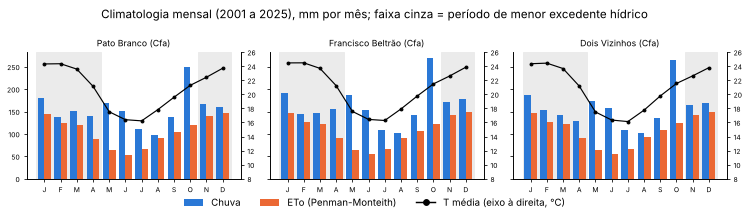

In [13]:
# Climograma: chuva e ETo mensais (barras) e temperatura média (linha), um painel por município
fig, eixos = grade(len(NOMES), larg=3.6, alt=3.0, sharey=True)
x = np.arange(12)
for ax, nome in zip(eixos, NOMES):
    c = CLIMA[nome]
    ax.bar(x - 0.2, c['P'], width=0.4, color='#2a78d6', label='Chuva')
    ax.bar(x + 0.2, c['ETo'], width=0.4, color='#eb6834', label='ETo (Penman-Monteith)')
    for m in MESES_SECOS[nome]:
        ax.axvspan(m - 1.5, m - 0.5, color='0.92', zorder=0)
    ax2 = ax.twinx()
    ax2.plot(x, c['T'], color='k', marker='o', ms=3, lw=1.2, label='T média')
    ax2.set_ylim(8, 26); ax2.tick_params(labelsize=7); ax2.spines[['top']].set_visible(False)
    ax.set_xticks(x); ax.set_xticklabels([m[0] for m in MESES_ABREV], fontsize=7)
    ax.set_title(f'{nome} ({KOPPEN[nome]})', fontsize=9); ax.spines[['top']].set_visible(False)
    ax.tick_params(axis='y', labelsize=7)
h1, l1 = eixos[0].get_legend_handles_labels()
fig.legend(h1 + [plt.Line2D([], [], color='k', marker='o')], l1 + ['T média (eixo à direita, °C)'], frameon=False,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f'Climatologia mensal ({PERIODO}), mm por mês; faixa cinza = período de menor excedente hídrico')
plt.tight_layout(rect=(0, 0.04, 1, 1))
salva_fig('etapa1_climograma.png')

## Etapa 1b · Validação da base com a estação meteorológica
___

A Qg do BR-DWGD **não é medida**: é interpolada a partir de estações. Por isso o projeto pede uma estação a até cerca de 10 km. Esta etapa compara, dia a dia e mês a mês, as variáveis do BR-DWGD com as medidas na estação, usando as mesmas métricas das etapas seguintes.

**Como obter os dados da estação**

1. **INMET, dados históricos (traz radiação):** em <https://portal.inmet.gov.br/dadoshistoricos>, baixe o ZIP de cada ano. Dentro de cada ZIP há um CSV horário por estação automática (Dois Vizinhos é a A843).
2. **BDMEP:** em <https://bdmep.inmet.gov.br>, peça a série **diária** da estação. É mais rápido, mas a série diária das automáticas costuma vir **sem radiação**.
3. **IDR-Paraná:** as séries de Pato Branco e Francisco Beltrão precisam ser pedidas ao IDR-Paraná; salvem no mesmo formato do BDMEP (colunas Data, Precipitação, Temperatura máxima, Temperatura mínima, Umidade relativa, Radiação).

Coloque os arquivos `.csv` em um subdiretório por cidade:

```
dados/inmet/Pato Branco/*.csv
dados/inmet/Francisco Beltrão/*.csv
dados/inmet/Dois Vizinhos/*.csv
(uma pasta por município; as pastas dos municípios sem estação ficam vazias)
```

O leitor abaixo reconhece os dois formatos (horário ou diário), junta todos os arquivos de cada pasta e, no caso horário, converte para dias no horário local (UTC−3): chuva e radiação são somadas, Tmax e Tmin são o máximo e o mínimo do dia e a UR é a média. Um dia só é aceito com pelo menos 20 horas de registro. Se a pasta de uma cidade estiver vazia, ela é pulada e o restante do notebook continua.

**Métricas próprias** (exigência do P1). Oᵢ observado, Pᵢ estimado. São usadas aqui e em todas as etapas seguintes.

In [14]:
def _arr(o, p):
    o, p = np.asarray(o, float), np.asarray(p, float)
    ok = np.isfinite(o) & np.isfinite(p)
    return o[ok], p[ok]


def r_pearson(o, p):
    o, p = _arr(o, p)
    return np.sum((o - o.mean()) * (p - p.mean())) / np.sqrt(np.sum((o - o.mean()) ** 2) * np.sum((p - p.mean()) ** 2))


def rmse(o, p):
    o, p = _arr(o, p)
    return np.sqrt(np.mean((p - o) ** 2))


def rrmse(o, p):
    o, p = _arr(o, p)
    return 100 * rmse(o, p) / o.mean()


def mae(o, p):
    o, p = _arr(o, p)
    return np.mean(np.abs(p - o))


def vies(o, p):
    o, p = _arr(o, p)
    return np.mean(p - o)


def ef_nash(o, p):
    o, p = _arr(o, p)
    return 1 - np.sum((p - o) ** 2) / np.sum((o - o.mean()) ** 2)


def d_willmott(o, p):
    o, p = _arr(o, p)
    return 1 - np.sum((p - o) ** 2) / np.sum((np.abs(p - o.mean()) + np.abs(o - o.mean())) ** 2)


def c_camargo(o, p):
    return r_pearson(o, p) * d_willmott(o, p)


def classe_c(c):
    # Camargo & Sentelhas (1997)
    for lim, nome in [(0.85, 'Ótimo'), (0.75, 'Muito bom'), (0.65, 'Bom'), (0.60, 'Mediano'), (0.50, 'Sofrível'), (0.40, 'Mau')]:
        if c > lim:
            return nome
    return 'Péssimo'


def metricas(o, p):
    r = r_pearson(o, p)
    return {'RMSE': rmse(o, p), 'RRMSE_%': rrmse(o, p), 'MAE': mae(o, p), 'Viés': vies(o, p),
            'EF': ef_nash(o, p), 'R2': r ** 2, 'd': d_willmott(o, p), 'c': c_camargo(o, p),
            'Desempenho': classe_c(r * d_willmott(o, p))}


# Teste rápido das funções: estimativa perfeita e estimativa pela média
_o = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
assert abs(rmse(_o, _o)) < 1e-12 and abs(ef_nash(_o, _o) - 1) < 1e-12 and abs(d_willmott(_o, _o) - 1) < 1e-12
assert abs(ef_nash(_o, np.full(5, _o.mean()))) < 1e-12 and abs(rmse(_o, _o + 1) - 1) < 1e-12
print('Métricas conferidas.')

Métricas conferidas.


In [15]:
import glob
import unicodedata

PASTA_INMET = os.path.join(PASTA_DADOS, 'inmet')
for l in LOCAIS:
    os.makedirs(os.path.join(PASTA_INMET, l['municipio']), exist_ok=True)


def _norm(texto):
    # Maiúsculas, sem acento e com espaços simples, para achar as colunas pelo nome
    t = unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode().upper()
    return ' '.join(t.split())


def _coluna(colunas, chave, evita=()):
    for c in colunas:
        n = _norm(c)
        if chave in n and not any(e in n for e in evita):
            return c
    return None


def _num(serie):
    s = pd.to_numeric(serie.astype(str).str.strip().str.replace(',', '.', regex=False), errors='coerce')
    return s.where(s > -9000)          # o INMET marca falha com -9999


def le_arquivo_inmet(caminho):
    with open(caminho, encoding='latin-1') as f:
        linhas = f.readlines()
    # a linha de títulos começa com 'Data' e tem várias colunas (evita 'DATA DE FUNDACAO' do cabeçalho)
    ini = next(i for i, linha in enumerate(linhas) if _norm(linha).startswith('DATA') and linha.count(';') >= 3)
    bruto = pd.read_csv(caminho, sep=';', skiprows=ini, encoding='latin-1', dtype=str)
    bruto = bruto.loc[:, ~bruto.columns.str.startswith('Unnamed')]
    cols = list(bruto.columns)

    c_data = _coluna(cols, 'DATA')
    c_hora = next((c for c in cols if _norm(c).startswith('HORA')), None)
    mapa = {
        'pr':   _coluna(cols, 'PRECIPITACAO'),
        'Tmax': _coluna(cols, 'TEMPERATURA MAXIMA'),
        'Tmin': _coluna(cols, 'TEMPERATURA MINIMA'),
        'Tbs':  _coluna(cols, 'BULBO SECO'),
        'RH':   _coluna(cols, 'UMIDADE RELATIVA', evita=('MIN', 'MAX')),
        'Rs':   _coluna(cols, 'RADIACAO'),
    }
    datas = bruto[c_data].astype(str).str.strip()
    ano_primeiro = datas.str.match(r'^\d{4}').all()
    dia = pd.to_datetime(datas, dayfirst=not ano_primeiro, errors='coerce')

    df = pd.DataFrame({v: _num(bruto[c]) for v, c in mapa.items() if c is not None})

    if c_hora is None:                                   # arquivo diário
        df.index = dia
        return df.drop(columns=['Tbs'], errors='ignore')

    # Arquivo horário: hora UTC -> horário local (UTC-3) -> dia
    hora = pd.to_numeric(bruto[c_hora].astype(str).str.extract(r'(\d{2})')[0], errors='coerce')
    df['dia'] = (dia + pd.to_timedelta(hora, unit='h') - pd.Timedelta(hours=3)).dt.normalize()
    df['Rs'] = df.get('Rs', pd.Series(np.nan, index=df.index)).clip(lower=0) / 1000   # kJ m-2 -> MJ m-2
    if 'Tmax' not in df:
        df['Tmax'] = df['Tbs']
    if 'Tmin' not in df:
        df['Tmin'] = df['Tbs']

    g = df.groupby('dia')
    diario = pd.DataFrame({
        'pr': g['pr'].sum(min_count=20) if 'pr' in df else np.nan,
        'Tmax': g['Tmax'].max(),
        'Tmin': g['Tmin'].min(),
        'RH': g['RH'].mean() if 'RH' in df else np.nan,
        'Rs': g['Rs'].sum(min_count=8),
    })
    horas_validas = g['Tmax'].count()
    return diario[horas_validas >= 20]


def carrega_inmet(nome):
    arquivos = sorted(glob.glob(os.path.join(PASTA_INMET, nome, '*.csv')) +
                      glob.glob(os.path.join(PASTA_INMET, nome, '*.CSV')))
    if not arquivos:
        return None
    partes = [le_arquivo_inmet(a) for a in arquivos]
    df = pd.concat(partes).sort_index()
    df = df[~df.index.duplicated()]
    df = df.loc[f'{ANO_INICIO}-01-01':f'{ANO_FIM}-12-31']
    # mesmo controle de qualidade da base BR-DWGD
    for v in ('pr', 'Tmax', 'Tmin', 'RH', 'Rs'):
        if v in df:
            df.loc[~df[v].between(*FAIXAS[v]), v] = np.nan
    df.loc[df['Tmin'] > df['Tmax'], ['Tmax', 'Tmin']] = np.nan
    return df


INMET = {}
for nome in NOMES:
    INMET[nome] = carrega_inmet(nome)
    if INMET[nome] is None:
        print(f'{nome:<18} sem arquivos de estação em dados/inmet/{nome}')
    else:
        d = INMET[nome]
        print(f'{nome:<18} {len(d)} dias ({d.index.min():%d/%m/%Y} a {d.index.max():%d/%m/%Y}) | '
              + ', '.join(f'{v}: {d[v].notna().sum()}' for v in ('Tmax', 'Tmin', 'Rs', 'pr', 'RH') if v in d))

Pato Branco        sem arquivos de estação em dados/inmet/Pato Branco
Francisco Beltrão  sem arquivos de estação em dados/inmet/Francisco Beltrão
Dois Vizinhos      sem arquivos de estação em dados/inmet/Dois Vizinhos


**Comparação.** Cada variável é comparada em escala **diária** e **mensal** (média dos valores diários de meses com pelo menos 20 dias nas duas bases). A estação é o observado e o BR-DWGD, o estimado. Na chuva diária, espera-se concordância baixa: o horário em que cada base fecha o dia não é o mesmo e a chuva é muito localizada; a escala mensal é a comparação mais justa.

In [16]:
VARS_INMET = {'Tmax': 'Tmax (°C)', 'Tmin': 'Tmin (°C)', 'Rs': 'Qg (MJ m⁻² d⁻¹)', 'pr': 'Chuva (mm d⁻¹)', 'RH': 'UR (%)'}

reg = []
PARES_INMET = {}
for nome in NOMES:
    obs = INMET[nome]
    if obs is None:
        continue
    for v in VARS_INMET:
        if v not in obs or obs[v].notna().sum() < 30:
            continue
        par = pd.DataFrame({'INMET': obs[v], 'BR-DWGD': SERIES[nome][v]}).dropna()
        PARES_INMET[(nome, v)] = par
        g = par.groupby([par.index.year, par.index.month])
        mensal = g.mean()[g.size() >= 20]
        for escala, d in (('Diária', par), ('Mensal', mensal)):
            if len(d) >= 10:
                reg.append({'Local': nome, 'Variável': VARS_INMET[v], 'Escala': escala, 'n': len(d),
                            **metricas(d['INMET'], d['BR-DWGD'])})

tabela_inmet = pd.DataFrame(reg).set_index(['Local', 'Variável', 'Escala']) if reg else None
if tabela_inmet is None:
    print('Etapa 1b não executada: nenhuma pasta de estação tem arquivos. '
          'Coloque os CSV nas pastas indicadas e rode esta etapa de novo. As etapas seguintes não dependem dela.')
else:
    tabela_inmet.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa1b_brdwgd_vs_inmet.csv'))
    display(tabela_inmet.round(3))

Etapa 1b não executada: nenhuma pasta de estação tem arquivos. Coloque os CSV nas pastas indicadas e rode esta etapa de novo. As etapas seguintes não dependem dela.


In [17]:
if PARES_INMET:
    vars_fig = [v for v in ('Tmax', 'Tmin', 'Rs') if any(k[1] == v for k in PARES_INMET)]
    locais_fig = [n for n in NOMES if any(k[0] == n for k in PARES_INMET)]
    fig, eixos = plt.subplots(len(locais_fig), len(vars_fig), figsize=(4.3 * len(vars_fig), 4 * len(locais_fig)), squeeze=False)
    for i, n in enumerate(locais_fig):
        for j, v in enumerate(vars_fig):
            ax = eixos[i, j]
            par = PARES_INMET.get((n, v))
            if par is None:
                ax.axis('off')
                continue
            ax.scatter(par['INMET'], par['BR-DWGD'], s=3, alpha=0.2, color=CORES_LOCAL[n], edgecolors='none')
            lim = [min(par.min()), max(par.max())]
            ax.plot(lim, lim, color='0.4', ls='--', lw=1)
            met = metricas(par['INMET'], par['BR-DWGD'])
            ax.text(0.04, 0.96, f"RMSE={met['RMSE']:.2f}\nviés={met['Viés']:+.2f}\nd={met['d']:.3f}",
                    transform=ax.transAxes, va='top', fontsize=8)
            ax.set_xlabel(f'Estação · {VARS_INMET[v]}')
            ax.set_ylabel(f'{n}\nBR-DWGD' if j == 0 else 'BR-DWGD')
            ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('BR-DWGD × estação (escala diária)')
    plt.tight_layout()
    salva_fig('etapa1b_brdwgd_vs_inmet.png')

## Etapa 2 · Variáveis astronômicas e balanço de radiação (FAO-56)
___

| Grandeza | Cálculo |
|---|---|
| es, ea | Tetens pela média de es(Tmax) e es(Tmin); ea = es · UR/100 |
| Qg,cs | (0,75 + 2·10⁻⁵ · z) · Qo (FAO-56, Eq. 37) |
| BOC | Qg · (1 − r) |
| BOL | Stefan-Boltzmann corrigido (FAO-56, Eq. 39) |
| Rn | BOC + BOL |

**Albedo.** Usamos **r = 0,23**, o valor da FAO-56 para a grama de referência, porque o Rn calculado aqui serve de referência para a ETo (que no BR-DWGD também é FAO-56). A biblioteca adota 0,25 (gramado) por padrão.

> ⚠️ O Rn de referência é **calculado**, não medido. Fietz & Fisch usaram saldo-radiômetro; essa diferença precisa aparecer no relatório.

In [18]:
ALBEDO = 0.23

for l in LOCAIS:
    df = SERIES[l['municipio']]
    df['es'] = (amp.es_tetens(df['Tmax']) + amp.es_tetens(df['Tmin'])) / 2
    df['ea'] = amp.ea_umidade(df['es'], df['RH'])
    df['Qgcs'] = (0.75 + 2e-5 * l['altitude_m']) * df['Qo']
    df['BOC'] = amp.boc_saldo(df['Rs'], r=ALBEDO)
    # Na FAO-56, Qg/Qg,cs é limitada a 1 no BOL
    df['BOL'] = amp.bol_saldo(df['Tmax'], df['Tmin'], df['ea'], np.minimum(df['Rs'], df['Qgcs']), df['Qgcs'])
    df['Rn'] = amp.saldo_radiacao(df['BOC'], df['BOL'])
    df['Kt'] = df['Rs'] / df['Qo']          # transmissividade atmosférica

VARS_RAD = ['Qo', 'Rs', 'Qgcs', 'BOC', 'BOL', 'Rn']
tabela_rad = pd.concat({n: SERIES[n][VARS_RAD].describe().loc[['mean', 'std', 'min', 'max']].T for n in NOMES}, axis=1)
tabela_rad.index = ['Qo', 'Qg', 'Qg,cs', 'BOC', 'BOL', 'Rn']
tabela_rad.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa2_balanco_radiacao.csv'))
tabela_rad.round(2)

Pato Branco                     Francisco Beltrão                     Dois Vizinhos                    
             mean   std    min    max              mean   std    min    max          mean   std    min    max
Qo          32.89  8.13  20.64  43.39             32.89  8.12  20.66  43.38         32.99  8.03  20.87  43.32
Qg          16.78  7.07   0.89  33.40             16.94  7.17   0.73  33.40         16.96  7.09   0.89  33.40
Qg,cs       25.13  6.21  15.77  33.15             25.05  6.19  15.73  33.04         25.10  6.11  15.88  32.96
BOC         12.92  5.45   0.68  25.72             13.05  5.52   0.56  25.72         13.06  5.46   0.68  25.72
BOL         -3.00  1.86  -7.23   1.69             -3.06  1.89  -7.25   1.69         -3.04  1.85  -7.27   1.62
Rn           9.92  4.34   2.03  20.12              9.98  4.39   2.04  20.02         10.01  4.36   2.06  19.98

**Climatologia mensal do balanço de radiação** (item obrigatório do roteiro).

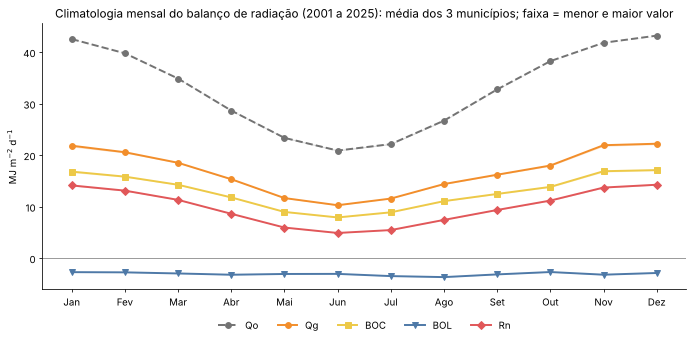

,Qg média,Rn médio,Rn jun,Rn dez,BOL médio
Pato Branco,16.78,9.92,4.90,14.21,-3.00
Francisco Beltrão,16.94,9.98,4.91,14.34,-3.06
Dois Vizinhos,16.96,10.01,4.97,14.33,-3.04


In [19]:
estilo = {'Qo': ('0.45', '--', 'o'), 'Rs': ('#f28e2b', '-', 'o'), 'BOC': ('#edc948', '-', 's'),
          'BOL': ('#4e79a7', '-', 'v'), 'Rn': ('#e15759', '-', 'D')}
rotulo = {'Qo': 'Qo', 'Rs': 'Qg', 'BOC': 'BOC', 'BOL': 'BOL', 'Rn': 'Rn'}

CLIM_RAD = {}
for nome in NOMES:
    CLIM_RAD[nome] = SERIES[nome].groupby(SERIES[nome].index.month)[list(estilo)].mean()

# Média dos dez municípios, com a faixa entre o menor e o maior valor
fig, ax = plt.subplots(figsize=(10, 5))
meses = np.arange(1, 13)
for v, (cor, ls, mk) in estilo.items():
    tab = pd.DataFrame({n: CLIM_RAD[n][v] for n in NOMES})
    ax.fill_between(meses, tab.min(axis=1), tab.max(axis=1), color=cor, alpha=0.25, lw=0)
    ax.plot(meses, tab.mean(axis=1), color=cor, ls=ls, marker=mk, lw=2, label=rotulo[v])
ax.axhline(0, color='0.6', lw=1)
ax.set_xticks(meses); ax.set_xticklabels(MESES_ABREV)
ax.set_ylabel('MJ m$^{-2}$ d$^{-1}$'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5)
ax.set_title(f'Climatologia mensal do balanço de radiação ({PERIODO}): média dos {len(NOMES)} municípios; faixa = menor e maior valor')
plt.tight_layout()
salva_fig('etapa2_climatologia_radiacao.png')

clim_tab = pd.concat({n: c.rename(columns=rotulo) for n, c in CLIM_RAD.items()}, axis=1)
clim_tab.index = MESES_ABREV
clim_tab.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa2_climatologia_radiacao.csv'))

# Rn médio anual e amplitude sazonal de cada município
pd.DataFrame({'Qg média': {n: SERIES[n]['Rs'].mean() for n in NOMES},
              'Rn médio': {n: SERIES[n]['Rn'].mean() for n in NOMES},
              'Rn jun': {n: CLIM_RAD[n].loc[6, 'Rn'] for n in NOMES},
              'Rn dez': {n: CLIM_RAD[n].loc[12, 'Rn'] for n in NOMES},
              'BOL médio': {n: SERIES[n]['BOL'].mean() for n in NOMES}}).round(2)

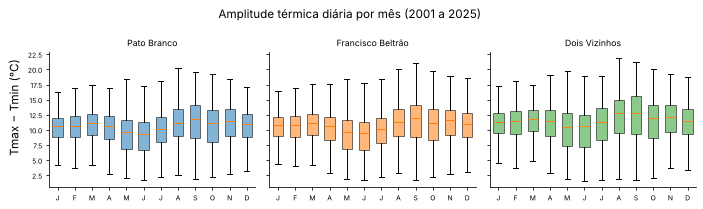

In [20]:
# Boxplot da amplitude térmica diária por mês, um painel por município (equivalente à Fig. 2 de Fernandes et al.)
fig, eixos = grade(len(NOMES), sharey=True)
for ax, nome in zip(eixos, NOMES):
    df = SERIES[nome]
    dados = [(df['Tmax'] - df['Tmin'])[df.index.month == m].dropna() for m in range(1, 13)]
    bp = ax.boxplot(dados, patch_artist=True, widths=0.6, showfliers=False)
    for c in bp['boxes']:
        c.set(facecolor=CORES_LOCAL[nome], alpha=0.55)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MESES_ABREV], fontsize=7)
    ax.set_title(nome, fontsize=9); ax.tick_params(axis='y', labelsize=7); ax.spines[['top', 'right']].set_visible(False)
fig.supylabel('Tmax − Tmin (°C)')
fig.suptitle(f'Amplitude térmica diária por mês ({PERIODO})')
plt.tight_layout()
salva_fig('etapa2_boxplot_amplitude.png')

**Por que a temperatura consegue estimar a radiação?** Dia de céu limpo aquece mais de dia e esfria mais à noite: a amplitude térmica cresce com a transmissividade da atmosfera (Kt = Qg/Qo). O gráfico abaixo mostra essa relação nos municípios; é ela que os cinco modelos da Etapa 3 exploram. A dispersão em torno da curva é o erro que nenhum modelo de temperatura consegue remover.

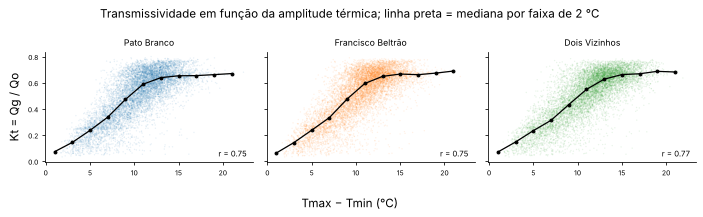

In [21]:
fig, eixos = grade(len(NOMES), sharex=True, sharey=True)
for ax, nome in zip(eixos, NOMES):
    df = SERIES[nome].dropna(subset=['Kt', 'Tmax', 'Tmin'])
    amp_t = df['Tmax'] - df['Tmin']
    ax.scatter(amp_t, df['Kt'], s=2, alpha=0.1, color=CORES_LOCAL[nome], edgecolors='none')
    faixas = pd.cut(amp_t, np.arange(0, 24, 2))
    med = df['Kt'].groupby(faixas, observed=True).median()
    ax.plot([i.mid for i in med.index], med.values, color='k', marker='o', ms=3, lw=1.3)
    ax.text(0.97, 0.05, f"r = {r_pearson(amp_t, df['Kt']):.2f}", transform=ax.transAxes, ha='right', fontsize=8)
    ax.set_title(nome, fontsize=9); ax.spines[['top', 'right']].set_visible(False); ax.tick_params(labelsize=7)
fig.supxlabel('Tmax − Tmin (°C)'); fig.supylabel('Kt = Qg / Qo')
fig.suptitle('Transmissividade em função da amplitude térmica; linha preta = mediana por faixa de 2 °C')
plt.tight_layout()
salva_fig('etapa2_amplitude_transmissividade.png')

## Etapa 3 · Modelos de Qg a partir da temperatura (Fernandes et al., 2018)
___

Variáveis de entrada:

- **ΔTᵢ = Tmaxᵢ − (Tminᵢ + Tminᵢ₊₁)/2** (usa a Tmin do **dia seguinte**; o último dia da série fica sem valor);
- **ΔTavg** = média móvel centrada de 7 dias de ΔTᵢ;
- **Tavg** = (Tmax + Tmin)/2.

| Modelo | Equação | Parâmetros |
|---|---|---|
| HG (Hargreaves) | Qg = b · Qo · √ΔTᵢ + c | b, c |
| BC (Bristow-Campbell) | Qg = 0,75 · [1 − exp(−b · ΔTᵢᶜ / ΔTavg)] · Qo | b, c |
| CD (Donatelli-Campbell) | Qg = 0,75 · [1 − exp(−b · f(Tavg) · ΔTᵢ² · exp(Tmin/Tnc))] · Qo | b, Tnc |
| DB (Donatelli-Bellocchi) | Qg = 0,75 · [1 + f(NDA)] · [1 − exp(−b · ΔTᵢ² / ΔTavg)] · Qo | b, C1, C2 |
| DCBB | Qg = 0,75 · [1 + f(NDA)] · [1 − exp(−b · ΔTᵢ² · exp(Tmin/Tnc) / ΔTavg)] · Qo | b, C1, C2, Tnc |

com f(Tavg) = 0,017 · exp[exp(−0,053 · Tavg)] e f(NDA) = C1 · [sen(NDA · C2 · π/180) + cos(NDA · f₃ · π/180)], f₃ = 1 − 1,9·C3 + 3,83·C3², C3 = C2 − int(C2).

> O HG de Fernandes et al. tem **dois** parâmetros calibrados (b e c) e usa ΔTᵢ, e não o k fixo e o ΔT clássico de `amp.etp_hargreaves_samani`.

In [22]:
for df in SERIES.values():
    df['dTi'] = df['Tmax'] - (df['Tmin'] + df['Tmin'].shift(-1)) / 2
    df['dTavg'] = df['dTi'].rolling(7, center=True, min_periods=7).mean()
    df['NDA'] = df.index.dayofyear


def f_nda(nda, C1, C2):
    C3 = C2 - np.floor(C2)
    f3 = 1 - 1.9 * C3 + 3.83 * C3 ** 2
    return C1 * (np.sin(nda * C2 * np.pi / 180) + np.cos(nda * f3 * np.pi / 180))


def _dti(d):
    return np.clip(d['dTi'], 0, None)      # ΔTi negativo (raro, em entrada de frente fria) vira zero


def m_HG(p, d):
    b, c = p
    return b * d['Qo'] * np.sqrt(_dti(d)) + c


def m_BC(p, d):
    b, c = p
    return 0.75 * (1 - np.exp(-b * _dti(d) ** c / d['dTavg'])) * d['Qo']


def m_CD(p, d):
    b, Tnc = p
    fT = 0.017 * np.exp(np.exp(-0.053 * d['Tavg']))
    return 0.75 * (1 - np.exp(-b * fT * _dti(d) ** 2 * np.exp(d['Tmin'] / Tnc))) * d['Qo']


def m_DB(p, d):
    b, C1, C2 = p
    return 0.75 * (1 + f_nda(d['NDA'], C1, C2)) * (1 - np.exp(-b * _dti(d) ** 2 / d['dTavg'])) * d['Qo']


def m_DCBB(p, d):
    b, C1, C2, Tnc = p
    return (0.75 * (1 + f_nda(d['NDA'], C1, C2))
            * (1 - np.exp(-b * _dti(d) ** 2 * np.exp(d['Tmin'] / Tnc) / d['dTavg'])) * d['Qo'])


# chute inicial e limites de cada parâmetro
MODELOS_QG = {
    'HG':   dict(f=m_HG,   par=['b', 'c'],               x0=[0.16, 0.0],          lim=([0, -10], [1, 10])),
    'BC':   dict(f=m_BC,   par=['b', 'c'],               x0=[0.5, 1.5],           lim=([1e-3, 0.1], [20, 4])),
    'CD':   dict(f=m_CD,   par=['b', 'Tnc'],             x0=[0.5, 30.0],          lim=([1e-4, 1], [5, 300])),
    'DB':   dict(f=m_DB,   par=['b', 'C1', 'C2'],        x0=[0.1, 0.05, 1.5],     lim=([1e-4, -0.5, 0.01], [5, 0.5, 3])),
    'DCBB': dict(f=m_DCBB, par=['b', 'C1', 'C2', 'Tnc'], x0=[0.1, 0.05, 1.5, 30], lim=([1e-4, -0.5, 0.01, 1], [5, 0.5, 3, 300])),
}
ORDEM_QG = list(MODELOS_QG)
CORES_MODELO = {'HG': '#2a78d6', 'BC': '#eb6834', 'CD': '#1baf7a', 'DB': '#e34948', 'DCBB': '#6250d6'}
ESTILOS_MODELO = {'HG': '-', 'BC': '--', 'CD': '-.', 'DB': ':', 'DCBB': (0, (3, 1, 1, 1))}

**Calibração.** Mínimos quadrados não lineares (`scipy.optimize.least_squares`) nos anos ímpares. DB e DCBB são sensíveis ao chute inicial; por isso cada modelo é ajustado a partir de vários chutes (o chute da tabela mais sorteios dentro dos limites) e fica o de menor erro. A semente é fixa para o resultado ser reprodutível.

In [23]:
def calibra(func, dados, alvo, x0, lim, n_chutes=1, seed=42):
    lo, hi = np.array(lim[0], float), np.array(lim[1], float)
    rng = np.random.default_rng(seed)
    chutes = [np.array(x0, float)] + [rng.uniform(lo, hi) for _ in range(n_chutes - 1)]
    melhor, custo_min = None, np.inf
    for x in chutes:
        try:
            res = least_squares(lambda p: np.asarray(func(p, dados)) - alvo, np.clip(x, lo, hi), bounds=(lo, hi), max_nfev=5000)
        except Exception:
            continue
        custo = np.sum(res.fun ** 2)
        if np.isfinite(custo) and custo < custo_min:
            melhor, custo_min = res.x, custo
    return melhor


N_CHUTES = {'HG': 5, 'BC': 12, 'CD': 12, 'DB': 40, 'DCBB': 40}

BASE_QG, PAR_QG, EST_QG = {}, {}, {}
for nome in NOMES:
    base = SERIES[nome][['Qo', 'dTi', 'dTavg', 'Tmed', 'Tmin', 'NDA', 'Rs']].rename(columns={'Tmed': 'Tavg'}).dropna()
    base = base[base['dTavg'] > 0]
    base['grupo'] = np.where(base.index.year % 2 == 1, 'Calibração', 'Validação')
    cal = base[base['grupo'] == 'Calibração']
    BASE_QG[nome], PAR_QG[nome], EST_QG[nome] = base, {}, {}
    for m, info in MODELOS_QG.items():
        PAR_QG[nome][m] = calibra(info['f'], cal, cal['Rs'].values, info['x0'], info['lim'], N_CHUTES[m])
        EST_QG[nome][m] = pd.Series(np.asarray(info['f'](PAR_QG[nome][m], base)), index=base.index)
    print(f"{nome:<18} {len(cal)} dias de calibração, {len(base) - len(cal)} de validação")

Pato Branco        4738 dias de calibração, 4386 de validação


Francisco Beltrão  4738 dias de calibração, 4386 de validação


Dois Vizinhos      4738 dias de calibração, 4386 de validação


In [24]:
# Tabela: parâmetros calibrados
tabela2 = pd.DataFrame([{'Local': n, 'Modelo': m, **dict(zip(MODELOS_QG[m]['par'], PAR_QG[n][m]))}
                        for m in ORDEM_QG for n in NOMES]).set_index(['Modelo', 'Local'])[['b', 'c', 'Tnc', 'C1', 'C2']]
tabela2.round(5)

b        c    Tnc       C1       C2
Modelo Local                                                       
HG     Pato Branco        0.17530 -1.80859    NaN      NaN      NaN
       Francisco Beltrão  0.17687 -1.87905    NaN      NaN      NaN
       Dois Vizinhos      0.17695 -2.48553    NaN      NaN      NaN
BC     Pato Branco        0.05944  2.27812    NaN      NaN      NaN
       Francisco Beltrão  0.06031  2.27804    NaN      NaN      NaN
       Dois Vizinhos      0.05929  2.25166    NaN      NaN      NaN
CD     Pato Branco        0.44430      NaN  300.0      NaN      NaN
       Francisco Beltrão  0.44991      NaN  300.0      NaN      NaN
       Dois Vizinhos      0.39808      NaN  300.0      NaN      NaN
DB     Pato Branco        0.11375      NaN    NaN  0.03444  0.82019
       Francisco Beltrão  0.12000      NaN    NaN -0.02925  1.61198
       Dois Vizinhos      0.10820      NaN    NaN  0.03264  0.83215
DCBB   Pato Branco        0.11236      NaN  300.0 -0.02942  1.59159
       Francisco Beltrão  0.11391      NaN  300.0 -0.03086  1.60626
       Dois Vizinhos      0.10607      NaN  300.0 -0.02675  1.62015

In [25]:
# Tabela: métricas na calibração e na validação
reg = []
for n in NOMES:
    b = BASE_QG[n]
    for m in ORDEM_QG:
        for g in ('Calibração', 'Validação'):
            sel = b['grupo'] == g
            reg.append({'Modelo': m, 'Local': n, 'Conjunto': g, **metricas(b.loc[sel, 'Rs'], EST_QG[n][m][sel])})
tabela3 = pd.DataFrame(reg).set_index(['Modelo', 'Local', 'Conjunto'])
tabela3.round(3)

RMSE  RRMSE_%    MAE   Viés     EF     R2      d      c Desempenho
Modelo Local             Conjunto                                                                       
HG     Pato Branco       Calibração  4.287   25.709  3.433 -0.000  0.620  0.620  0.871  0.686        Bom
                         Validação   4.289   25.402  3.456 -0.082  0.644  0.645  0.880  0.706        Bom
BC     Pato Branco       Calibração  3.779   22.661  2.855 -0.077  0.705  0.710  0.914  0.770  Muito bom
                         Validação   3.759   22.259  2.886 -0.140  0.727  0.729  0.920  0.786  Muito bom
CD     Pato Branco       Calibração  3.797   22.766  2.899 -0.013  0.702  0.706  0.913  0.767  Muito bom
                         Validação   3.772   22.338  2.896 -0.014  0.725  0.728  0.920  0.785  Muito bom
DB     Pato Branco       Calibração  3.773   22.625  2.871 -0.051  0.706  0.706  0.908  0.763  Muito bom
                         Validação   3.795   22.473  2.940 -0.142  0.722  0.722  0.912  0.775  Muito bom
DCBB   Pato Branco       Calibração  3.790   22.729  2.873 -0.003  0.703  0.703  0.904  0.758  Muito bom
                         Validação   3.820   22.623  2.955 -0.103  0.718  0.720  0.908  0.771  Muito bom
HG     Francisco Beltrão Calibração  4.332   25.774  3.451  0.000  0.623  0.623  0.873  0.689        Bom
                         Validação   4.324   25.324  3.494 -0.142  0.648  0.649  0.880  0.709        Bom
BC     Francisco Beltrão Calibração  3.850   22.902  2.878 -0.061  0.702  0.707  0.914  0.768  Muito bom
                         Validação   3.784   22.160  2.893 -0.170  0.730  0.732  0.920  0.788  Muito bom
CD     Francisco Beltrão Calibração  3.844   22.868  2.891 -0.006  0.703  0.707  0.913  0.768  Muito bom
                         Validação   3.776   22.116  2.873 -0.053  0.731  0.733  0.921  0.789  Muito bom
DB     Francisco Beltrão Calibração  3.841   22.850  2.888  0.012  0.704  0.704  0.905  0.759  Muito bom
                         Validação   3.853   22.564  2.975 -0.132  0.720  0.724  0.908  0.773  Muito bom
DCBB   Francisco Beltrão Calibração  3.856   22.938  2.903  0.005  0.701  0.702  0.904  0.757  Muito bom
                         Validação   3.870   22.666  2.992 -0.141  0.718  0.721  0.907  0.771  Muito bom
HG     Dois Vizinhos     Calibração  4.101   24.381  3.236 -0.000  0.652  0.652  0.886  0.716        Bom
                         Validação   4.092   23.944  3.283 -0.099  0.679  0.681  0.894  0.737        Bom
BC     Dois Vizinhos     Calibração  3.678   21.866  2.721 -0.067  0.720  0.724  0.919  0.782  Muito bom
                         Validação   3.599   21.058  2.726 -0.144  0.752  0.753  0.927  0.804  Muito bom
CD     Dois Vizinhos     Calibração  3.637   21.620  2.690 -0.011  0.727  0.729  0.921  0.786  Muito bom
                         Validação   3.546   20.749  2.654  0.001  0.759  0.760  0.930  0.810  Muito bom
DB     Dois Vizinhos     Calibração  3.673   21.836  2.750 -0.044  0.721  0.721  0.914  0.776  Muito bom
                         Validação   3.639   21.294  2.793 -0.155  0.746  0.748  0.920  0.796  Muito bom
DCBB   Dois Vizinhos     Calibração  3.691   21.942  2.756 -0.015  0.718  0.719  0.911  0.773  Muito bom
                         Validação   3.694   21.615  2.835 -0.134  0.739  0.742  0.916  0.789  Muito bom

**d e c por período (seco, úmido, todo) em escala diária e mensal**, na série completa. Na escala mensal comparam-se as médias mensais de Qg.

In [26]:
reg = []
for n in NOMES:
    b = BASE_QG[n]
    seco = b.index.month.isin(MESES_SECOS[n])
    for m in ORDEM_QG:
        for per, sel in [('Todo', np.ones(len(b), bool)), ('Seco', seco), ('Úmido', ~seco)]:
            o, p = b['Rs'][sel], EST_QG[n][m][sel]
            mens = pd.DataFrame({'o': o, 'p': p}).groupby([o.index.year, o.index.month]).mean()
            reg.append({'Modelo': m, 'Local': n, 'Período': per,
                        'd_diário': d_willmott(o, p), 'c_diário': c_camargo(o, p), 'classe_diário': classe_c(c_camargo(o, p)),
                        'd_mensal': d_willmott(mens['o'], mens['p']), 'c_mensal': c_camargo(mens['o'], mens['p']),
                        'classe_mensal': classe_c(c_camargo(mens['o'], mens['p']))})
tabela_dc = pd.DataFrame(reg).set_index(['Modelo', 'Local', 'Período'])
tabela_dc.round(3)

d_diário  c_diário classe_diário  d_mensal  c_mensal classe_mensal
Modelo Local             Período                                                                    
HG     Pato Branco       Todo        0.875     0.696           Bom     0.970     0.919         Ótimo
                         Seco        0.826     0.635       Mediano     0.941     0.837     Muito bom
                         Úmido       0.830     0.593      Sofrível     0.941     0.869         Ótimo
BC     Pato Branco       Todo        0.917     0.778     Muito bom     0.976     0.933         Ótimo
                         Seco        0.905     0.755     Muito bom     0.951     0.862         Ótimo
                         Úmido       0.881     0.688           Bom     0.957     0.897         Ótimo
CD     Pato Branco       Todo        0.916     0.776     Muito bom     0.965     0.904         Ótimo
                         Seco        0.904     0.751     Muito bom     0.932     0.823     Muito bom
                         Úmido       0.884     0.695           Bom     0.943     0.878         Ótimo
DB     Pato Branco       Todo        0.910     0.769     Muito bom     0.979     0.940         Ótimo
                         Seco        0.892     0.735           Bom     0.946     0.849     Muito bom
                         Úmido       0.867     0.674           Bom     0.967     0.906         Ótimo
DCBB   Pato Branco       Todo        0.906     0.764     Muito bom     0.979     0.940         Ótimo
                         Seco        0.886     0.730           Bom     0.945     0.850         Ótimo
                         Úmido       0.867     0.672           Bom     0.968     0.908         Ótimo
HG     Francisco Beltrão Todo        0.877     0.699           Bom     0.973     0.926         Ótimo
                         Seco        0.828     0.638       Mediano     0.950     0.860         Ótimo
                         Úmido       0.831     0.594      Sofrível     0.945     0.880         Ótimo
BC     Francisco Beltrão Todo        0.917     0.778     Muito bom     0.980     0.942         Ótimo
                         Seco        0.904     0.753     Muito bom     0.960     0.887         Ótimo
                         Úmido       0.881     0.688           Bom     0.962     0.909         Ótimo
CD     Francisco Beltrão Todo        0.917     0.778     Muito bom     0.971     0.918         Ótimo
                         Seco        0.905     0.754     Muito bom     0.947     0.862         Ótimo
                         Úmido       0.885     0.696           Bom     0.948     0.892         Ótimo
DB     Francisco Beltrão Todo        0.906     0.766     Muito bom     0.981     0.946         Ótimo
                         Seco        0.886     0.729           Bom     0.951     0.867         Ótimo
                         Úmido       0.867     0.674           Bom     0.972     0.919         Ótimo
DCBB   Francisco Beltrão Todo        0.906     0.764     Muito bom     0.982     0.947         Ótimo
                         Seco        0.884     0.726           Bom     0.951     0.868         Ótimo
                         Úmido       0.866     0.671           Bom     0.972     0.919         Ótimo
HG     Dois Vizinhos     Todo        0.890     0.726           Bom     0.976     0.935         Ótimo
                         Seco        0.843     0.663           Bom     0.957     0.879         Ótimo
                         Úmido       0.853     0.638       Mediano     0.950     0.897         Ótimo
BC     Dois Vizinhos     Todo        0.923     0.793     Muito bom     0.983     0.950         Ótimo
                         Seco        0.906     0.756     Muito bom     0.964     0.903         Ótimo
                         Úmido       0.897     0.726           Bom     0.970     0.929         Ótimo
CD     Dois Vizinhos     Todo        0.925     0.798     Muito bom     0.975     0.929         Ótimo
                         Seco        0.910     0.767     Muito bom     0.956     0.888         

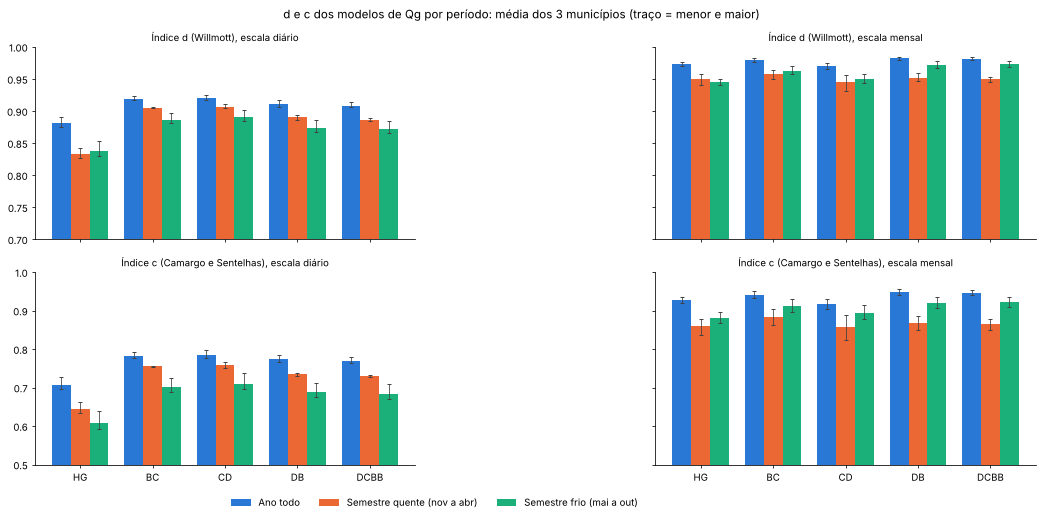

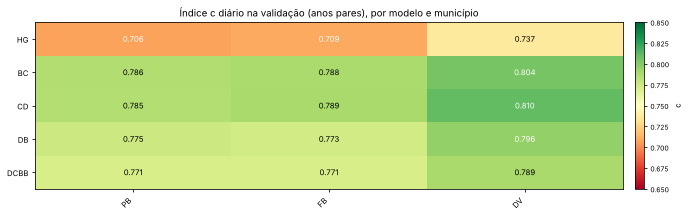

In [27]:
PER_ROT = {'Seco': 'Semestre quente (nov a abr)', 'Úmido': 'Semestre frio (mai a out)', 'Todo': 'Ano todo'}


# Barras de d e c por modelo e período (equivalente à Fig. 5 de Fernandes et al.):
# barra = média dos municípios; traço = menor e maior município
CORES_PERIODO = {'Todo': '#2a78d6', 'Seco': '#eb6834', 'Úmido': '#1baf7a'}
x = np.arange(len(ORDEM_QG)); larg = 0.26
fig, eixos = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True, sharey='row')
for j, esc in enumerate(('diário', 'mensal')):
    for i, (met, titulo) in enumerate([('d', 'Índice d (Willmott)'), ('c', 'Índice c (Camargo e Sentelhas)')]):
        ax = eixos[i, j]
        for k, per in enumerate(CORES_PERIODO):
            t = tabela_dc.xs(per, level='Período')[f'{met}_{esc}'].unstack('Local')[NOMES].loc[ORDEM_QG]
            med = t.mean(axis=1)
            ax.bar(x + (k - 1) * larg, med, width=larg, color=CORES_PERIODO[per], label=PER_ROT[per])
            ax.errorbar(x + (k - 1) * larg, med, yerr=[med - t.min(axis=1), t.max(axis=1) - med], fmt='none', ecolor='0.25', lw=0.8, capsize=2)
        ax.set_ylim(0.5 if met == 'c' else 0.7, 1.0); ax.spines[['top', 'right']].set_visible(False)
        ax.set_title(f'{titulo}, escala {esc}', fontsize=10)
        ax.set_xticks(x); ax.set_xticklabels(ORDEM_QG)
eixos[1, 0].legend(frameon=False, loc='upper center', bbox_to_anchor=(1.05, -0.12), ncol=3)
fig.suptitle(f'd e c dos modelos de Qg por período: média dos {len(NOMES)} municípios (traço = menor e maior)')
plt.tight_layout()
salva_fig('etapa3_barras_d_c.png')

# Complemento: índice c diário na validação, modelo x município
val = tabela3.xs('Validação', level='Conjunto')
c_dia = val['c'].unstack('Local')[NOMES].loc[ORDEM_QG]
c_dia.columns = [SIGLA[n] for n in NOMES]
fig, ax = plt.subplots(figsize=(10, 3.2))
mapa_calor(ax, c_dia, fmt='{:.3f}', vmin=0.65, vmax=0.85, titulo='Índice c diário na validação (anos pares), por modelo e município', barra='c')
plt.tight_layout()
salva_fig('etapa3_heatmap_c.png')

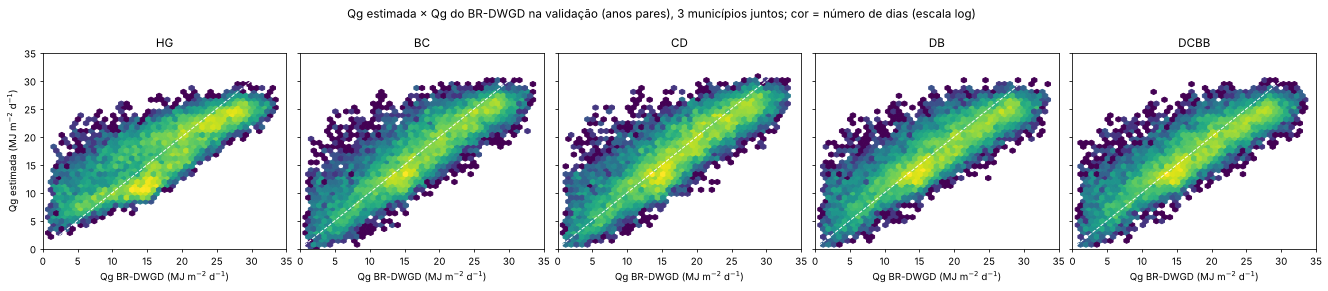

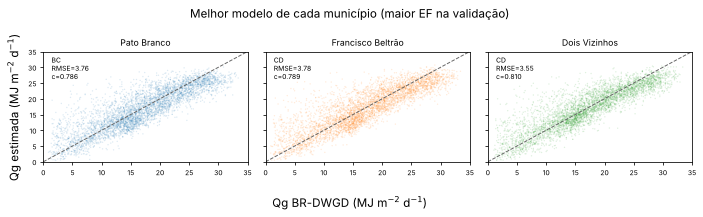

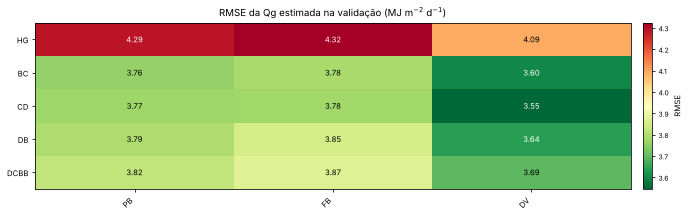

In [28]:
# Dispersão estimado x observado dos cinco modelos (equivalente à Fig. 4 de Fernandes et al.), todos os municípios juntos
fig, eixos = plt.subplots(1, len(ORDEM_QG), figsize=(19, 4.2), sharex=True, sharey=True)
for ax, m in zip(eixos, ORDEM_QG):
    obs = pd.concat([BASE_QG[n].loc[BASE_QG[n]['grupo'] == 'Validação', 'Rs'] for n in NOMES])
    est = pd.concat([EST_QG[n][m][BASE_QG[n]['grupo'] == 'Validação'] for n in NOMES])
    ax.hexbin(obs, est, gridsize=45, cmap='viridis', mincnt=1, bins='log', extent=(0, 35, 0, 35))
    ax.plot([0, 35], [0, 35], color='w', ls='--', lw=1)
    met = metricas(obs, est)
    ax.text(0.04, 0.96, f"RMSE={met['RMSE']:.2f}\nR²={met['R2']:.3f}\nd={met['d']:.3f}", transform=ax.transAxes, va='top', fontsize=8, color='w')
    ax.set_title(m); ax.set_xlim(0, 35); ax.set_ylim(0, 35)
    ax.set_xlabel('Qg BR-DWGD (MJ m$^{-2}$ d$^{-1}$)')
eixos[0].set_ylabel('Qg estimada (MJ m$^{-2}$ d$^{-1}$)')
fig.suptitle(f'Qg estimada × Qg do BR-DWGD na validação (anos pares), {len(NOMES)} municípios juntos; cor = número de dias (escala log)')
plt.tight_layout()
salva_fig('etapa3_dispersao_qg.png')

# Melhor modelo de cada município
_melhor = {n: tabela3.xs((n, 'Validação'), level=('Local', 'Conjunto'))['EF'].idxmax() for n in NOMES}
fig, eixos = grade(len(NOMES), sharex=True, sharey=True)
for ax, n in zip(eixos, NOMES):
    b = BASE_QG[n]
    val = b['grupo'] == 'Validação'
    m = _melhor[n]
    ax.scatter(b.loc[val, 'Rs'], EST_QG[n][m][val], s=2, alpha=0.15, color=CORES_LOCAL[n], edgecolors='none')
    ax.plot([0, 35], [0, 35], color='0.4', ls='--', lw=1)
    met = tabela3.loc[(m, n, 'Validação')]
    ax.text(0.04, 0.96, f"{m}\nRMSE={met['RMSE']:.2f}\nc={met['c']:.3f}", transform=ax.transAxes, va='top', fontsize=7)
    ax.set_xlim(0, 35); ax.set_ylim(0, 35); ax.set_title(n, fontsize=9); ax.tick_params(labelsize=7)
fig.supxlabel('Qg BR-DWGD (MJ m$^{-2}$ d$^{-1}$)'); fig.supylabel('Qg estimada (MJ m$^{-2}$ d$^{-1}$)')
fig.suptitle('Melhor modelo de cada município (maior EF na validação)')
plt.tight_layout()
salva_fig('etapa3_dispersao_melhor_por_municipio.png')

# RMSE de todos os modelos em todos os municípios
rmse_tab = tabela3.xs('Validação', level='Conjunto')['RMSE'].unstack('Local')[NOMES].loc[ORDEM_QG]
rmse_tab.columns = [SIGLA[n] for n in NOMES]
fig, ax = plt.subplots(figsize=(10, 3.2))
mapa_calor(ax, rmse_tab, fmt='{:.2f}', cmap='RdYlGn_r', titulo='RMSE da Qg estimada na validação (MJ m$^{-2}$ d$^{-1}$)', barra='RMSE')
plt.tight_layout()
salva_fig('etapa3_heatmap_rmse.png')

**Onde cada modelo erra?** Desvio médio (estimado − observado) em função da Qg observada, suavizado por spline cúbica, na escala diária, separado em período seco e úmido. Curva acima de zero: o modelo superestima naquela faixa de Qg.

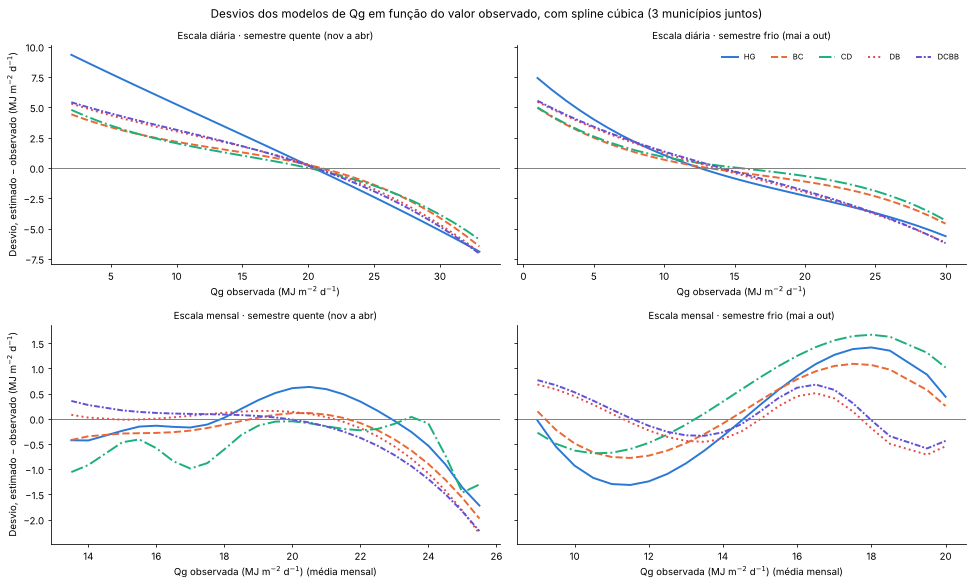

In [29]:
def spline_desvio(obs, desvio, passo=1.0, suav=0.3, n_min=15):
    # Média do desvio em classes do valor observado e spline cúbica de suavização sobre essas médias
    d = pd.DataFrame({'obs': np.asarray(obs), 'desvio': np.asarray(desvio)}).dropna()
    classe = (d['obs'] / passo).round() * passo
    g = d.groupby(classe)['desvio'].agg(['mean', 'size'])
    g = g[g['size'] >= n_min]
    xs, ys = g.index.values, g['mean'].values
    if len(xs) < 5:
        return xs, ys
    return xs, UnivariateSpline(xs, ys, k=3, s=len(xs) * np.var(ys) * suav)(xs)


def pares_desvio(m, per, escala):
    # Observado e desvio (estimado − observado) de todos os municípios, no período e na escala pedidos
    obs, dev = [], []
    for n in NOMES:
        b = BASE_QG[n]
        sel = b.index.month.isin(MESES_SECOS[n])
        sel = sel if per == 'Seco' else ~sel
        o, e = b['Rs'][sel], EST_QG[n][m][sel]
        if escala == 'mensal':
            t = pd.DataFrame({'o': o, 'e': e}).groupby([o.index.year, o.index.month]).mean()
            o, e = t['o'], t['e']
        obs.append(o); dev.append(e - o)
    return pd.concat(obs), pd.concat(dev)


# Desvios com spline, escalas diária e mensal x semestres (equivalente à Fig. 3 de Fernandes et al.)
fig, eixos = plt.subplots(2, 2, figsize=(14, 8.5), sharey='row')
for i, escala in enumerate(('diária', 'mensal')):
    for j, per in enumerate(('Seco', 'Úmido')):
        ax = eixos[i, j]
        for m in ORDEM_QG:
            o, d = pares_desvio(m, per, 'mensal' if escala == 'mensal' else 'diária')
            xs, ys = spline_desvio(o, d, passo=1.0 if escala == 'diária' else 0.5, n_min=15 if escala == 'diária' else 5)
            ax.plot(xs, ys, color=CORES_MODELO[m], ls=ESTILOS_MODELO[m], lw=2, label=m)
        ax.axhline(0, color='0.5', lw=1)
        ax.set_title(f'Escala {escala} · {PER_ROT[per].lower()}', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
        ax.set_xlabel('Qg observada (MJ m$^{-2}$ d$^{-1}$)' + (' (média mensal)' if escala == 'mensal' else ''))
        if j == 0:
            ax.set_ylabel('Desvio, estimado − observado (MJ m$^{-2}$ d$^{-1}$)')
eixos[0, 1].legend(frameon=False, ncol=5, loc='upper right', fontsize=8)
fig.suptitle(f'Desvios dos modelos de Qg em função do valor observado, com spline cúbica ({len(NOMES)} municípios juntos)')
plt.tight_layout()
salva_fig('etapa3_spline_desvios.png')

In [30]:
# Melhor modelo de cada local: maior EF na validação
MELHOR_QG = {n: tabela3.xs((n, 'Validação'), level=('Local', 'Conjunto'))['EF'].idxmax() for n in NOMES}
print('Melhor modelo de Qg (EF na validação):', MELHOR_QG)

ranking = tabela3.xs('Validação', level='Conjunto')['EF'].unstack('Local')[NOMES]
ranking['Média'] = ranking.mean(axis=1)
ranking = ranking.sort_values('Média', ascending=False)

tabela2.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa3_tabela2_parametros_qg.csv'))
tabela3.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa3_tabela3_metricas_qg.csv'))
tabela_dc.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa3_d_c_periodos.csv'))
ranking.round(4)

Melhor modelo de Qg (EF na validação): {'Pato Branco': 'BC', 'Francisco Beltrão': 'CD', 'Dois Vizinhos': 'CD'}


Local,Pato Branco,Francisco Beltrão,Dois Vizinhos,Média
Modelo,,,,
CD,0.7249,0.7315,0.7593,0.7385
BC,0.7269,0.7304,0.7520,0.7364
DB,0.7216,0.7205,0.7464,0.7295
DCBB,0.7179,0.7179,0.7388,0.7249
HG,0.6443,0.6479,0.6794,0.6572


**Os coeficientes são transferíveis?** Cada local é estimado com os parâmetros calibrados em cada um dos outros e também com um conjunto **regional** (calibração única com os anos ímpares de todos os municípios juntos). Se a perda de desempenho for pequena, um único conjunto de coeficientes serve para o Sudoeste.

Maior aumento de RMSE ao transferir coeficientes: 3.7% (['CD', 'Francisco Beltrão', 'Dois Vizinhos'])
Aumento médio com o coeficiente regional: 0.41%


Aplicado em               Pato Branco  Francisco Beltrão  Dois Vizinhos
Modelo Calibrado em                                                    
HG     Pato Branco              4.289              4.331          4.113
       Francisco Beltrão        4.287              4.324          4.121
       Dois Vizinhos            4.327              4.384          4.092
       Regional                 4.293              4.339          4.101
BC     Pato Branco              3.759              3.789          3.622
       Francisco Beltrão        3.759              3.784          3.638
       Dois Vizinhos            3.807              3.860          3.599
       Regional                 3.765              3.802          3.610
CD     Pato Branco              3.772              3.778          3.654
       Francisco Beltrão        3.774              3.776          3.679
       Dois Vizinhos            3.871              3.913          3.546
       Regional                 3.779              3.795          3.603
DB     Pato Branco              3.795              3.833          3.650
       Francisco Beltrão        3.806              3.853          3.700
       Dois Vizinhos            3.826              3.882          3.639
       Regional                 3.808              3.863          3.679
DCBB   Pato Branco              3.820              3.873          3.704
       Francisco Beltrão        3.822              3.870          3.718
       Dois Vizinhos            3.851              3.920          3.694
       Regional                 3.824              3.880          3.698

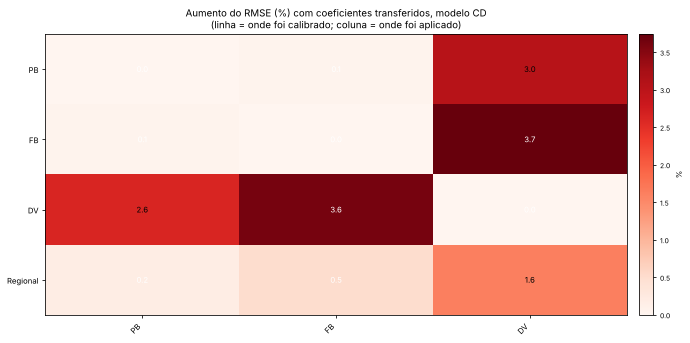

,b,c,Tnc,C1,C2
Modelo,,,,,
HG,0.17595,-2.01163,NaN,NaN,NaN
BC,0.06221,2.25162,NaN,NaN,NaN
CD,0.43070,NaN,300.0,NaN,NaN
DB,0.11665,NaN,NaN,-0.02728,1.6116
DCBB,0.11078,NaN,300.0,-0.02893,1.6056


In [31]:
# Calibração regional: anos ímpares de todos os municípios empilhados
cal_reg = pd.concat([BASE_QG[n][BASE_QG[n]['grupo'] == 'Calibração'] for n in NOMES])
PAR_QG_REG = {m: calibra(info['f'], cal_reg, cal_reg['Rs'].values, info['x0'], info['lim'], N_CHUTES[m])
              for m, info in MODELOS_QG.items()}

reg = []
for m in ORDEM_QG:
    for origem in NOMES + ['Regional']:
        par = PAR_QG_REG[m] if origem == 'Regional' else PAR_QG[origem][m]
        for n_uso in NOMES:
            b = BASE_QG[n_uso]
            val = b['grupo'] == 'Validação'
            est = MODELOS_QG[m]['f'](par, b[val])
            reg.append({'Modelo': m, 'Calibrado em': origem, 'Aplicado em': n_uso, 'RMSE': rmse(b.loc[val, 'Rs'], est)})
transf = pd.DataFrame(reg).pivot_table(index=['Modelo', 'Calibrado em'], columns='Aplicado em', values='RMSE', sort=False)[NOMES]
transf.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa3_transferencia_rmse.csv'))

tabela_reg = pd.DataFrame([{'Modelo': m, **dict(zip(MODELOS_QG[m]['par'], PAR_QG_REG[m]))} for m in ORDEM_QG]).set_index('Modelo')[['b', 'c', 'Tnc', 'C1', 'C2']]
tabela_reg.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa3_parametros_regionais.csv'))

# Perda percentual de RMSE ao trocar o coeficiente local pelo de outro lugar
perda = []
for m in ORDEM_QG:
    for n_uso in NOMES:
        proprio = transf.loc[(m, n_uso), n_uso]
        for origem in NOMES + ['Regional']:
            if origem != n_uso:
                perda.append({'Modelo': m, 'Aplicado em': n_uso, 'Calibrado em': origem,
                              'Aumento do RMSE (%)': 100 * (transf.loc[(m, origem), n_uso] / proprio - 1)})
perda = pd.DataFrame(perda)
print(f"Maior aumento de RMSE ao transferir coeficientes: {perda['Aumento do RMSE (%)'].max():.1f}% "
      f"({perda.loc[perda['Aumento do RMSE (%)'].idxmax(), ['Modelo', 'Calibrado em', 'Aplicado em']].tolist()})")
print(f"Aumento médio com o coeficiente regional: {perda.loc[perda['Calibrado em'] == 'Regional', 'Aumento do RMSE (%)'].mean():.2f}%")
display(transf.round(3))

# Aumento do RMSE (%) do melhor modelo médio ao usar coeficientes de outro município (linhas) em cada município (colunas)
m_ref = ranking.index[0]
tab_tr = pd.DataFrame({n_uso: {orig: 100 * (transf.loc[(m_ref, orig), n_uso] / transf.loc[(m_ref, n_uso), n_uso] - 1)
                               for orig in NOMES + ['Regional']} for n_uso in NOMES})
tab_tr.index = [SIGLA.get(i, i) for i in tab_tr.index]; tab_tr.columns = [SIGLA[n] for n in tab_tr.columns]
fig, ax = plt.subplots(figsize=(10, 5))
mapa_calor(ax, tab_tr, fmt='{:.1f}', cmap='Reds', vmin=0, titulo=f'Aumento do RMSE (%) com coeficientes transferidos, modelo {m_ref}\n(linha = onde foi calibrado; coluna = onde foi aplicado)', barra='%')
plt.tight_layout()
salva_fig('etapa3_transferencia.png')
tabela_reg.round(5)

## Etapa 4 · Modelos de Rn e Priestley-Taylor (Fietz & Fisch, 2009)
___

Quatro modelos de Rn, calibrados contra o Rn FAO-56 da Etapa 2 (anos ímpares):

| Modelo | Equação |
|---|---|
| (1) | Rn = α · Tmax + β · Tmin |
| (2) | Rn = α · (Tmax − Tmin)^β · Qo |
| (3) | Rn = α · Qg |
| (4) | Rn = α · Qg + β · Qo |

**Priestley-Taylor:** ET₀ = α_PT · W · Rn / λ, com α_PT = 1,26, λ = 2,45 MJ kg⁻¹ e G ≈ 0 na escala diária. Fietz & Fisch usam aproximações lineares de W = Δ/(Δ+γ) em função da temperatura, que comparamos com o W exato.

In [32]:
MODELOS_RN = {
    '(1)': dict(f=lambda p, d: p[0] * d['Tmax'] + p[1] * d['Tmin'],                                  par=['α', 'β'], x0=[0.3, 0.0]),
    '(2)': dict(f=lambda p, d: p[0] * np.clip(d['Tmax'] - d['Tmin'], 1e-6, None) ** p[1] * d['Qo'], par=['α', 'β'], x0=[0.05, 0.7]),
    '(3)': dict(f=lambda p, d: p[0] * d['Rs'],                                                      par=['α'],      x0=[0.6]),
    '(4)': dict(f=lambda p, d: p[0] * d['Rs'] + p[1] * d['Qo'],                                     par=['α', 'β'], x0=[0.5, 0.0]),
}
ORDEM_RN = list(MODELOS_RN)

BASE_RN, PAR_RN, EST_RN = {}, {}, {}
for n in NOMES:
    b = SERIES[n][['Tmax', 'Tmin', 'Tmed', 'Qo', 'Rs', 'Rn', 'ET']].dropna().copy()
    b['grupo'] = np.where(b.index.year % 2 == 1, 'Calibração', 'Validação')
    cal = b[b['grupo'] == 'Calibração']
    BASE_RN[n], PAR_RN[n], EST_RN[n] = b, {}, {}
    for m, info in MODELOS_RN.items():
        PAR_RN[n][m] = least_squares(lambda p: np.asarray(info['f'](p, cal)) - cal['Rn'].values, info['x0']).x
        EST_RN[n][m] = pd.Series(np.asarray(info['f'](PAR_RN[n][m], b)), index=b.index)

tabela_par_rn = pd.DataFrame([{'Modelo': m, 'Local': n, **dict(zip(MODELOS_RN[m]['par'], PAR_RN[n][m]))}
                              for m in ORDEM_RN for n in NOMES]).set_index(['Modelo', 'Local'])
tabela_par_rn.round(4)

α       β
Modelo Local                            
(1)    Pato Branco        0.5376 -0.2452
       Francisco Beltrão  0.5420 -0.2525
       Dois Vizinhos      0.4942 -0.1852
(2)    Pato Branco        0.0654  0.6606
       Francisco Beltrão  0.0656  0.6602
       Dois Vizinhos      0.0665  0.6394
(3)    Pato Branco        0.5913     NaN
       Francisco Beltrão  0.5897     NaN
       Dois Vizinhos      0.5912     NaN
(4)    Pato Branco        0.4657  0.0707
       Francisco Beltrão  0.4658  0.0704
       Dois Vizinhos      0.4684  0.0694

In [33]:
reg = []
for n in NOMES:
    b = BASE_RN[n]
    for m in ORDEM_RN:
        for g in ('Calibração', 'Validação'):
            sel = b['grupo'] == g
            est = EST_RN[n][m][sel]
            reg.append({'Modelo': m, 'Local': n, 'Conjunto': g, 'Rn médio': est.mean(),
                        'CV_%': 100 * est.std() / est.mean(), **metricas(b.loc[sel, 'Rn'], est)})
tabela_rn = pd.DataFrame(reg).set_index(['Modelo', 'Local', 'Conjunto'])
print('Rn FAO-56 médio (referência):', {n: round(BASE_RN[n]['Rn'].mean(), 2) for n in NOMES})
tabela_rn.round(3)

Rn FAO-56 médio (referência): {'Pato Branco': np.float64(9.92), 'Francisco Beltrão': np.float64(9.98), 'Dois Vizinhos': np.float64(10.01)}


Rn médio    CV_%   RMSE  RRMSE_%    MAE   Viés     EF     R2      d      c Desempenho
Modelo Local             Conjunto                                                                                         
(1)    Pato Branco       Calibração    10.128  18.319  3.170   32.080  2.665  0.246  0.454  0.555  0.714  0.532   Sofrível
                         Validação     10.153  18.842  3.218   32.309  2.732  0.193  0.462  0.562  0.719  0.539   Sofrível
(2)    Pato Branco       Calibração    10.049  33.468  1.943   19.667  1.485  0.167  0.795  0.810  0.933  0.840  Muito bom
                         Validação     10.135  34.029  1.922   19.302  1.488  0.176  0.808  0.824  0.938  0.851      Ótimo
(3)    Pato Branco       Calibração     9.868  41.691  1.327   13.428  1.121 -0.014  0.904  0.904  0.975  0.927      Ótimo
                         Validação      9.985  42.596  1.307   13.121  1.102  0.026  0.911  0.912  0.977  0.932      Ótimo
(4)    Pato Branco       Calibração    10.096  35.629  1.088   11.010  0.867  0.215  0.936  0.958  0.981  0.960      Ótimo
                         Validação     10.190  36.468  1.075   10.790  0.860  0.230  0.940  0.960  0.982  0.963      Ótimo
(1)    Francisco Beltrão Calibração    10.178  18.664  3.213   32.353  2.709  0.247  0.454  0.550  0.715  0.530   Sofrível
                         Validação     10.197  18.972  3.254   32.419  2.766  0.159  0.462  0.561  0.718  0.538   Sofrível
(2)    Francisco Beltrão Calibração    10.103  33.683  1.964   19.776  1.490  0.173  0.796  0.812  0.933  0.841  Muito bom
                         Validação     10.185  33.922  1.934   19.269  1.504  0.148  0.810  0.828  0.938  0.853      Ótimo
(3)    Francisco Beltrão Calibração     9.919  41.961  1.344   13.530  1.135 -0.011  0.904  0.905  0.975  0.927      Ótimo
                         Validação     10.069  42.682  1.320   13.153  1.113  0.031  0.911  0.912  0.977  0.933      Ótimo
(4)    Francisco Beltrão Calibração    10.149  35.915  1.110   11.182  0.887  0.218  0.935  0.957  0.981  0.959      Ótimo
                         Validação     10.268  36.628  1.090   10.860  0.872  0.230  0.940  0.960  0.982  0.962      Ótimo
(1)    Dois Vizinhos     Calibração    10.195  18.382  3.203   32.161  2.700  0.235  0.445  0.536  0.709  0.519   Sofrível
                         Validação     10.223  18.742  3.275   32.521  2.788  0.154  0.449  0.541  0.710  0.522   Sofrível
(2)    Dois Vizinhos     Calibração    10.147  32.610  1.947   19.552  1.501  0.187  0.795  0.815  0.932  0.841  Muito bom
                         Validação     10.255  32.916  1.937   19.235  1.532  0.186  0.807  0.830  0.936  0.853      Ótimo
(3)    Dois Vizinhos     Calibração     9.952  41.341  1.317   13.227  1.112 -0.008  0.906  0.906  0.975  0.928      Ótimo
                         Validação     10.103  42.293  1.296   12.873  1.094  0.034  0.914  0.914  0.977  0.934      Ótimo
(4)    Dois Vizinhos     Calibração    10.173  35.481  1.093   10.977  0.873  0.213  0.935  0.957  0.981  0.960      Ótimo
                         Validação     10.293  36.375  1.077   10.698  0.863  0.224  0.940  0.960  0.982  0.963      Ótimo

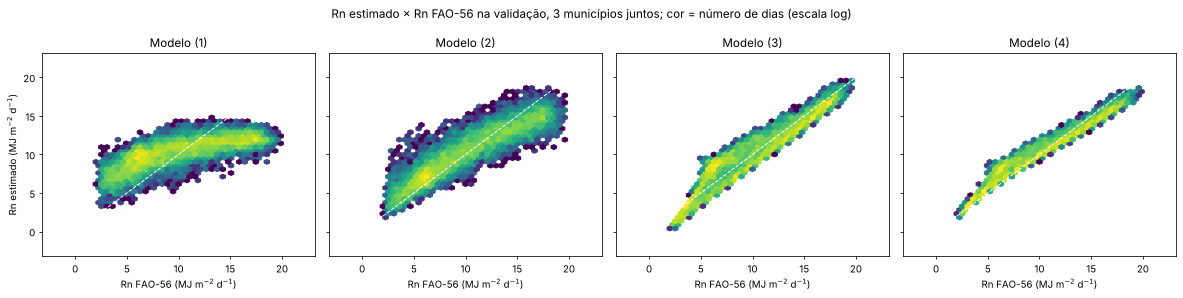

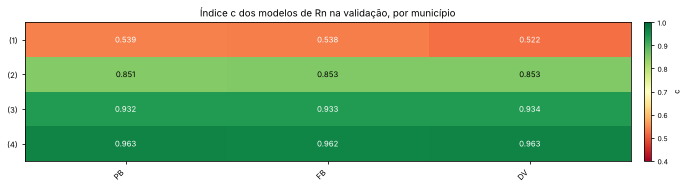

In [34]:
# Dispersão dos quatro modelos de Rn (equivalente à Fig. 1 de Fietz e Fisch), todos os municípios juntos, validação
fig, eixos = plt.subplots(1, len(ORDEM_RN), figsize=(17, 4.3), sharex=True, sharey=True)
for ax, m in zip(eixos, ORDEM_RN):
    obs = pd.concat([BASE_RN[n].loc[BASE_RN[n]['grupo'] == 'Validação', 'Rn'] for n in NOMES])
    est = pd.concat([EST_RN[n][m][BASE_RN[n]['grupo'] == 'Validação'] for n in NOMES])
    ax.hexbin(obs, est, gridsize=45, cmap='viridis', mincnt=1, bins='log', extent=(-2, 22, -2, 22))
    ax.plot([-2, 22], [-2, 22], color='w', ls='--', lw=1)
    met = metricas(obs, est)
    ax.text(0.04, 0.96, f"R²={met['R2']:.3f}\nd={met['d']:.3f}\nc={met['c']:.3f}", transform=ax.transAxes, va='top', fontsize=8, color='w')
    ax.set_title(f'Modelo {m}'); ax.set_xlabel('Rn FAO-56 (MJ m$^{-2}$ d$^{-1}$)')
eixos[0].set_ylabel('Rn estimado (MJ m$^{-2}$ d$^{-1}$)')
fig.suptitle(f'Rn estimado × Rn FAO-56 na validação, {len(NOMES)} municípios juntos; cor = número de dias (escala log)')
plt.tight_layout()
salva_fig('etapa4_dispersao_rn.png')

# Complemento: índice c dos modelos de Rn por município
c_rn = tabela_rn.xs('Validação', level='Conjunto')['c'].unstack('Local')[NOMES].loc[ORDEM_RN]
c_rn.columns = [SIGLA[n] for n in NOMES]
fig, ax = plt.subplots(figsize=(10, 2.8))
mapa_calor(ax, c_rn, fmt='{:.3f}', vmin=0.4, vmax=1, titulo='Índice c dos modelos de Rn na validação, por município', barra='c')
plt.tight_layout()
salva_fig('etapa4_heatmap_rn.png')

**Razão Rn/Qg mensal.** O modelo (3) supõe Rn proporcional a Qg. Como o BOL quase não diminui no inverno enquanto Qg cai, a razão deve cair do verão para o inverno. As linhas pontilhadas são os valores de referência citados por Fietz & Fisch: 0,44 (Dourados, MS, saldo-radiômetro) e 0,57 (Piracicaba, SP).

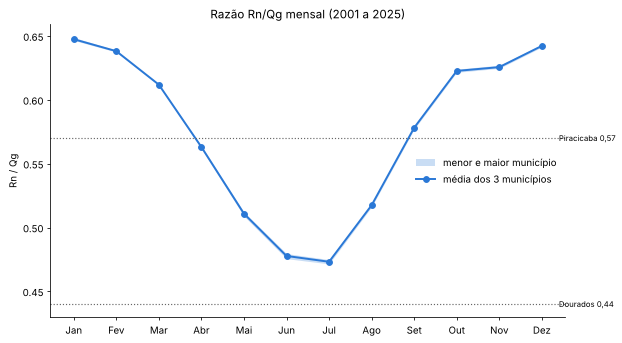

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
Pato Branco,0.649,0.639,0.612,0.564,0.511,0.478,0.473,0.518,0.579,0.624,0.627,0.644
Francisco Beltrão,0.647,0.637,0.611,0.562,0.509,0.476,0.472,0.516,0.577,0.622,0.625,0.641
Dois Vizinhos,0.647,0.638,0.612,0.564,0.512,0.480,0.475,0.518,0.578,0.622,0.625,0.642


In [35]:
RAZAO = {}
for n in NOMES:
    df = SERIES[n].dropna(subset=['Rn', 'Rs'])
    soma = df.groupby(df.index.month)[['Rn', 'Rs']].sum()
    RAZAO[n] = soma['Rn'] / soma['Rs']
tabela_razao = pd.DataFrame(RAZAO); tabela_razao.index = MESES_ABREV

fig, ax = plt.subplots(figsize=(9, 5))
meses = np.arange(1, 13)
ax.fill_between(meses, tabela_razao.min(axis=1), tabela_razao.max(axis=1), color='#2a78d6', alpha=0.25, lw=0, label='menor e maior município')
ax.plot(meses, tabela_razao.mean(axis=1), color='#2a78d6', marker='o', lw=2, label=f'média dos {len(NOMES)} municípios')
ax.axhline(0.44, color='0.4', ls=':', lw=1.2); ax.text(12.4, 0.44, 'Dourados 0,44', va='center', fontsize=8)
ax.axhline(0.57, color='0.4', ls=':', lw=1.2); ax.text(12.4, 0.57, 'Piracicaba 0,57', va='center', fontsize=8)
ax.set_xticks(meses); ax.set_xticklabels(MESES_ABREV)
ax.set_ylabel('Rn / Qg'); ax.set_title(f'Razão Rn/Qg mensal ({PERIODO})')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
plt.tight_layout()
salva_fig('etapa4_razao_rn_qg.png')
tabela_razao.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa4_razao_rn_qg.csv'))
tabela_razao.T.round(3)

**Fator W.** Aproximação linear de Fietz & Fisch × W exato = Δ/(Δ+γ), com Δ pela derivada de Tetens e γ pela pressão atmosférica da altitude (FAO-56).

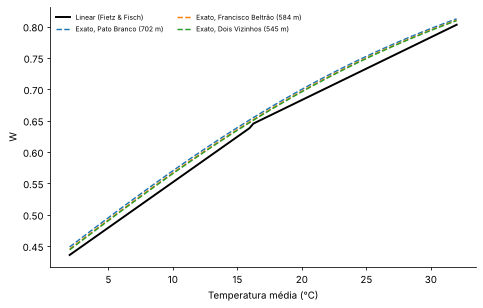

Pato Branco        W linear − W exato: média -0.0174, máx. absoluto 0.0198 | efeito na ETo média: -0.092 mm/d
Francisco Beltrão  W linear − W exato: média -0.0146, máx. absoluto 0.0171 | efeito na ETo média: -0.078 mm/d
Dois Vizinhos      W linear − W exato: média -0.0136, máx. absoluto 0.0162 | efeito na ETo média: -0.073 mm/d


In [36]:
ALFA_PT, LAMBDA = 1.26, 2.45


def W_linear(T):
    T = np.asarray(T, float)
    return np.where(T <= 16, 0.407 + 0.0145 * T, 0.483 + 0.01 * T)


def W_exato(T, z):
    T = np.asarray(T, float)
    delta = 4098 * 0.6108 * np.exp(17.27 * T / (T + 237.3)) / (T + 237.3) ** 2
    P = 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26
    gama = 0.665e-3 * P
    return delta / (delta + gama)


T = np.linspace(2, 32, 100)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(T, W_linear(T), color='k', lw=2, label='Linear (Fietz & Fisch)')
for l in LOCAIS:
    ax.plot(T, W_exato(T, l['altitude_m']), ls='--', color=CORES_LOCAL[l['municipio']], label=f"Exato, {l['municipio']} ({l['altitude_m']:.0f} m)")
ax.set_xlabel('Temperatura média (°C)'); ax.set_ylabel('W'); ax.legend(frameon=False, fontsize=7, ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
salva_fig('etapa4_fator_w.png')

for l in LOCAIS:
    df = SERIES[l['municipio']]
    df['W'] = W_linear(df['Tmed'])
    df['W_exato'] = W_exato(df['Tmed'], l['altitude_m'])
    df['ETo_PT'] = ALFA_PT * df['W'] * df['Rn'] / LAMBDA
    df['ETo_PT_Wexato'] = ALFA_PT * df['W_exato'] * df['Rn'] / LAMBDA
    dif = df['W'] - df['W_exato']
    print(f"{l['municipio']:<18} W linear − W exato: média {dif.mean():+.4f}, máx. absoluto {dif.abs().max():.4f} | "
          f"efeito na ETo média: {(df['ETo_PT'] - df['ETo_PT_Wexato']).mean():+.3f} mm/d")

**Equação local.** Se Rn ≈ α₃ · Qg (modelo 3), Priestley-Taylor vira **ET₀ = k · W · Qg**, com k = α_PT · α₃ / λ.

In [37]:
K_LOCAL = {}
reg = []
for n in NOMES:
    df = SERIES[n]
    K_LOCAL[n] = ALFA_PT * PAR_RN[n]['(3)'][0] / LAMBDA
    df['ETo_local'] = K_LOCAL[n] * df['W'] * df['Rs']
    print(f'{n:<18} ET0 = {K_LOCAL[n]:.4f} · W · Qg')
    val = df.index.year % 2 == 0
    for nome, col in [('Priestley-Taylor (Rn FAO-56, W linear)', 'ETo_PT'), ('Priestley-Taylor (Rn FAO-56, W exato)', 'ETo_PT_Wexato'),
                      ('Equação local k·W·Qg', 'ETo_local')]:
        reg.append({'Local': n, 'Método': nome, **metricas(df.loc[val, 'ET'], df.loc[val, col])})
tabela_pt = pd.DataFrame(reg).set_index(['Local', 'Método'])
tabela_pt.round(3)

Pato Branco        ET0 = 0.3041 · W · Qg
Francisco Beltrão  ET0 = 0.3033 · W · Qg
Dois Vizinhos      ET0 = 0.3040 · W · Qg


RMSE  RRMSE_%    MAE   Viés     EF     R2      d      c Desempenho
Local             Método                                                                                                     
Pato Branco       Priestley-Taylor (Rn FAO-56, W linear)  0.585   16.737  0.446  0.087  0.862  0.885  0.967  0.910      Ótimo
                  Priestley-Taylor (Rn FAO-56, W exato)   0.624   17.860  0.492  0.179  0.843  0.885  0.964  0.907      Ótimo
                  Equação local k·W·Qg                    0.508   14.530  0.390  0.080  0.896  0.905  0.974  0.927      Ótimo
Francisco Beltrão Priestley-Taylor (Rn FAO-56, W linear)  0.573   16.093  0.439  0.056  0.874  0.891  0.970  0.916      Ótimo
                  Priestley-Taylor (Rn FAO-56, W exato)   0.602   16.901  0.473  0.134  0.861  0.891  0.968  0.913      Ótimo
                  Equação local k·W·Qg                    0.499   14.013  0.384  0.051  0.904  0.909  0.976  0.931      Ótimo
Dois Vizinhos     Priestley-Taylor (Rn FAO-56, W linear)  0.589   16.460  0.446  0.045  0.864  0.883  0.968  0.909      Ótimo
                  Priestley-Taylor (Rn FAO-56, W exato)   0.615   17.177  0.477  0.119  0.852  0.883  0.966  0.907      Ótimo
                  Equação local k·W·Qg                    0.506   14.144  0.387  0.040  0.900  0.905  0.975  0.928      Ótimo

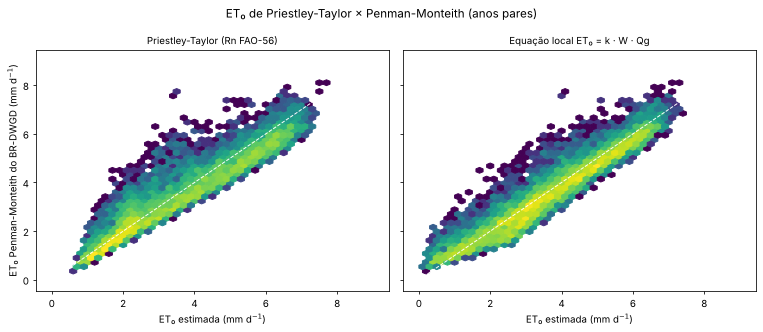

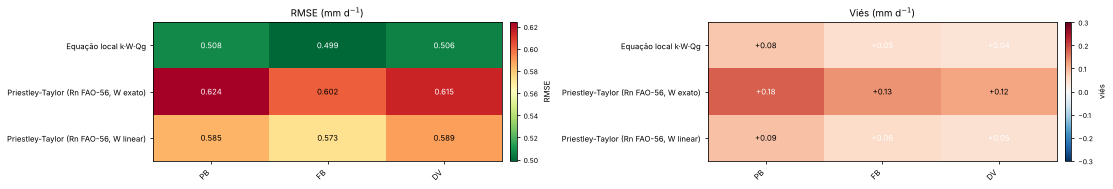

In [38]:
# ETo de Priestley-Taylor x Penman-Monteith (equivalente à Fig. 2 de Fietz e Fisch), anos pares, todos os municípios juntos
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (col, titulo) in zip(eixos, [('ETo_PT', 'Priestley-Taylor (Rn FAO-56)'), ('ETo_local', 'Equação local ET₀ = k · W · Qg')]):
    pm = pd.concat([SERIES[n].loc[SERIES[n].index.year % 2 == 0, 'ET'] for n in NOMES])
    est = pd.concat([SERIES[n].loc[SERIES[n].index.year % 2 == 0, col] for n in NOMES])
    ax.hexbin(est, pm, gridsize=45, cmap='viridis', mincnt=1, bins='log', extent=(0, 9, 0, 9))
    ax.plot([0, 9], [0, 9], color='w', ls='--', lw=1)
    met = metricas(pm, est)
    ax.text(0.04, 0.96, f"R²={met['R2']:.3f}\nd={met['d']:.3f}\nc={met['c']:.3f}\nviés={met['Viés']:+.2f}", transform=ax.transAxes, va='top', fontsize=8, color='w')
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('ET₀ estimada (mm d$^{-1}$)')
eixos[0].set_ylabel('ET₀ Penman-Monteith do BR-DWGD (mm d$^{-1}$)')
fig.suptitle('ET₀ de Priestley-Taylor × Penman-Monteith (anos pares)')
plt.tight_layout()
salva_fig('etapa4_eto_pt_vs_pm.png')

# Complemento: RMSE e viés por município
rm_pt = tabela_pt['RMSE'].unstack('Local')[NOMES]
vs_pt = tabela_pt['Viés'].unstack('Local')[NOMES]
for t in (rm_pt, vs_pt):
    t.columns = [SIGLA[n] for n in NOMES]
fig, eixos = plt.subplots(1, 2, figsize=(16, 2.8))
mapa_calor(eixos[0], rm_pt, fmt='{:.3f}', cmap='RdYlGn_r', titulo='RMSE (mm d$^{-1}$)', barra='RMSE')
mapa_calor(eixos[1], vs_pt, fmt='{:+.2f}', cmap='RdBu_r', vmin=-0.3, vmax=0.3, titulo='Viés (mm d$^{-1}$)', barra='viés')
plt.tight_layout()
salva_fig('etapa4_heatmap_pt.png')

**α_PT sazonal.** Recalibrado por período (regressão pela origem de ETo PM contra W·Rn/λ). Valores acima de 1,26 indicam demanda atmosférica maior que a explicada só pela energia (advecção, ar seco); abaixo, ar úmido e pouco vento.

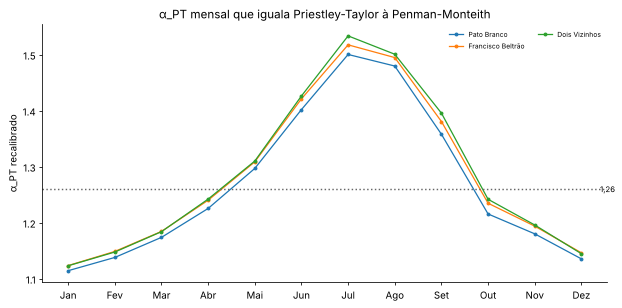

,Todo,Seco,Úmido
Local,,,
Pato Branco,1.197,1.152,1.329
Francisco Beltrão,1.209,1.163,1.347
Dois Vizinhos,1.212,1.163,1.355


In [39]:
reg = []
ALFA_MENSAL = {}
for n in NOMES:
    b = SERIES[n][['W', 'Rn', 'ET']].dropna()
    seco = b.index.month.isin(MESES_SECOS[n])
    X = (b['W'] * b['Rn'] / LAMBDA).values
    y = b['ET'].values
    linha = {'Local': n}
    for per, sel in [('Todo', np.ones(len(b), bool)), ('Seco', seco), ('Úmido', ~seco)]:
        linha[per] = np.sum(y[sel] * X[sel]) / np.sum(X[sel] ** 2) if sel.any() else np.nan
    reg.append(linha)
    ALFA_MENSAL[n] = [np.sum(y[b.index.month == m] * X[b.index.month == m]) / np.sum(X[b.index.month == m] ** 2) for m in range(1, 13)]
tabela_alfa = pd.DataFrame(reg).set_index('Local')

fig, ax = plt.subplots(figsize=(9, 4.5))
for n in NOMES:
    ax.plot(range(1, 13), ALFA_MENSAL[n], marker='o', ms=3, lw=1.3, color=CORES_LOCAL[n], label=n)
ax.axhline(1.26, color='0.4', ls=':'); ax.text(12.4, 1.26, '1,26', va='center', fontsize=8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MESES_ABREV); ax.set_ylabel('α_PT recalibrado')
ax.set_title('α_PT mensal que iguala Priestley-Taylor à Penman-Monteith'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout()
salva_fig('etapa4_alfa_pt_mensal.png')

tabela_par_rn.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa4_parametros_rn.csv'))
tabela_rn.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa4_metricas_rn.csv'))
tabela_pt.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa4_pt_vs_pm.csv'))
tabela_alfa.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa4_alfa_pt.csv'))
tabela_alfa.round(3)

## Etapa 5 · Integração: temperatura → Qg → Rn → ETo
___

Estimativas de ETo, todas comparadas com a ETo Penman-Monteith do BR-DWGD:

| Cenário | Qg | Rn | ETo |
|---|---|---|---|
| (a) | BR-DWGD | FAO-56 (Etapa 2) | Priestley-Taylor |
| (a2) | BR-DWGD | modelo (3) · Qg | Priestley-Taylor (equação local) |
| (b) | **melhor modelo de temperatura** (Etapa 3) | modelo (3) · Qg estimada | Priestley-Taylor |
| (c) | n/a | n/a | Hargreaves-Samani (só temperatura) |

Comparar (a) com (a2) isola o erro de trocar o Rn FAO-56 pelo modelo (3); comparar (a2) com (b) isola o erro que **nasce na estimativa de Qg**. O erro de (a) é o que já vem do Priestley-Taylor, da aproximação de W e do Rn calculado.

> As métricas da Etapa 5 usam só os **anos pares** (validação), para que nenhum coeficiente seja avaliado nos dados em que foi calibrado.

In [40]:
ETO, ETO_TODOS = {}, {}
reg = []
for n in NOMES:
    df = SERIES[n]
    b = BASE_QG[n].join(df[['Tmax', 'W', 'ET', 'ETo_PT', 'ETo_local']], how='inner').dropna()
    m = MELHOR_QG[n]
    qg_est = MODELOS_QG[m]['f'](PAR_QG[n][m], b)
    rn_est = PAR_RN[n]['(3)'][0] * qg_est
    e = pd.DataFrame({
        'PM': b['ET'],
        '(a) PT, Qg BR-DWGD e Rn FAO-56': b['ETo_PT'],
        '(a2) PT, Qg BR-DWGD e Rn = α·Qg': b['ETo_local'],
        f'(b) PT, Qg por temperatura ({m})': ALFA_PT * b['W'] * rn_est / LAMBDA,
        '(c) Hargreaves-Samani': amp.etp_hargreaves_samani(b['Qo'], b['Tmax'], b['Tmin'], b['Tavg']),
    }, index=b.index)
    ETO_TODOS[n] = e
    ETO[n] = e[b['grupo'] == 'Validação']
    for col in e.columns[1:]:
        cen = col.split(' ')[0]
        reg.append({'Local': n, 'Cenário': cen, 'Descrição': col[len(cen) + 1:], **metricas(ETO[n]['PM'], ETO[n][col])})
tabela5 = pd.DataFrame(reg).set_index(['Local', 'Cenário'])
tabela5.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa5_integracao.csv'))
tabela5.round(3)

Descrição   RMSE  RRMSE_%    MAE   Viés     EF     R2      d      c Desempenho
Local             Cenário                                                                                                  
Pato Branco       (a)       PT, Qg BR-DWGD e Rn FAO-56  0.585   16.737  0.446  0.087  0.862  0.885  0.967  0.910      Ótimo
                  (a2)      PT, Qg BR-DWGD e Rn = α·Qg  0.508   14.530  0.390  0.080  0.896  0.905  0.974  0.927      Ótimo
                  (b)      PT, Qg por temperatura (BC)  0.720   20.601  0.560  0.057  0.791  0.796  0.943  0.841  Muito bom
                  (c)                Hargreaves-Samani  0.838   23.980  0.663  0.409  0.717  0.787  0.923  0.818  Muito bom
Francisco Beltrão (a)       PT, Qg BR-DWGD e Rn FAO-56  0.573   16.093  0.439  0.056  0.874  0.891  0.970  0.916      Ótimo
                  (a2)      PT, Qg BR-DWGD e Rn = α·Qg  0.499   14.013  0.384  0.051  0.904  0.909  0.976  0.931      Ótimo
                  (b)      PT, Qg por temperatura (CD)  0.711   19.980  0.554  0.040  0.805  0.807  0.945  0.849  Muito bom
                  (c)                Hargreaves-Samani  0.807   22.658  0.634  0.362  0.750  0.801  0.930  0.832  Muito bom
Dois Vizinhos     (a)       PT, Qg BR-DWGD e Rn FAO-56  0.589   16.460  0.446  0.045  0.864  0.883  0.968  0.909      Ótimo
                  (a2)      PT, Qg BR-DWGD e Rn = α·Qg  0.506   14.144  0.387  0.040  0.900  0.905  0.975  0.928      Ótimo
                  (b)      PT, Qg por temperatura (CD)  0.669   18.698  0.517  0.042  0.825  0.826  0.951  0.864      Ótimo
                  (c)                Hargreaves-Samani  0.841   23.494  0.662  0.473  0.723  0.813  0.926  0.835  Muito bom

In [41]:
# Em que elo nasce o erro? Decomposição do erro quadrático médio (RMSE²) do cenário (b).
# Parcela negativa: aquele elo compensou parte do erro do restante da cadeia (erros de sinais opostos).
def _col(e, cen):
    return [c for c in e.columns if c.startswith(cen + ' ')][0]


reg = []
for n in NOMES:
    e = ETO[n]
    mse = {c: rmse(e['PM'], e[_col(e, c)]) ** 2 for c in ('(a)', '(a2)', '(b)', '(c)')}
    reg.append({'Local': n, 'RMSE (a)': np.sqrt(mse['(a)']), 'RMSE (a2)': np.sqrt(mse['(a2)']), 'RMSE (b)': np.sqrt(mse['(b)']),
                'RMSE (c)': np.sqrt(mse['(c)']),
                'PT + W + Rn FAO-56 (%)': 100 * mse['(a)'] / mse['(b)'],
                'Rn = α·Qg (%)': 100 * (mse['(a2)'] - mse['(a)']) / mse['(b)'],
                'Qg por temperatura (%)': 100 * (mse['(b)'] - mse['(a2)']) / mse['(b)']})
tabela_elo = pd.DataFrame(reg).set_index('Local')
tabela_elo.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa5_origem_erro.csv'))
tabela_elo.round(3)

,RMSE (a),RMSE (a2),RMSE (b),RMSE (c),PT + W + Rn FAO-56 (%),Rn = α·Qg (%),Qg por temperatura (%)
Local,,,,,,,
Pato Branco,0.585,0.508,0.720,0.838,66.006,-16.260,50.254
Francisco Beltrão,0.573,0.499,0.711,0.807,64.881,-15.691,50.809
Dois Vizinhos,0.589,0.506,0.669,0.841,77.490,-20.273,42.783


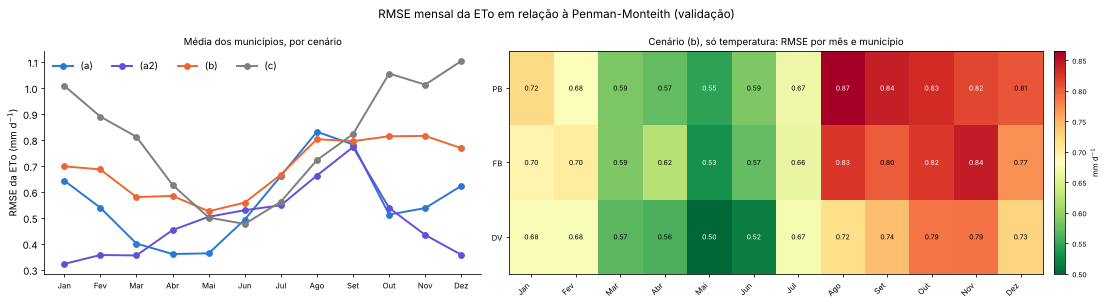

Cenário (b), média dos municípios: maior RMSE em Nov (0.82), menor em Mai (0.53) mm/d


In [42]:
CORES_CEN = {'(a)': '#2a78d6', '(a2)': '#6250d6', '(b)': '#eb6834', '(c)': '#7f7f7f'}
RMSE_MENSAL = {}
for n in NOMES:
    e = ETO[n]
    RMSE_MENSAL[n] = pd.DataFrame({cen: [rmse(e.loc[e.index.month == m, 'PM'], e.loc[e.index.month == m, _col(e, cen)]) for m in range(1, 13)]
                                   for cen in CORES_CEN}, index=MESES_ABREV)

fig, eixos = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1, 1.3]})
for cen, cor in CORES_CEN.items():
    tab = pd.DataFrame({n: RMSE_MENSAL[n][cen] for n in NOMES})
    eixos[0].plot(range(12), tab.mean(axis=1), color=cor, marker='o', lw=2, label=cen)
eixos[0].set_xticks(range(12)); eixos[0].set_xticklabels(MESES_ABREV, fontsize=8)
eixos[0].set_ylabel('RMSE da ETo (mm d$^{-1}$)'); eixos[0].legend(frameon=False, ncol=4)
eixos[0].set_title('Média dos municípios, por cenário', fontsize=10); eixos[0].spines[['top', 'right']].set_visible(False)
tab_b = pd.DataFrame({SIGLA[n]: RMSE_MENSAL[n]['(b)'] for n in NOMES}).T
mapa_calor(eixos[1], tab_b, fmt='{:.2f}', cmap='RdYlGn_r', titulo='Cenário (b), só temperatura: RMSE por mês e município', barra='mm d$^{-1}$', fonte=7)
fig.suptitle('RMSE mensal da ETo em relação à Penman-Monteith (validação)')
plt.tight_layout()
salva_fig('etapa5_rmse_mensal.png')
pd.concat(RMSE_MENSAL, axis=1).to_csv(os.path.join(PASTA_RESULTADOS, 'etapa5_rmse_mensal.csv'))
media_b = pd.DataFrame({n: RMSE_MENSAL[n]['(b)'] for n in NOMES}).mean(axis=1)
print(f"Cenário (b), média dos municípios: maior RMSE em {media_b.idxmax()} ({media_b.max():.2f}), menor em {media_b.idxmin()} ({media_b.min():.2f}) mm/d")

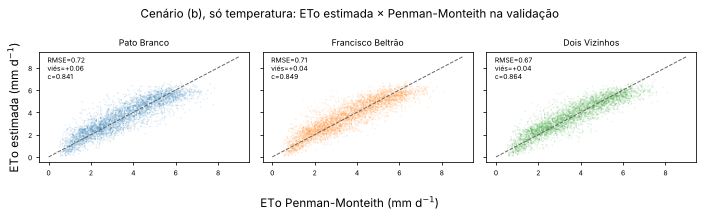

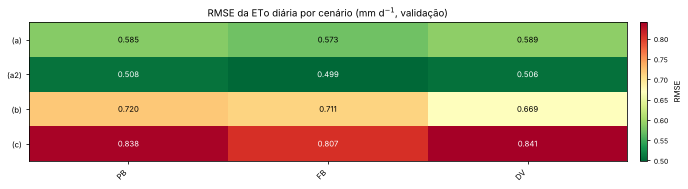

In [43]:
# Cenário (b), só temperatura: ETo estimada x Penman-Monteith em cada município
fig, eixos = grade(len(NOMES), sharex=True, sharey=True)
for ax, n in zip(eixos, NOMES):
    e = ETO[n]
    col = _col(e, '(b)')
    ax.scatter(e['PM'], e[col], s=2, alpha=0.15, color=CORES_LOCAL[n], edgecolors='none')
    ax.plot([0, 9], [0, 9], color='0.4', ls='--', lw=1)
    met = tabela5.loc[(n, '(b)')]
    ax.text(0.04, 0.96, f"RMSE={met['RMSE']:.2f}\nviés={met['Viés']:+.2f}\nc={met['c']:.3f}", transform=ax.transAxes, va='top', fontsize=7)
    ax.set_title(n, fontsize=9); ax.tick_params(labelsize=7)
fig.supxlabel('ETo Penman-Monteith (mm d$^{-1}$)'); fig.supylabel('ETo estimada (mm d$^{-1}$)')
fig.suptitle('Cenário (b), só temperatura: ETo estimada × Penman-Monteith na validação')
plt.tight_layout()
salva_fig('etapa5_dispersao_eto.png')

# RMSE dos quatro cenários em cada município
tab = tabela5['RMSE'].unstack('Local')[NOMES].loc[['(a)', '(a2)', '(b)', '(c)']]
tab.columns = [SIGLA[n] for n in NOMES]
fig, ax = plt.subplots(figsize=(10, 2.8))
mapa_calor(ax, tab, fmt='{:.3f}', cmap='RdYlGn_r', titulo='RMSE da ETo diária por cenário (mm d$^{-1}$, validação)', barra='RMSE')
plt.tight_layout()
salva_fig('etapa5_heatmap_cenarios.png')

**E na escala que importa para o balanço hídrico (P2)?** O erro diário se compensa em parte quando a ETo é somada. A tabela compara os totais **mensais** e **anuais** de ETo dos anos de validação.

In [44]:
reg = []
for n in NOMES:
    e = ETO[n]
    mens = e.groupby([e.index.year, e.index.month]).sum()
    anual = e.groupby(e.index.year).sum()
    for cen in ('(a)', '(a2)', '(b)', '(c)'):
        col = _col(e, cen)
        reg.append({'Local': n, 'Cenário': cen,
                    'RMSE mensal (mm)': rmse(mens['PM'], mens[col]), 'RRMSE mensal (%)': rrmse(mens['PM'], mens[col]),
                    'c mensal': c_camargo(mens['PM'], mens[col]), 'Desempenho mensal': classe_c(c_camargo(mens['PM'], mens[col])),
                    'ETo anual PM (mm)': anual['PM'].mean(), 'ETo anual estimada (mm)': anual[col].mean(),
                    'Viés anual (%)': 100 * (anual[col].mean() / anual['PM'].mean() - 1)})
tabela_acum = pd.DataFrame(reg).set_index(['Local', 'Cenário'])
tabela_acum.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa5_eto_acumulada.csv'))
tabela_acum.round(2)

RMSE mensal (mm)  RRMSE mensal (%)  c mensal Desempenho mensal  ETo anual PM (mm)  ETo anual estimada (mm)  Viés anual (%)
Local             Cenário                                                                                                                            
Pato Branco       (a)                 12.13             11.40      0.94             Ótimo            1276.92                  1308.82            2.50
                  (a2)                 6.72              6.32      0.97             Ótimo            1276.92                  1306.16            2.29
                  (b)                 10.01              9.41      0.94             Ótimo            1276.92                  1297.61            1.62
                  (c)                 17.21             16.17      0.90             Ótimo            1276.92                  1426.42           11.71
Francisco Beltrão (a)                 11.54             10.64      0.95             Ótimo            1301.09                  1321.61            1.58
                  (a2)                 6.22              5.73      0.98             Ótimo            1301.09                  1319.55            1.42
                  (b)                 10.22              9.43      0.94             Ótimo            1301.09                  1315.80            1.13
                  (c)                 15.36             14.17      0.92             Ótimo            1301.09                  1433.51           10.18
Dois Vizinhos     (a)                 12.21             11.20      0.94             Ótimo            1307.76                  1324.32            1.27
                  (a2)                 6.81              6.25      0.97             Ótimo            1307.76                  1322.53            1.13
                  (b)                  9.08              8.33      0.95             Ótimo            1307.76                  1323.09            1.17
                  (c)                 17.92             16.44      0.91             Ótimo            1307.76                  1480.73           13.23

## Etapa 6 · Complemento: El Niño-Oscilação Sul (ENOS)
___

No trabalho da Aula 01 o grupo perguntou se, em anos de El Niño, a maior nebulosidade reduz a radiação e a ETo no Sudoeste, e **se os modelos de Qg por temperatura continuam funcionando nesses anos**. Esta etapa responde com os dados do P1.

**Classificação das safras.** Cada safra de verão (outubro do ano A a março do ano A+1) é classificada pelo Índice Oceânico Niño (ONI, NOAA/CPC) do trimestre novembro-dezembro-janeiro: **El Niño** se ONI ≥ +0,5, **La Niña** se ONI ≤ −0,5, **Neutro** nos demais casos. É uma simplificação do critério oficial da NOAA (que exige cinco trimestres móveis consecutivos), suficiente para separar as safras por fase.

Fonte do ONI: NOAA Climate Prediction Center, <https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt> (consulta em 09/11/2026).

In [45]:
# ONI do trimestre NDJ, indexado pelo ano de início da safra (NOAA/CPC)
ONI_NDJ = {2001: -0.32, 2002: 1.08, 2003: 0.29, 2004: 0.71, 2005: -0.82, 2006: 0.88, 2007: -1.72, 2008: -0.79,
           2009: 1.50, 2010: -1.48, 2011: -0.92, 2012: -0.03, 2013: -0.11, 2014: 0.80, 2015: 2.59, 2016: -0.37,
           2017: -0.76, 2018: 1.05, 2019: 0.75, 2020: -1.06, 2021: -0.83, 2022: -0.70, 2023: 1.99, 2024: -0.43}
FASES = ['La Niña', 'Neutro', 'El Niño']
CORES_FASE = {'La Niña': '#2a78d6', 'Neutro': '#9a9a9a', 'El Niño': '#e34948'}


def fase_enos(oni):
    return 'El Niño' if oni >= 0.5 else ('La Niña' if oni <= -0.5 else 'Neutro')


reg = []
for n in NOMES:
    df = SERIES[n]
    e = ETO_TODOS[n]
    for ano, oni in ONI_NDJ.items():
        ini, fim = f'{ano}-10-01', f'{ano + 1}-03-31'
        d, ee_ = df.loc[ini:fim], e.loc[ini:fim]
        if len(d) < 170:
            continue
        m = MELHOR_QG[n]
        qg_obs, qg_est = BASE_QG[n].loc[ini:fim, 'Rs'], EST_QG[n][m].loc[ini:fim]
        reg.append({'Local': n, 'Safra': f'{ano}/{str(ano + 1)[2:]}', 'ONI': oni, 'Fase': fase_enos(oni),
                    'Chuva (mm)': d['pr'].sum(), 'Qg (MJ m⁻² d⁻¹)': d['Rs'].mean(), 'Kt': d['Kt'].mean(),
                    'Amplitude (°C)': (d['Tmax'] - d['Tmin']).mean(), 'ETo PM (mm)': d['ET'].sum(),
                    'P − ETo (mm)': d['pr'].sum() - d['ET'].sum(),
                    'RMSE Qg (MJ m⁻² d⁻¹)': rmse(qg_obs, qg_est), 'Viés Qg (MJ m⁻² d⁻¹)': vies(qg_obs, qg_est),
                    'RMSE ETo (b) (mm d⁻¹)': rmse(ee_['PM'], ee_[_col(ee_, '(b)')]),
                    'Viés ETo (b) (mm d⁻¹)': vies(ee_['PM'], ee_[_col(ee_, '(b)')])})
safras = pd.DataFrame(reg)
safras.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa6_safras_enos.csv'), index=False)
print('Municípios:', len(NOMES), '| safras por fase:', safras[safras['Local'] == NOMES[0]]['Fase'].value_counts().reindex(FASES).to_dict())
safras[safras['Local'] == NOMES[0]][['Safra', 'ONI', 'Fase']].set_index('Safra').T

Municípios: 3 | safras por fase: {'La Niña': 9, 'Neutro': 6, 'El Niño': 9}


Safra,2001/02,2002/03,2003/04,2004/05,2005/06,2006/07,2007/08,2008/09,2009/10,2010/11,2011/12,2012/13,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25
ONI,-0.32,1.08,0.29,0.71,-0.82,0.88,-1.72,-0.79,1.5,-1.48,-0.92,-0.03,-0.11,0.8,2.59,-0.37,-0.76,1.05,0.75,-1.06,-0.83,-0.7,1.99,-0.43
Fase,Neutro,El Niño,Neutro,El Niño,La Niña,El Niño,La Niña,La Niña,El Niño,La Niña,La Niña,Neutro,Neutro,El Niño,El Niño,Neutro,La Niña,El Niño,El Niño,La Niña,La Niña,La Niña,El Niño,Neutro


In [46]:
VARS_ENOS = ['Chuva (mm)', 'Qg (MJ m⁻² d⁻¹)', 'Kt', 'ETo PM (mm)', 'P − ETo (mm)', 'RMSE Qg (MJ m⁻² d⁻¹)',
             'Viés Qg (MJ m⁻² d⁻¹)', 'RMSE ETo (b) (mm d⁻¹)', 'Viés ETo (b) (mm d⁻¹)']
media_fase = safras.groupby(['Local', 'Fase'])[VARS_ENOS].mean().reindex(pd.MultiIndex.from_product([NOMES, FASES]))

# Kruskal-Wallis entre as três fases e correlação de Spearman com o ONI
reg = []
for n in NOMES:
    s = safras[safras['Local'] == n]
    for v in VARS_ENOS:
        grupos = [s.loc[s['Fase'] == f, v].values for f in FASES]
        H, p_kw = stats.kruskal(*grupos)
        rho, p_rho = stats.spearmanr(s['ONI'], s[v])
        reg.append({'Local': n, 'Variável': v, 'El Niño − La Niña': grupos[2].mean() - grupos[0].mean(),
                    'Kruskal-Wallis p': p_kw, 'Spearman ρ (ONI)': rho, 'Spearman p': p_rho})
testes_enos = pd.DataFrame(reg).set_index(['Local', 'Variável'])
media_fase.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa6_media_por_fase.csv'))
testes_enos.to_csv(os.path.join(PASTA_RESULTADOS, 'etapa6_testes_enos.csv'))
display(media_fase.round(2))
testes_enos.round(3)

Chuva (mm)  Qg (MJ m⁻² d⁻¹)    Kt  ETo PM (mm)  P − ETo (mm)  RMSE Qg (MJ m⁻² d⁻¹)  Viés Qg (MJ m⁻² d⁻¹)  RMSE ETo (b) (mm d⁻¹)  Viés ETo (b) (mm d⁻¹)
Pato Branco       La Niña      978.30            20.82  0.52       815.84        162.46                  4.01                 -0.03                   0.72                   0.05
                  Neutro      1034.25            20.65  0.51       797.46        236.79                  3.79                  0.21                   0.73                   0.17
                  El Niño     1121.19            19.84  0.50       775.66        345.52                  3.89                  0.47                   0.77                   0.20
Francisco Beltrão La Niña     1009.91            21.08  0.52       833.91        176.00                  4.14                 -0.12                   0.73                  -0.01
                  Neutro      1071.88            20.95  0.52       818.88        253.00                  3.84                  0.27                   0.73                   0.12
                  El Niño     1191.78            20.02  0.50       789.64        402.14                  4.00                  0.24                   0.76                   0.10
Dois Vizinhos     La Niña     1051.43            21.13  0.53       837.02        214.41                  4.02                 -0.29                   0.71                  -0.05
                  Neutro      1026.34            20.89  0.52       818.36        207.98                  3.69                  0.23                   0.70                   0.11
                  El Niño     1132.83            20.04  0.50       790.71        342.12                  3.81                 -0.09                   0.72                   0.04

El Niño − La Niña  Kruskal-Wallis p  Spearman ρ (ONI)  Spearman p
Local             Variável                                                                                
Pato Branco       Chuva (mm)                       142.890             0.122             0.561       0.004
                  Qg (MJ m⁻² d⁻¹)                   -0.981             0.094            -0.482       0.017
                  Kt                                -0.023             0.191            -0.431       0.035
                  ETo PM (mm)                      -40.177             0.291            -0.397       0.055
                  P − ETo (mm)                     183.067             0.163             0.527       0.008
                  RMSE Qg (MJ m⁻² d⁻¹)              -0.128             0.848             0.044       0.837
                  Viés Qg (MJ m⁻² d⁻¹)               0.500             0.739             0.139       0.517
                  RMSE ETo (b) (mm d⁻¹)              0.045             0.303             0.484       0.016
                  Viés ETo (b) (mm d⁻¹)              0.146             0.402             0.256       0.228
Francisco Beltrão Chuva (mm)                       181.864             0.236             0.532       0.007
                  Qg (MJ m⁻² d⁻¹)                   -1.063             0.106            -0.455       0.026
                  Kt                                -0.025             0.171            -0.410       0.047
                  ETo PM (mm)                      -44.272             0.182            -0.437       0.033
                  P − ETo (mm)                     226.135             0.254             0.524       0.009
                  RMSE Qg (MJ m⁻² d⁻¹)              -0.147             0.472            -0.101       0.639
                  Viés Qg (MJ m⁻² d⁻¹)               0.352             0.873             0.017       0.939
                  RMSE ETo (b) (mm d⁻¹)              0.032             0.169             0.345       0.098
                  Viés ETo (b) (mm d⁻¹)              0.117             0.444             0.146       0.496
Dois Vizinhos     Chuva (mm)                        81.401             0.661             0.381       0.066
                  Qg (MJ m⁻² d⁻¹)                   -1.094             0.110            -0.469       0.021
                  Kt                                -0.025             0.129            -0.456       0.025
                  ETo PM (mm)                      -46.308             0.224            -0.370       0.075
                  P − ETo (mm)                     127.709             0.516             0.419       0.041
                  RMSE Qg (MJ m⁻² d⁻¹)              -0.208             0.612            -0.047       0.828
                  Viés Qg (MJ m⁻² d⁻¹)               0.195             0.350             0.084       0.695
                  RMSE ETo (b) (mm d⁻¹)              0.007             0.848             0.171       0.424
                  Viés ETo (b) (mm d⁻¹)              0.090             0.498             0.050       0.818

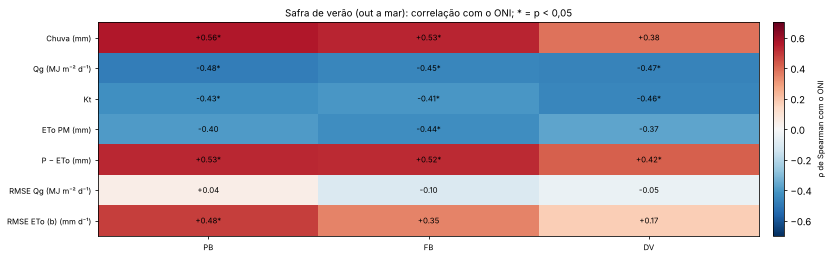

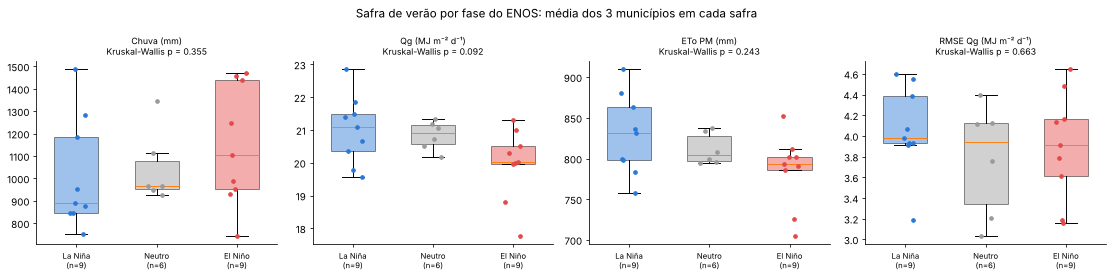

In [47]:
# Correlação de Spearman com o ONI: variáveis x municípios (* = p < 0,05)
VARS_FIG = ['Chuva (mm)', 'Qg (MJ m⁻² d⁻¹)', 'Kt', 'ETo PM (mm)', 'P − ETo (mm)', 'RMSE Qg (MJ m⁻² d⁻¹)', 'RMSE ETo (b) (mm d⁻¹)']
rho = testes_enos['Spearman ρ (ONI)'].unstack('Local')[NOMES].loc[VARS_FIG]
pv = testes_enos['Spearman p'].unstack('Local')[NOMES].loc[VARS_FIG]
fig, ax = plt.subplots(figsize=(12, 3.8))
rho_s = rho.copy(); rho_s.columns = [SIGLA[n] for n in NOMES]
im = ax.imshow(rho_s.values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
for i in range(rho.shape[0]):
    for j in range(rho.shape[1]):
        ax.text(j, i, f"{rho.values[i, j]:+.2f}{'*' if pv.values[i, j] < 0.05 else ''}", ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(NOMES))); ax.set_xticklabels(rho_s.columns, fontsize=8)
ax.set_yticks(range(len(VARS_FIG))); ax.set_yticklabels(VARS_FIG, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label('ρ de Spearman com o ONI', fontsize=8)
ax.set_title('Safra de verão (out a mar): correlação com o ONI; * = p < 0,05', fontsize=10)
plt.tight_layout()
salva_fig('etapa6_enos_spearman.png')

# Média regional de cada safra (média dos municípios), por fase do ENOS
paineis = ['Chuva (mm)', 'Qg (MJ m⁻² d⁻¹)', 'ETo PM (mm)', 'RMSE Qg (MJ m⁻² d⁻¹)']
reg_safra = safras.groupby(['Safra', 'Fase', 'ONI'])[paineis].mean().reset_index()
fig, eixos = plt.subplots(1, len(paineis), figsize=(16, 4))
rng = np.random.default_rng(1)
for ax, v in zip(eixos, paineis):
    dados = [reg_safra.loc[reg_safra['Fase'] == f, v].values for f in FASES]
    bp = ax.boxplot(dados, patch_artist=True, widths=0.55, showfliers=False)
    for caixa, f in zip(bp['boxes'], FASES):
        caixa.set(facecolor=CORES_FASE[f], alpha=0.45)
    for k, (f, d) in enumerate(zip(FASES, dados)):
        ax.scatter(k + 1 + rng.uniform(-0.12, 0.12, len(d)), d, s=14, color=CORES_FASE[f], zorder=3)
    p = stats.kruskal(*dados).pvalue
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels([f'{f}\n(n={len(d)})' for f, d in zip(FASES, dados)], fontsize=8)
    ax.set_title(f'{v}\nKruskal-Wallis p = {p:.3f}', fontsize=9); ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Safra de verão por fase do ENOS: média dos {len(NOMES)} municípios em cada safra')
plt.tight_layout()
salva_fig('etapa6_enos_boxplots.png')

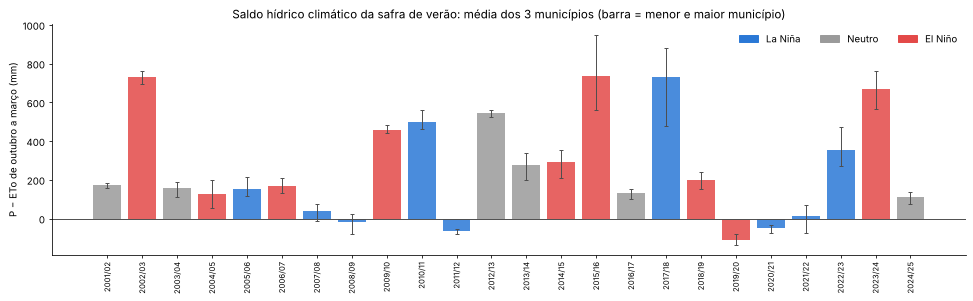

In [48]:
fig, ax = plt.subplots(figsize=(14, 4.4))
tab = safras.pivot_table(index='Safra', columns='Local', values='P − ETo (mm)')[NOMES]
fase = safras.drop_duplicates('Safra').set_index('Safra')['Fase'].reindex(tab.index)
x = np.arange(len(tab))
ax.bar(x, tab.mean(axis=1), color=[CORES_FASE[f] for f in fase], alpha=0.85)
ax.errorbar(x, tab.mean(axis=1), yerr=[tab.mean(axis=1) - tab.min(axis=1), tab.max(axis=1) - tab.mean(axis=1)], fmt='none', ecolor='0.3', lw=1, capsize=2)
ax.axhline(0, color='0.3', lw=1)
ax.set_xticks(x); ax.set_xticklabels(tab.index, rotation=90, fontsize=8)
ax.set_ylabel('P − ETo de outubro a março (mm)'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CORES_FASE[f]) for f in FASES], labels=FASES, frameon=False, ncol=3)
ax.set_title(f'Saldo hídrico climático da safra de verão: média dos {len(NOMES)} municípios (barra = menor e maior município)')
plt.tight_layout()
salva_fig('etapa6_enos_saldo_hidrico.png')

In [49]:
# Base final de cada local, com todas as variáveis calculadas
for n in NOMES:
    SERIES[n].to_csv(os.path.join(PASTA_DADOS, f'serie_final_{SLUG[n]}_{ANO_INICIO}_{ANO_FIM}.csv'))
print('Resultados em:', os.path.abspath(PASTA_RESULTADOS))
print('Figuras em:   ', os.path.abspath(PASTA_FIGURAS))

Resultados em: /tmp/claude-0/-home-user-relacoes-fisicas-ambiente/4f9e1bc9-1477-5607-83a4-040dff73a459/scratchpad/run_final/resultados
Figuras em:    /tmp/claude-0/-home-user-relacoes-fisicas-ambiente/4f9e1bc9-1477-5607-83a4-040dff73a459/scratchpad/run_final/figuras


## Etapa 7 · Complemento: previsão de chuva (ECMWF IFS)
___

Até aqui o trabalho olhou para o **passado**. Esta seção olha para os **próximos 15 dias**: a previsão de precipitação acumulada do modelo **IFS do ECMWF** (Centro Europeu), o modelo global que costuma ter o melhor desempenho para o Sul do Brasil. É o mesmo produto dos mapas de "precipitação acumulada em 96 horas" que circulam para o Paraná e o Sul.

| Item | Valor |
|---|---|
| Coleção no GEE | `ECMWF/NRT_FORECAST/IFS/OPER` (previsão operacional em tempo quase real) |
| Banda | `total_precipitation_sfc`, em metros, **acumulada desde o início da rodada** (convertida para mm) |
| Resolução | 0,25° (cerca de 28 km) |
| Rodadas | 00, 06, 12 e 18 UTC; as de 00 e 12 UTC vão até 360 h (15 dias) |
| Passo | 3 h até 144 h e 6 h de 144 a 360 h |

Como a banda já é acumulada, a chuva prevista em 96 h é simplesmente a imagem de `forecast_hours = 96`, e a chuva de um dia é a diferença entre dois horizontes separados por 24 h.

**Como a etapa funciona.** Com o Earth Engine conectado, a célula baixa a rodada mais recente (grade 0,25° do Sul do Brasil, limites dos estados e a série de cada município) e salva tudo em `dados/previsao_ecmwf/`. Sem conexão, usa a última rodada salva, então o notebook roda inteiro mesmo fora do Colab. **A previsão muda a cada rodada:** para a apresentação, rodem esta etapa de novo no dia.

> ⚠️ Previsão não é observação. Com pixel de 28 km o modelo não resolve a chuva convectiva local, e o erro cresce rápido depois de 5 a 7 dias. Os horizontes longos (240 e 360 h) servem para indicar tendência, não volume.

In [50]:
import json
import time
import matplotlib.colors as mcolors
from matplotlib.path import Path
from scipy.ndimage import zoom

PASTA_PREV = os.path.join(PASTA_DADOS, 'previsao_ecmwf')
os.makedirs(PASTA_PREV, exist_ok=True)
ATUALIZAR_PREVISAO = True                 # False: usa a última rodada salva, sem consultar o Earth Engine
HORIZONTE_H = 96                          # horizonte dos mapas principais (h)
HORIZONTES = [24, 48, 72, 96, 120, 168, 240, 360]
BBOX_SUL = [-58.125, -34.125, -47.625, -22.125]   # bordas da grade 0,25° (oeste, sul, leste, norte)


def _aneis(g):
    if g['type'] == 'Polygon':
        return g['coordinates']
    if g['type'] == 'MultiPolygon':
        return [r for p in g['coordinates'] for r in p]
    if g['type'] == 'GeometryCollection':
        return [r for gg in g['geometries'] for r in _aneis(gg)]
    return []


def baixa_previsao():
    # Rodada mais recente do IFS: grade do Sul, limites estaduais e série acumulada de cada município
    ee = conecta_ee()
    col = ee.ImageCollection('ECMWF/NRT_FORECAST/IFS/OPER')
    agora = ee.Date(int(time.time() * 1000))
    recentes = col.filterDate(agora.advance(-2, 'day'), agora)
    # rodada mais recente que já chegou a 360 h (as de 00 e 12 UTC)
    completas = recentes.filter(ee.Filter.eq('forecast_hours', 360))
    init = ee.Number(completas.aggregate_max('creation_time')).getInfo()
    run = col.filter(ee.Filter.eq('creation_time', init)).select('total_precipitation_sfc')
    fhs = run.aggregate_array('forecast_hours').getInfo()
    rect = ee.Geometry.Rectangle(BBOX_SUL, None, False)
    transf = [0.25, 0, BBOX_SUL[0], 0, -0.25, BBOX_SUL[3]]
    grades = {}
    for h in [h for h in HORIZONTES if h in fhs]:
        im = ee.Image(run.filter(ee.Filter.eq('forecast_hours', h)).first()).multiply(1000)
        im = im.reproject(crs='EPSG:4326', crsTransform=transf)
        a = im.sampleRectangle(region=rect, defaultValue=-1).get('total_precipitation_sfc').getInfo()
        grades[str(h)] = [[round(v, 1) for v in linha] for linha in a]

    mun = (ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM1_NAME', 'Parana'))
           .filter(ee.Filter.inList('ADM2_NAME', list(NOME_GAUL.values()))))

    def por_municipio(im):
        r = im.multiply(1000).reduceRegions(collection=mun, reducer=ee.Reducer.mean(), scale=5000)
        d = ee.Dictionary.fromLists(r.aggregate_array('ADM2_NAME'), r.aggregate_array('mean'))
        return ee.Feature(None, d.set('fh', im.get('forecast_hours')))

    props = [f['properties'] for f in ee.FeatureCollection(run.map(por_municipio)).getInfo()['features']]
    gaul_para_nome = {v: k for k, v in NOME_GAUL.items()}
    serie = sorted([{'fh': p['fh'], **{gaul_para_nome[k]: v for k, v in p.items() if k in gaul_para_nome}} for p in props],
                   key=lambda s: s['fh'])

    est = (ee.FeatureCollection('FAO/GAUL/2015/level1').filter(ee.Filter.eq('ADM0_NAME', 'Brazil'))
           .filter(ee.Filter.inList('ADM1_NAME', ['Parana', 'Santa Catarina', 'Rio Grande Do Sul'])))
    nomes_est = {'Parana': 'Paraná', 'Santa Catarina': 'Santa Catarina', 'Rio Grande Do Sul': 'Rio Grande do Sul'}
    limites = {}
    for g, n in nomes_est.items():
        geo = est.filter(ee.Filter.eq('ADM1_NAME', g)).geometry().simplify(2000).getInfo()
        limites[n] = [[[round(x, 3), round(y, 3)] for x, y in anel] for anel in _aneis(geo) if len(anel) > 8]

    rodada = pd.Timestamp(init, unit='ms').strftime('%Y-%m-%dT%H:%M:%S.000Z')
    return {'fonte': 'ECMWF/NRT_FORECAST/IFS/OPER',
            'banda': 'total_precipitation_sfc (m, acumulada desde a rodada; convertida para mm)',
            'rodada_utc': rodada, 'bbox_bordas': BBOX_SUL, 'resolucao_graus': 0.25,
            'horizontes_h': [int(h) for h in grades], 'grades_mm': grades,
            'serie_municipios_mm': serie, 'limites_estados': limites}


def carrega_previsao():
    prev = None
    if ATUALIZAR_PREVISAO:
        try:
            prev = baixa_previsao()
            nome = 'previsao_ecmwf_' + prev['rodada_utc'][:13].replace('-', '').replace('T', '') + 'Z.json'
            with open(os.path.join(PASTA_PREV, nome), 'w', encoding='utf-8') as f:
                json.dump(prev, f)
            print('Rodada baixada do Earth Engine e salva em', nome)
        except Exception as erro:
            print(f'Earth Engine indisponível ({type(erro).__name__}); usando a última rodada salva.')
    if prev is None:
        arquivos = sorted(glob.glob(os.path.join(PASTA_PREV, 'previsao_ecmwf_*.json')))
        if not arquivos:
            raise FileNotFoundError('Nenhuma rodada salva em ' + PASTA_PREV + '. Conecte o Earth Engine e rode de novo.')
        with open(arquivos[-1], encoding='utf-8') as f:
            prev = json.load(f)
        print('Usando a rodada salva', os.path.basename(arquivos[-1]))
    prev['grades_mm'] = {int(h): np.array(g, float) for h, g in prev['grades_mm'].items()}
    prev['rodada'] = pd.Timestamp(prev['rodada_utc']).tz_convert('UTC')
    return prev


try:
    PREV = carrega_previsao()
except FileNotFoundError as erro:
    PREV = None
    print('Etapa 7 pulada:', erro)

if PREV is not None:
    RODADA = PREV['rodada']
    print(f"Rodada: {RODADA:%d/%m/%Y %H} UTC ({RODADA.tz_convert('America/Sao_Paulo'):%d/%m %H}h de Brasília) | "
          f"horizontes: {PREV['horizontes_h']} h | grade {PREV['grades_mm'][24].shape}")

Earth Engine indisponível (ModuleNotFoundError); usando a última rodada salva.
Usando a rodada salva previsao_ecmwf_2026110912Z.json
Rodada: 09/11/2026 12 UTC (09/11 09h de Brasília) | horizontes: [24, 48, 72, 96, 120, 168, 240, 360] h | grade (48, 42)


**Mapas de chuva acumulada.** Mesma escala de cores para o Paraná e para os três estados do Sul. A grade de 0,25° é interpolada para suavizar o desenho, e tudo fora dos limites estaduais é mascarado. Os pontos pretos são os municípios do grupo.

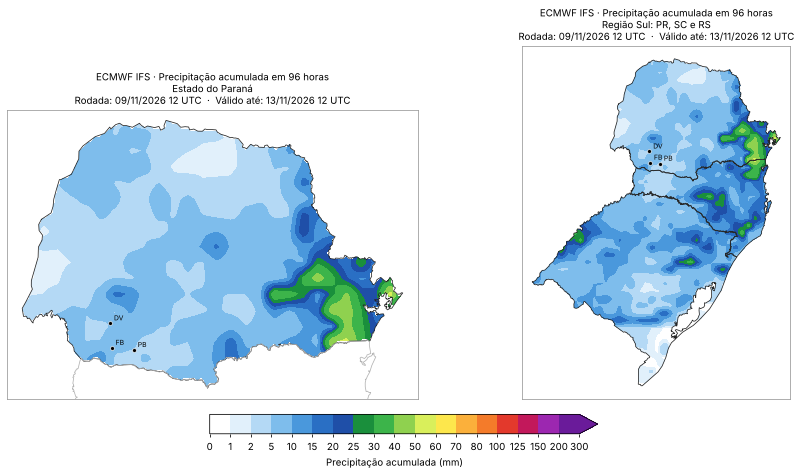

In [51]:
if PREV is not None:
    NIVEIS_CHUVA = [0, 1, 2, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 100, 125, 150, 200, 300]
    CORES_CHUVA = ['#ffffff', '#e1f0fb', '#b4d9f5', '#7ebdec', '#4a98dc', '#2a6fc4', '#1f4fa8', '#1a8f3c',
                   '#3cb44a', '#8fd14f', '#d9ef5b', '#fde74c', '#fbb03b', '#f47b2a', '#e3392c', '#c2185b',
                   '#9c27b0', '#6a1b9a']
    CMAP_CHUVA = mcolors.ListedColormap(CORES_CHUVA)
    NORM_CHUVA = mcolors.BoundaryNorm(NIVEIS_CHUVA, CMAP_CHUVA.N)


    def _grade_fina(prev, h, fator=6):
        # Interpola a grade 0,25° (bilinear) e devolve longitudes, latitudes e chuva em mm
        g = prev['grades_mm'][h].copy()
        g[g < 0] = np.nan
        oeste, sul, leste, norte = prev['bbox_bordas']
        lon = oeste + 0.125 + 0.25 * np.arange(g.shape[1])
        lat = norte - 0.125 - 0.25 * np.arange(g.shape[0])
        gz = zoom(np.nan_to_num(g), fator, order=1)
        lonz = np.linspace(lon[0], lon[-1], gz.shape[1])
        latz = np.linspace(lat[0], lat[-1], gz.shape[0])
        return lonz, latz, gz


    def _mascara_estados(prev, lonz, latz, estados):
        LON, LAT = np.meshgrid(lonz, latz)
        pts = np.column_stack([LON.ravel(), LAT.ravel()])
        dentro = np.zeros(len(pts), bool)
        for e in estados:
            for anel in prev['limites_estados'][e]:
                dentro |= Path(anel).contains_points(pts)
        return dentro.reshape(LON.shape)


    def mapa_previsao(ax, prev, h, estados, titulo=None, cidades=True, rotulos=True):
        lonz, latz, gz = _grade_fina(prev, h)
        gz = np.where(_mascara_estados(prev, lonz, latz, estados), gz, np.nan)
        cf = ax.contourf(lonz, latz, gz, levels=NIVEIS_CHUVA, cmap=CMAP_CHUVA, norm=NORM_CHUVA, extend='max')
        for e in prev['limites_estados']:
            for anel in prev['limites_estados'][e]:
                a = np.array(anel)
                ax.plot(a[:, 0], a[:, 1], color='0.15' if e in estados else '0.7', lw=0.8)
        if cidades:
            for l in LOCAIS:
                ax.plot(l['lon'], l['lat'], 'o', ms=4, color='k', mec='white', mew=0.6)
                if rotulos:
                    ax.annotate(SIGLA[l['municipio']], (l['lon'], l['lat']), xytext=(4, 3), textcoords='offset points', fontsize=7)
        pts = np.vstack([np.array(anel) for e in estados for anel in prev['limites_estados'][e]])
        mx, my = 0.04 * np.ptp(pts[:, 0]), 0.04 * np.ptp(pts[:, 1])
        ax.set_xlim(pts[:, 0].min() - mx, pts[:, 0].max() + mx)
        ax.set_ylim(pts[:, 1].min() - my, pts[:, 1].max() + my)
        ax.set_aspect(1 / np.cos(np.radians(pts[:, 1].mean())))
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_color('0.6')
        if titulo:
            ax.set_title(titulo, fontsize=10)
        return cf


    def subtitulo(prev, h):
        validade = prev['rodada'] + pd.Timedelta(hours=h)
        return f"Rodada: {prev['rodada']:%d/%m/%Y %H} UTC  ·  Válido até: {validade:%d/%m/%Y %H} UTC"


    fig, eixos = plt.subplots(1, 2, figsize=(15, 7.2), gridspec_kw={'width_ratios': [1.25, 1]})
    for ax, (estados, nome) in zip(eixos, [(['Paraná'], 'Estado do Paraná'),
                                           (['Paraná', 'Santa Catarina', 'Rio Grande do Sul'], 'Região Sul: PR, SC e RS')]):
        cf = mapa_previsao(ax, PREV, HORIZONTE_H, estados)
        ax.set_title(f'ECMWF IFS · Precipitação acumulada em {HORIZONTE_H} horas\n{nome}\n{subtitulo(PREV, HORIZONTE_H)}', fontsize=10)
    cb = fig.colorbar(cf, ax=eixos, orientation='horizontal', fraction=0.05, pad=0.04, ticks=NIVEIS_CHUVA)
    cb.set_label('Precipitação acumulada (mm)')
    salva_fig(f'{PREFIXO_FIG}previsao_ecmwf_{HORIZONTE_H}h.png')

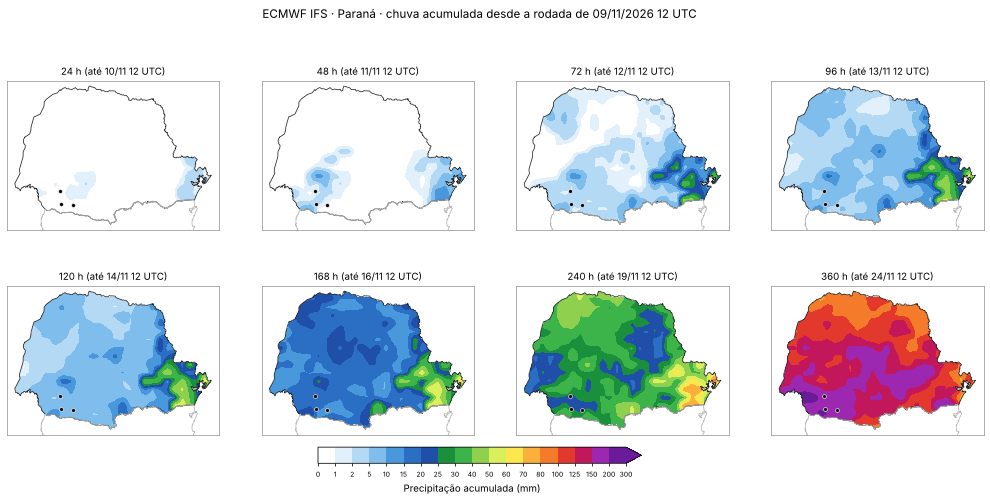

In [52]:
if PREV is not None:
    # Paraná em todos os horizontes da rodada: como a chuva prevista se acumula ao longo dos 15 dias
    hs = PREV['horizontes_h']
    fig, eixos = plt.subplots(2, int(np.ceil(len(hs) / 2)), figsize=(18, 7.5))
    for ax, h in zip(eixos.ravel(), hs):
        validade = PREV['rodada'] + pd.Timedelta(hours=h)
        cf = mapa_previsao(ax, PREV, h, ['Paraná'], titulo=f'{h} h (até {validade:%d/%m %H} UTC)', rotulos=False)
    for ax in eixos.ravel()[len(hs):]:
        ax.axis('off')
    cb = fig.colorbar(cf, ax=eixos, orientation='horizontal', fraction=0.04, pad=0.03, ticks=NIVEIS_CHUVA)
    cb.ax.tick_params(labelsize=7)
    cb.set_label('Precipitação acumulada (mm)')
    fig.suptitle(f"ECMWF IFS · Paraná · chuva acumulada desde a rodada de {PREV['rodada']:%d/%m/%Y %H} UTC", y=0.98)
    salva_fig(f'{PREFIXO_FIG}previsao_ecmwf_horizontes_parana.png')

**Previsão para os municípios.** Média da chuva prevista dentro do limite de cada município. A chuva **diária** é a diferença entre horizontes separados por 24 h, contada a partir do horário da rodada (rodada de 12 UTC: dias de 9h a 9h de Brasília, o mesmo intervalo de leitura dos pluviômetros convencionais).

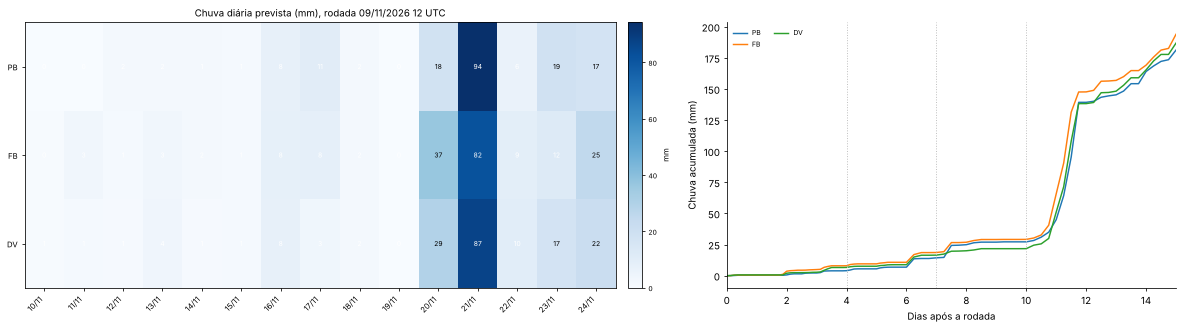

,24 h,48 h,72 h,96 h,120 h,168 h,240 h,360 h
Município,,,,,,,,
Pato Branco,0.3,0.6,2.2,4.0,5.5,14.4,27.2,181.2
Francisco Beltrão,0.5,3.6,4.9,8.0,9.5,18.6,29.2,193.9
Dois Vizinhos,0.6,2.0,2.8,6.6,7.6,16.5,21.7,186.8


In [53]:
if PREV is not None:
    serie_prev = pd.DataFrame(PREV['serie_municipios_mm']).set_index('fh').sort_index()[NOMES]
    diaria = serie_prev.loc[serie_prev.index.isin(range(0, 361, 24))].diff().dropna().clip(lower=0)
    diaria.index = [(PREV['rodada'] + pd.Timedelta(hours=int(h))).tz_convert('America/Sao_Paulo').strftime('%d/%m') for h in diaria.index]
    diaria.index.name = 'Dia (termina às 9h)'

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
    tab = diaria.T.copy(); tab.index = [SIGLA[n] for n in tab.index]
    mapa_calor(ax1, tab, fmt='{:.0f}', cmap='Blues', vmin=0, titulo=f"Chuva diária prevista (mm), rodada {PREV['rodada']:%d/%m/%Y %H} UTC", barra='mm', fonte=7)
    for n in NOMES:
        ax2.plot(serie_prev.index / 24, serie_prev[n], color=CORES_LOCAL[n], lw=1.5, label=SIGLA[n])
    for h in (96, 168, 240):
        ax2.axvline(h / 24, color='0.75', ls=':', lw=1)
    ax2.set_xlabel('Dias após a rodada'); ax2.set_ylabel('Chuva acumulada (mm)')
    ax2.set_xlim(0, 15); ax2.spines[['top', 'right']].set_visible(False); ax2.legend(frameon=False, ncol=2, fontsize=7)
    plt.tight_layout()
    salva_fig(f'{PREFIXO_FIG}previsao_ecmwf_municipios.png')

    tabela_prev = serie_prev.loc[[h for h in HORIZONTES if h in serie_prev.index]].T
    tabela_prev.columns = [f'{h} h' for h in tabela_prev.columns]
    tabela_prev.index.name = 'Município'
    tabela_prev.to_csv(os.path.join(PASTA_RESULTADOS, f'{PREFIXO_FIG}previsao_acumulada.csv'))
    diaria.to_csv(os.path.join(PASTA_RESULTADOS, f'{PREFIXO_FIG}previsao_diaria.csv'))
    display(tabela_prev.round(1))

    **Previsão no contexto do clima.** Quanto a chuva prevista para os próximos 15 dias representa da chuva normal do mesmo período? A normal é a média de 2001 a 2025 do BR-DWGD, para as mesmas datas do calendário. A ETo normal do período mostra se a chuva prevista deve cobrir a demanda da atmosfera, o que adianta a discussão do balanço hídrico do P2.

In [54]:
if PREV is not None:
    inicio = PREV['rodada'].tz_convert('America/Sao_Paulo').normalize().tz_localize(None) + pd.Timedelta(days=1)
    dias_prev = pd.date_range(inicio, periods=15)
    chave = set(zip(dias_prev.month, dias_prev.day))
    reg = []
    for n in NOMES:
        df = SERIES[n]
        sel = [(m, d) in chave for m, d in zip(df.index.month, df.index.day)]
        normal_p = df.loc[sel, 'pr'].sum() / N_ANOS
        normal_eto = df.loc[sel, 'ET'].sum() / N_ANOS
        prevista = serie_prev[n].loc[360] if 360 in serie_prev.index else np.nan
        reg.append({'Município': n, 'Chuva prevista 15 dias (mm)': prevista, 'Chuva normal (mm)': normal_p,
                    'Prevista / normal (%)': 100 * prevista / normal_p, 'ETo normal (mm)': normal_eto,
                    'Prevista − ETo normal (mm)': prevista - normal_eto})
    tabela_prev_clima = pd.DataFrame(reg).set_index('Município')
    tabela_prev_clima.to_csv(os.path.join(PASTA_RESULTADOS, f'{PREFIXO_FIG}previsao_vs_normal.csv'))
    print(f'Período comparado: {dias_prev[0]:%d/%m} a {dias_prev[-1]:%d/%m}')
    display(tabela_prev_clima.round(1))

Período comparado: 10/11 a 24/11


,Chuva prevista 15 dias (mm),Chuva normal (mm),Prevista / normal (%),ETo normal (mm),Prevista − ETo normal (mm)
Município,,,,,
Pato Branco,181.2,78.7,230.2,70.8,110.4
Francisco Beltrão,193.9,82.7,234.6,72.7,121.3
Dois Vizinhos,186.8,83.5,223.9,72.8,114.0


## Etapa 8 · Síntese dos resultados
___

O texto abaixo é montado a partir das tabelas calculadas neste notebook, então os números acompanham qualquer mudança nos dados ou nos pontos. Ele também é salvo em `resultados/sintese_resultados.md`.

In [55]:
def br(v, casas=2):
    return f'{v:.{casas}f}'.replace('.', ',')


def lista(valores, casas=2, un=''):
    # Faixa entre municípios: menor (sigla) a maior (sigla), e a média
    v = pd.Series(valores, dtype=float)
    if np.isclose(v.min(), v.max()):
        return f'{br(v.min(), casas)}{un} em todos os municípios'
    return (f'de {br(v.min(), casas)}{un} ({SIGLA[v.idxmin()]}) a {br(v.max(), casas)}{un} ({SIGLA[v.idxmax()]}), '
            f'média {br(v.mean(), casas)}{un}')


val3 = tabela3.xs('Validação', level='Conjunto')
S = ['# Síntese dos resultados do Projeto 1 (Sudoeste do Paraná)', '',
     'Siglas: ' + '; '.join(f'{SIGLA[n]} = {n}' for n in NOMES) + '. Os valores são dados como faixa entre os municípios (menor e maior) e média.', '']

S += ['**1. Base e clima.** '
      f"Foram extraídos {len(SERIES[NOMES[0]])} dias por local ({PERIODO}). O controle de qualidade descartou "
      + lista({n: relatorio_qc[n]['Dias com alguma falha'] for n in NOMES}, 0, ' dia(s)') + '. '
      'Chuva anual média do BR-DWGD (mm): ' + lista({n: CLIMA[n]['P'].sum() for n in NOMES}, 0) + '. '
      'ETo Penman-Monteith anual (mm): ' + lista({n: CLIMA[n]['ETo'].sum() for n in NOMES}, 0) + '. '
      'Temperatura média (°C): ' + lista({n: SERIES[n]['Tmed'].mean() for n in NOMES}, 1) + '. '
      'Classificação de Köppen pela própria série: ' + '; '.join(f'{k}: ' + ', '.join(SIGLA[n] for n in NOMES if KOPPEN[n] == k) for k in sorted(set(KOPPEN.values()))) + '. '
      'Período seco adotado (semestre quente): ' + '; '.join(sorted({f"{', '.join(MESES_ABREV[m - 1] for m in MESES_SECOS[n])} ({CRITERIO_SECO[n]})" for n in NOMES})) + '.', '']

S += ['**2. Balanço de radiação.** Médias em MJ m⁻² d⁻¹. '
      'Qo: ' + lista({n: SERIES[n]['Qo'].mean() for n in NOMES}) + '. '
      'Qg: ' + lista({n: SERIES[n]['Rs'].mean() for n in NOMES}) + '. '
      'BOL: ' + lista({n: SERIES[n]['BOL'].mean() for n in NOMES}) + '. '
      'Rn: ' + lista({n: SERIES[n]['Rn'].mean() for n in NOMES}) + '. '
      'Transmissividade média Qg/Qo: ' + lista({n: SERIES[n]['Kt'].mean() for n in NOMES}) + '. '
      'Rn no mês de menor valor: ' + lista({n: CLIM_RAD[n]['Rn'].min() for n in NOMES}, 1) + '; no de maior valor: '
      + lista({n: CLIM_RAD[n]['Rn'].max() for n in NOMES}, 1) + '.', '']

conta_melhor = pd.Series(MELHOR_QG).value_counts()
S += ['**3. Qg a partir da temperatura.** Melhor modelo pela EF na validação: '
      + '; '.join(f'{m} em {k} município(s) (' + ', '.join(SIGLA[n] for n in NOMES if MELHOR_QG[n] == m) + ')' for m, k in conta_melhor.items()) + '. '
      'Melhor modelo de cada município: RMSE ' + lista({n: val3.loc[(MELHOR_QG[n], n), 'RMSE'] for n in NOMES}, 2, ' MJ m⁻² d⁻¹')
      + '; RRMSE ' + lista({n: val3.loc[(MELHOR_QG[n], n), 'RRMSE_%'] for n in NOMES}, 1, '%')
      + '; índice c ' + lista({n: val3.loc[(MELHOR_QG[n], n), 'c'] for n in NOMES}, 3)
      + ' (' + ', '.join(sorted({val3.loc[(MELHOR_QG[n], n), 'Desempenho'].lower() for n in NOMES})) + '). '
      'Ordem dos modelos pela EF média dos municípios: ' + ' > '.join(f'{m} ({br(v, 3)})' for m, v in ranking['Média'].items()) + '. '
      f"A diferença de EF entre o melhor e o pior modelo é de {br(ranking['Média'].max() - ranking['Média'].min(), 3)}. "
      'Na escala mensal o índice c do melhor modelo sobe para ' + lista({n: tabela_dc.loc[(MELHOR_QG[n], n, 'Todo'), 'c_mensal'] for n in NOMES}, 3) + '. '
      'Índice c diário do melhor modelo no período seco: ' + lista({n: tabela_dc.loc[(MELHOR_QG[n], n, 'Seco'), 'c_diário'] for n in NOMES}, 3)
      + '; no úmido: ' + lista({n: tabela_dc.loc[(MELHOR_QG[n], n, 'Úmido'), 'c_diário'] for n in NOMES}, 3) + '.', '']

S += ['**4. Transferência de coeficientes.** '
      f"Usar em um local os coeficientes calibrados em outro aumentou o RMSE em no máximo {br(perda.loc[perda['Calibrado em'] != 'Regional', 'Aumento do RMSE (%)'].max(), 1)}% "
      f"(média de {br(perda.loc[perda['Calibrado em'] != 'Regional', 'Aumento do RMSE (%)'].mean(), 1)}%). "
      f"Com o conjunto regional único, o aumento médio foi de {br(perda.loc[perda['Calibrado em'] == 'Regional', 'Aumento do RMSE (%)'].mean(), 1)}% "
      f"e o máximo de {br(perda.loc[perda['Calibrado em'] == 'Regional', 'Aumento do RMSE (%)'].max(), 1)}%.", '']

valrn = tabela_rn.xs('Validação', level='Conjunto')
S += ['**5. Saldo de radiação.** Índice c na validação, por modelo: '
      + '; '.join(f"{m} " + lista({n: valrn.loc[(m, n), 'c'] for n in NOMES}, 3) for m in ORDEM_RN) + '. '
      'Coeficiente α do modelo (3), Rn = α·Qg: ' + lista({n: PAR_RN[n]['(3)'][0] for n in NOMES}, 3) + '. '
      'Razão Rn/Qg no mês de menor valor (inverno): ' + lista({n: RAZAO[n].min() for n in NOMES}) + '; no de maior valor (verão): ' + lista({n: RAZAO[n].max() for n in NOMES}) + '.', '']

S += ['**6. Priestley-Taylor.** Equação local ET₀ = k·W·Qg com k: ' + lista(K_LOCAL, 4) + '. '
      'RMSE em relação à Penman-Monteith na validação (mm d⁻¹), com Rn FAO-56: '
      + lista({n: tabela_pt.loc[(n, 'Priestley-Taylor (Rn FAO-56, W linear)'), 'RMSE'] for n in NOMES}) + '; com a equação local: '
      + lista({n: tabela_pt.loc[(n, 'Equação local k·W·Qg'), 'RMSE'] for n in NOMES}) + '. '
      'Viés de Priestley-Taylor com Rn FAO-56 (mm d⁻¹): ' + lista({n: tabela_pt.loc[(n, 'Priestley-Taylor (Rn FAO-56, W linear)'), 'Viés'] for n in NOMES}) + '. '
      'α_PT recalibrado (ano todo): ' + lista(tabela_alfa['Todo'].to_dict(), 3) + '; semestre quente (período seco): ' + lista(tabela_alfa['Seco'].to_dict(), 3)
      + '; semestre frio (período úmido): ' + lista(tabela_alfa['Úmido'].to_dict(), 3) + '.', '']

S += ['**7. Pergunta central: só com termômetro, quanto erro chega à ETo?** RMSE na validação (mm d⁻¹). '
      'Cenário (a), Qg e Rn de referência: ' + lista(tabela_elo['RMSE (a)'].to_dict()) + '. '
      'Cenário (b), só temperatura: ' + lista(tabela_elo['RMSE (b)'].to_dict()) + ' (índice c '
      + lista({n: tabela5.loc[(n, '(b)'), 'c'] for n in NOMES}, 3) + '; '
      + ', '.join(sorted({tabela5.loc[(n, '(b)'), 'Desempenho'].lower() for n in NOMES})) + '). '
      'Cenário (c), Hargreaves-Samani: ' + lista(tabela_elo['RMSE (c)'].to_dict()) + ' (viés '
      + lista({n: tabela5.loc[(n, '(c)'), 'Viés'] for n in NOMES}) + '). '
      'Do erro quadrático de (b), a parcela que nasce na estimativa de Qg é ' + lista(tabela_elo['Qg por temperatura (%)'].to_dict(), 0, '%')
      + '; a troca do Rn FAO-56 por α·Qg responde por ' + lista(tabela_elo['Rn = α·Qg (%)'].to_dict(), 0, '%')
      + '; o restante (' + lista(tabela_elo['PT + W + Rn FAO-56 (%)'].to_dict(), 0, '%') + ') já existe com Qg de referência. '
      'Nos totais mensais o RMSE de (b) é ' + lista({n: tabela_acum.loc[(n, '(b)'), 'RMSE mensal (mm)'] for n in NOMES}, 1, ' mm')
      + ' (RRMSE ' + lista({n: tabela_acum.loc[(n, '(b)'), 'RRMSE mensal (%)'] for n in NOMES}, 1, '%') + ') e o viés anual é '
      + lista({n: tabela_acum.loc[(n, '(b)'), 'Viés anual (%)'] for n in NOMES}, 1, '%') + '.', '']

n_fase = safras[safras['Local'] == NOMES[0]]['Fase'].value_counts()
S += ['**8. ENOS (safra de outubro a março).** '
      f"{len(ONI_NDJ)} safras: {n_fase.get('El Niño', 0)} de El Niño, {n_fase.get('La Niña', 0)} de La Niña e {n_fase.get('Neutro', 0)} neutras. "
      'Diferença média El Niño − La Niña na chuva (mm): ' + lista({n: testes_enos.loc[(n, 'Chuva (mm)'), 'El Niño − La Niña'] for n in NOMES}, 0)
      + ' (Kruskal-Wallis p: ' + lista({n: testes_enos.loc[(n, 'Chuva (mm)'), 'Kruskal-Wallis p'] for n in NOMES}, 3) + '). '
      'Na Qg (MJ m⁻² d⁻¹): ' + lista({n: testes_enos.loc[(n, 'Qg (MJ m⁻² d⁻¹)'), 'El Niño − La Niña'] for n in NOMES})
      + ' (p: ' + lista({n: testes_enos.loc[(n, 'Qg (MJ m⁻² d⁻¹)'), 'Kruskal-Wallis p'] for n in NOMES}, 3) + '). '
      'Na ETo (mm): ' + lista({n: testes_enos.loc[(n, 'ETo PM (mm)'), 'El Niño − La Niña'] for n in NOMES}, 0)
      + ' (p: ' + lista({n: testes_enos.loc[(n, 'ETo PM (mm)'), 'Kruskal-Wallis p'] for n in NOMES}, 3) + '). '
      'RMSE do melhor modelo de Qg, média dos municípios, em safras de La Niña, neutras e de El Niño: '
      + '/'.join(br(media_fase.xs(f, level=1)['RMSE Qg (MJ m⁻² d⁻¹)'].mean()) for f in FASES)
      + ' (p: ' + lista({n: testes_enos.loc[(n, 'RMSE Qg (MJ m⁻² d⁻¹)'), 'Kruskal-Wallis p'] for n in NOMES}, 3) + '). '
      'Com poucas safras por fase, valores de p acima de 0,05 significam que a diferença não se distingue da variação entre anos. '
      'Municípios com correlação de Spearman significativa (p < 0,05) entre o ONI e a chuva: '
      + (', '.join(SIGLA[n] for n in NOMES if testes_enos.loc[(n, 'Chuva (mm)'), 'Spearman p'] < 0.05) or 'nenhum') + '; com a Qg: '
      + (', '.join(SIGLA[n] for n in NOMES if testes_enos.loc[(n, 'Qg (MJ m⁻² d⁻¹)'), 'Spearman p'] < 0.05) or 'nenhum') + '.', '']

if PREV is not None:
  S += ['**9. Previsão ECMWF IFS (Etapa 7).** '
      f"Rodada de {PREV['rodada']:%d/%m/%Y %H} UTC. Chuva acumulada prevista em {HORIZONTE_H} h (mm): "
      + lista({n: serie_prev.loc[HORIZONTE_H, n] for n in NOMES}, 0) + '; em 15 dias: '
      + lista(tabela_prev_clima['Chuva prevista 15 dias (mm)'].to_dict(), 0) + ', o que equivale a '
      + lista(tabela_prev_clima['Prevista / normal (%)'].to_dict(), 0, '%') + ' da chuva normal do mesmo período '
      f"({dias_prev[0]:%d/%m} a {dias_prev[-1]:%d/%m}). A previsão muda a cada rodada; estes números valem só para a rodada indicada.", '']

S += ['**Ressalvas.** A Qg do BR-DWGD é interpolada de estações, não medida no ponto. O Rn de referência é calculado pela FAO-56 '
      '(Fietz & Fisch usaram saldo-radiômetro), então os modelos de Rn que usam Qg partem em vantagem, porque o próprio Rn de referência foi '
      'calculado com Qg. A ETo de referência é a Penman-Monteith do próprio BR-DWGD, que também depende da mesma Qg. '
      'A Etapa 1b (comparação com a estação) só entra quando os arquivos da estação estiverem na pasta.']

sintese = '\n'.join(S)
with open(os.path.join(PASTA_RESULTADOS, 'sintese_resultados.md'), 'w', encoding='utf-8') as f:
    f.write(sintese)
from IPython.display import Markdown
display(Markdown(sintese))

# Síntese dos resultados do Projeto 1 (Sudoeste do Paraná)

Siglas: PB = Pato Branco; FB = Francisco Beltrão; DV = Dois Vizinhos. Os valores são dados como faixa entre os municípios (menor e maior) e média.

**1. Base e clima.** Foram extraídos 9131 dias por local (2001 a 2025). O controle de qualidade descartou 0 dia(s) em todos os municípios. Chuva anual média do BR-DWGD (mm): de 1848 (PB) a 1947 (FB), média 1895. ETo Penman-Monteith anual (mm): de 1262 (PB) a 1293 (DV), média 1281. Temperatura média (°C): de 20,7 (PB) a 20,8 (FB), média 20,7. Classificação de Köppen pela própria série: Cfa: PB, FB, DV. Período seco adotado (semestre quente): Jan, Fev, Mar, Abr, Nov, Dez (6 meses contínuos de menor P − ETo).

**2. Balanço de radiação.** Médias em MJ m⁻² d⁻¹. Qo: de 32,89 (PB) a 32,99 (DV), média 32,92. Qg: de 16,78 (PB) a 16,96 (DV), média 16,89. BOL: de -3,06 (FB) a -3,00 (PB), média -3,04. Rn: de 9,92 (PB) a 10,01 (DV), média 9,97. Transmissividade média Qg/Qo: de 0,51 (PB) a 0,52 (FB), média 0,51. Rn no mês de menor valor: de 4,9 (PB) a 5,0 (DV), média 4,9; no de maior valor: de 14,2 (PB) a 14,3 (FB), média 14,3.

**3. Qg a partir da temperatura.** Melhor modelo pela EF na validação: CD em 2 município(s) (FB, DV); BC em 1 município(s) (PB). Melhor modelo de cada município: RMSE de 3,55 MJ m⁻² d⁻¹ (DV) a 3,78 MJ m⁻² d⁻¹ (FB), média 3,69 MJ m⁻² d⁻¹; RRMSE de 20,7% (DV) a 22,3% (PB), média 21,7%; índice c de 0,786 (PB) a 0,810 (DV), média 0,795 (muito bom). Ordem dos modelos pela EF média dos municípios: CD (0,739) > BC (0,736) > DB (0,729) > DCBB (0,725) > HG (0,657). A diferença de EF entre o melhor e o pior modelo é de 0,081. Na escala mensal o índice c do melhor modelo sobe para de 0,918 (FB) a 0,933 (PB), média 0,927. Índice c diário do melhor modelo no período seco: de 0,754 (FB) a 0,767 (DV), média 0,759; no úmido: de 0,688 (PB) a 0,738 (DV), média 0,708.

**4. Transferência de coeficientes.** Usar em um local os coeficientes calibrados em outro aumentou o RMSE em no máximo 3,7% (média de 0,9%). Com o conjunto regional único, o aumento médio foi de 0,4% e o máximo de 1,6%.

**5. Saldo de radiação.** Índice c na validação, por modelo: (1) de 0,522 (DV) a 0,539 (PB), média 0,533; (2) de 0,851 (PB) a 0,853 (FB), média 0,853; (3) de 0,932 (PB) a 0,934 (DV), média 0,933; (4) de 0,962 (FB) a 0,963 (DV), média 0,962. Coeficiente α do modelo (3), Rn = α·Qg: de 0,590 (FB) a 0,591 (PB), média 0,591. Razão Rn/Qg no mês de menor valor (inverno): de 0,47 (FB) a 0,47 (DV), média 0,47; no de maior valor (verão): de 0,65 (FB) a 0,65 (PB), média 0,65.

**6. Priestley-Taylor.** Equação local ET₀ = k·W·Qg com k: de 0,3033 (FB) a 0,3041 (PB), média 0,3038. RMSE em relação à Penman-Monteith na validação (mm d⁻¹), com Rn FAO-56: de 0,57 (FB) a 0,59 (DV), média 0,58; com a equação local: de 0,50 (FB) a 0,51 (PB), média 0,50. Viés de Priestley-Taylor com Rn FAO-56 (mm d⁻¹): de 0,05 (DV) a 0,09 (PB), média 0,06. α_PT recalibrado (ano todo): de 1,197 (PB) a 1,212 (DV), média 1,206; semestre quente (período seco): de 1,152 (PB) a 1,163 (FB), média 1,159; semestre frio (período úmido): de 1,329 (PB) a 1,355 (DV), média 1,344.

**7. Pergunta central: só com termômetro, quanto erro chega à ETo?** RMSE na validação (mm d⁻¹). Cenário (a), Qg e Rn de referência: de 0,57 (FB) a 0,59 (DV), média 0,58. Cenário (b), só temperatura: de 0,67 (DV) a 0,72 (PB), média 0,70 (índice c de 0,841 (PB) a 0,864 (DV), média 0,851; muito bom, ótimo). Cenário (c), Hargreaves-Samani: de 0,81 (FB) a 0,84 (DV), média 0,83 (viés de 0,36 (FB) a 0,47 (DV), média 0,41). Do erro quadrático de (b), a parcela que nasce na estimativa de Qg é de 43% (DV) a 51% (FB), média 48%; a troca do Rn FAO-56 por α·Qg responde por de -20% (DV) a -16% (FB), média -17%; o restante (de 65% (FB) a 77% (DV), média 69%) já existe com Qg de referência. Nos totais mensais o RMSE de (b) é de 9,1 mm (DV) a 10,2 mm (FB), média 9,8 mm (RRMSE de 8,3% (DV) a 9,4% (FB), média 9,1%) e o viés anual é de 1,1% (FB) a 1,6% (PB), média 1,3%.

**8. ENOS (safra de outubro a março).** 24 safras: 9 de El Niño, 9 de La Niña e 6 neutras. Diferença média El Niño − La Niña na chuva (mm): de 81 (DV) a 182 (FB), média 135 (Kruskal-Wallis p: de 0,122 (PB) a 0,661 (DV), média 0,340). Na Qg (MJ m⁻² d⁻¹): de -1,09 (DV) a -0,98 (PB), média -1,05 (p: de 0,094 (PB) a 0,110 (DV), média 0,103). Na ETo (mm): de -46 (DV) a -40 (PB), média -44 (p: de 0,182 (FB) a 0,291 (PB), média 0,232). RMSE do melhor modelo de Qg, média dos municípios, em safras de La Niña, neutras e de El Niño: 4,06/3,77/3,90 (p: de 0,472 (FB) a 0,848 (PB), média 0,644). Com poucas safras por fase, valores de p acima de 0,05 significam que a diferença não se distingue da variação entre anos. Municípios com correlação de Spearman significativa (p < 0,05) entre o ONI e a chuva: PB, FB; com a Qg: PB, FB, DV.

**9. Previsão ECMWF IFS (Etapa 7).** Rodada de 09/11/2026 12 UTC. Chuva acumulada prevista em 96 h (mm): de 4 (PB) a 8 (FB), média 6; em 15 dias: de 181 (PB) a 194 (FB), média 187, o que equivale a de 224% (DV) a 235% (FB), média 230% da chuva normal do mesmo período (10/11 a 24/11). A previsão muda a cada rodada; estes números valem só para a rodada indicada.

**Ressalvas.** A Qg do BR-DWGD é interpolada de estações, não medida no ponto. O Rn de referência é calculado pela FAO-56 (Fietz & Fisch usaram saldo-radiômetro), então os modelos de Rn que usam Qg partem em vantagem, porque o próprio Rn de referência foi calculado com Qg. A ETo de referência é a Penman-Monteith do próprio BR-DWGD, que também depende da mesma Qg. A Etapa 1b (comparação com a estação) só entra quando os arquivos da estação estiverem na pasta.

### Tabelas para o relatório

Gera `resultados/tabelas_relatorio.md` com as tabelas do relatório (`relatorio/relatorio_p1_sudoeste.md`) já formatadas em Markdown, com vírgula decimal.

In [56]:
def tabela_md(df, casas=3):
    # Converte um DataFrame em tabela Markdown com vírgula decimal (sem depender do pacote tabulate)
    df = df.reset_index()

    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return '' if np.isnan(v) else f'{v:.{casas}f}'.replace('.', ',')
        return str(v)

    linhas = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    linhas += ['| ' + ' | '.join(fmt(v) for v in linha) + ' |' for linha in df.itertuples(index=False)]
    return '\n'.join(linhas)


clima_tab = tabela_clima.copy()
clima_tab.columns = [f'{a} {b}' for a, b in clima_tab.columns]
clima_tab.index.name = 'Mês'
rad_tab = pd.DataFrame({n: SERIES[n][VARS_RAD].mean() for n in NOMES})
rad_tab.index = ['Qo', 'Qg', 'Qg,cs', 'BOC', 'BOL', 'Rn']; rad_tab.index.name = 'Componente'
val3t = tabela3.xs('Validação', level='Conjunto')[['RMSE', 'RRMSE_%', 'MAE', 'Viés', 'EF', 'R2', 'd', 'c', 'Desempenho']]
blocos = {
    'Tabela 1. Locais de estudo': (tabela1, 2),
    'Tabela 2. Controle de qualidade (número de dias)': (tabela_qc, 0),
    'Tabela 4. Climatologia mensal: chuva (P, mm), ETo (mm) e temperatura média (T, °C)': (clima_tab, 1),
    'Tabela 5. Balanço de radiação médio (MJ m⁻² d⁻¹)': (rad_tab, 2),
    'Tabela 6. Parâmetros calibrados dos modelos de Qg': (tabela2, 4),
    'Tabela 7. Desempenho dos modelos de Qg na validação (anos pares)': (val3t, 3),
    'Tabela 8. Índice c por período (série completa, escala diária)':
        (tabela_dc['c_diário'].unstack('Período')[['Todo', 'Seco', 'Úmido']], 3),
    'Tabela 9. Índice c por período (série completa, escala mensal)':
        (tabela_dc['c_mensal'].unstack('Período')[['Todo', 'Seco', 'Úmido']], 3),
    'Tabela 10. RMSE (MJ m⁻² d⁻¹) com coeficientes transferidos entre locais': (transf, 3),
    'Tabela 11. Parâmetros regionais dos modelos de Qg (todos os municípios juntos)': (tabela_reg, 4),
    'Tabela 12. Parâmetros dos modelos de Rn': (tabela_par_rn, 4),
    'Tabela 13. Desempenho dos modelos de Rn na validação':
        (tabela_rn.xs('Validação', level='Conjunto')[['Rn médio', 'CV_%', 'RMSE', 'EF', 'R2', 'd', 'c', 'Desempenho']], 3),
    'Tabela 14. Razão Rn/Qg mensal': (tabela_razao, 3),
    'Tabela 15. Priestley-Taylor × Penman-Monteith (validação)':
        (tabela_pt[['RMSE', 'Viés', 'EF', 'R2', 'd', 'c', 'Desempenho']], 3),
    'Tabela 16. αPT recalibrado por período': (tabela_alfa, 3),
    'Tabela 17. ETo estimada × Penman-Monteith (validação, escala diária)':
        (tabela5[['Descrição', 'RMSE', 'Viés', 'EF', 'R2', 'd', 'c', 'Desempenho']], 3),
    'Tabela 18. Origem do erro da cadeia só com temperatura': (tabela_elo, 3),
    'Tabela 19. ETo acumulada: totais mensais e anuais (validação)': (tabela_acum, 2),
    'Tabela 20. Safra de verão (out a mar) por fase do ENOS: médias': (media_fase, 2),
    'Tabela 21. ENOS: diferença El Niño − La Niña e testes': (testes_enos, 3),
}
if PREV is not None:
    blocos[f"Tabela 22. Previsão ECMWF IFS: chuva acumulada (mm), rodada {PREV['rodada']:%d/%m/%Y %H} UTC"] = (tabela_prev, 1)
    blocos['Tabela 23. Previsão de 15 dias × normal do período'] = (tabela_prev_clima, 1)
if tabela_inmet is not None:
    blocos = dict(list(blocos.items())[:2] + [('Tabela 3. BR-DWGD × estação', (tabela_inmet, 3))] + list(blocos.items())[2:])
texto = [f'# Tabelas do relatório P1 ({PERIODO})\n']
for titulo, (df, casas) in blocos.items():
    texto += [f'**{titulo}**\n', tabela_md(df, casas), '']
texto += ['**Equação local (Etapa 4):** ' + '; '.join(f'{n}: ET₀ = {br(K_LOCAL[n], 4)}·W·Qg' for n in NOMES),
          '', '**Melhor modelo de Qg (EF na validação):** ' + ', '.join(f'{n}: {m}' for n, m in MELHOR_QG.items())]

arq_md = os.path.join(PASTA_RESULTADOS, 'tabelas_relatorio.md')
with open(arq_md, 'w', encoding='utf-8') as f:
    f.write('\n'.join(texto))
print('Tabelas salvas em:', arq_md)
print('Figuras geradas:', len(os.listdir(PASTA_FIGURAS)))

Tabelas salvas em: ./resultados/tabelas_relatorio.md
Figuras geradas: 28


### Referências

ALLEN, R. G.; PEREIRA, L. S.; RAES, D.; SMITH, M. **Crop evapotranspiration**: guidelines for computing crop water requirements. Rome: FAO, 1998. (Irrigation and Drainage Paper, 56).

ALVARES, C. A. et al. Köppen's climate classification map for Brazil. **Meteorologische Zeitschrift**, v. 22, n. 6, p. 711-728, 2013.

CAMARGO, A. P.; SENTELHAS, P. C. Avaliação do desempenho de diferentes métodos de estimativa da evapotranspiração potencial no Estado de São Paulo, Brasil. **Revista Brasileira de Agrometeorologia**, v. 5, n. 1, p. 89-97, 1997.

FERNANDES, D. S.; HEINEMANN, A. B.; AMORIM, A. O.; PAZ, R. L. F. Estimativa da radiação solar global com base em observações de temperatura para o estado de Goiás. **Revista Brasileira de Meteorologia**, v. 33, n. 3, p. 558-566, 2018.

FIETZ, C. R.; FISCH, G. F. Avaliação de modelos de estimativa do saldo de radiação e do método de Priestley-Taylor para a região de Dourados, MS. **Revista Brasileira de Engenharia Agrícola e Ambiental**, v. 13, n. 4, p. 449-453, 2009.

FUNK, C. et al. The climate hazards infrared precipitation with stations: a new environmental record for monitoring extremes. **Scientific Data**, v. 2, 150066, 2015.

ECMWF. **IFS operational forecasts (open data)**, disponível no Google Earth Engine como `ECMWF/NRT_FORECAST/IFS/OPER`. Acesso em: 9 nov. 2026.

NOAA CLIMATE PREDICTION CENTER. **Oceanic Niño Index (ONI)**. Disponível em: https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt. Acesso em: 9 nov. 2026.

WILLMOTT, C. J. On the validation of models. **Physical Geography**, v. 2, n. 2, p. 184-194, 1981.

XAVIER, A. C.; SCANLON, B. R.; KING, C. W.; ALVES, A. I. New improved Brazilian daily weather gridded data (1961-2020). **International Journal of Climatology**, v. 42, n. 16, p. 8390-8404, 2022.